# 06. Model 2 — CatBoost: Audited Nested Evaluation

**Academic Project Evaluation · Faculty Panel Technical Walkthrough · Model 2: CatBoost**

This notebook provides a formal, fully reproducible technical audit and evaluation walkthrough of the CatBoost headline pipeline for binary employee resignation prediction (`Resigned`).

All heavy computational workloads (5-fold nested cross-validation with 3-seed inner candidate search, full row-paired bootstrap inference, empirical label-permutation hypothesis testing, reliability calibration, and diagnostics) are pre-executed and cryptographically tracked. This walkthrough operates in **read-only verification mode** by default: it dynamically loads verified serialized artifacts, recalculates every metric directly from saved out-of-fold (OOF) prediction vectors, asserts exact mathematical reconciliation against project contracts, and presents evidence-based findings with zero hardcoded values.

**Core Architectural Boundaries:**
- **Holdout Quarantine:** The 20,000-row formal holdout partition is strictly quarantined (labels and features are never loaded or parsed into memory; only ID sets are checked to prove zero partition overlap).
- **Strict Leakage Prevention:** Every transformation, categorical target statistic, hyperparameter tuning step, and early-stopping decision is strictly fold-local within outer training partitions.
- **Feature Governance:** `configs/feature_contract.yaml` (17 approved predictors) and `configs/split_config.yaml` are strictly enforced as frozen project contracts.

## 1. Setup and Execution Switch

- **Academic Objective:** Initialize the execution environment, import verified dependencies, resolve project root anchors, and configure the dual-mode audit/review execution switch.
- **Key Methodology / Theory:** Scientific reproducibility requires strict control over random number generation (`random_seed=42`) and environment state. To support rapid academic examination without requiring an hour of retraining on every notebook load, the execution switch `RUN_CATBOOST_AUDIT = False` runs in instant read-only audit review mode, while setting it to `True` re-executes the full end-to-end training pipeline (`scripts/run_catboost_audit.py`).
- **Expected Panel Takeaway:** Deterministic environment established across CatBoost, Scikit-Learn, and Pandas; read-only review mode enables zero-mutation inspection of all verified audit artifacts.

In [11]:
# Import standard library modules
import json
import subprocess
import sys
from pathlib import Path

# Import data science and machine learning libraries
import catboost
import numpy as np
import pandas as pd
import sklearn
import yaml

# Import IPython display utilities
from IPython.display import Image, Markdown, display

# Configure pandas tabular display formatting
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.5f}")


# Helper function to locate repository root via feature contract anchor
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the repository root (configs/feature_contract.yaml).")


# Resolve project root and register in Python path
PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import evaluation statistics and CatBoost protocol builders
from src.evaluation.audit_stats import load_audit_inputs, metric_row, permutation_pvalue
from src.models.catboost_protocol import build_config

# Execution switch: False for read-only audit review, True for full retraining
RUN_CATBOOST_AUDIT = False

# Define canonical artifact directory paths
CB = PROJECT_ROOT / "results" / "models" / "catboost"
IMP = CB / "improvement"
P1 = IMP / "phase1"
FIN = IMP / "final"

# Display execution environment and seed configuration
print(f"Project root : {PROJECT_ROOT}")
print(f"Python       : {sys.version.split()[0]} | catboost {catboost.__version__} | scikit-learn {sklearn.__version__} "
      f"| pandas {pd.__version__} | numpy {np.__version__}")
print("Seed 42, CPU only (task_type=CPU), thread_count=-1; same seed reproduces OOF predictions exactly (see section 6).")
print(f"Mode         : {'AUDIT RUN' if RUN_CATBOOST_AUDIT else 'REVIEW (read-only)'}")


Project root : E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project
Python       : 3.14.7 | catboost 1.2.10 | scikit-learn 1.9.0 | pandas 3.0.5 | numpy 2.5.2
Seed 42, CPU only (task_type=CPU), thread_count=-1; same seed reproduces OOF predictions exactly (see section 6).
Mode         : REVIEW (read-only)


In [12]:
# Execute full audit subprocess if requested; otherwise verify required review artifacts exist
if RUN_CATBOOST_AUDIT:
    subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "run_catboost_audit.py")], check=True, cwd=PROJECT_ROOT)
else:
    missing = [p.name for p in (FIN / "metrics_summary.csv", FIN / "oof_catboost_final.csv", FIN / "figure_index.json") if not p.exists()]
    assert not missing, f"Run `python scripts/run_catboost_audit.py` first; missing {missing}"
    print("Review mode: reading saved artifacts only (no fitting, no file writes).")

# Load figure index mapping figure keys to relative file paths
figure_index = json.loads((FIN / "figure_index.json").read_text(encoding="utf-8"))


# Standardized figure rendering utility with academic takeaway annotations
def show_fig(key: str, takeaway: str) -> None:
    """Display one saved figure with its one-sentence takeaway."""
    if key not in figure_index:
        display(Markdown(f"*Figure `{key}` was not drawn for this run (see its guard condition in the audit script).*"))
        return
    display(Image(filename=str(PROJECT_ROOT / figure_index[key]), width=880))
    display(Markdown(f"**Takeaway.** {takeaway}"))


Review mode: reading saved artifacts only (no fitting, no file writes).


## 2. Data Ingestion, Holdout Quarantine, and Class Balance Validation

- **Academic Objective:** Validate development dataset ingestion, mathematically enforce the strict quarantine of the 20,000 holdout rows, and audit cross-validation fold balance under severe class imbalance.
- **Key Methodology / Theory:** Data leakage from holdout sets invalidates generalization claims. `load_audit_inputs` verifies SHA-256 checksums of the raw dataset and split registry; holdout rows are skipped before predictors or labels can be parsed. Given the 10.01% empirical positive class rate (~9.0:1 negative-to-positive ratio), Stratified 5-Fold Cross-Validation (16,000 rows per fold) is mandatory so that each outer training (64,000 rows) and outer validation fold preserves the exact population distribution.
- **Expected Panel Takeaway:** Disjoint 80,000 development / 20,000 holdout split verified with 0 ID overlap, zero missing predictor cells, and identical fold-wise stratification (10.01% ± 0.05%).

In [13]:
# Load hash-verified development data, split registry, and feature lists
data, split, features, categorical = load_audit_inputs(PROJECT_ROOT)

# Extract disjoint partition IDs from the split registry
holdout_ids = set(split.loc[split.partition == "holdout", "Employee_ID"])
dev_ids = set(split.loc[split.partition == "development", "Employee_ID"])

# Calculate outer fold record counts and fold-level positive rates
fold_sizes = data.groupby("cv_fold").size()
fold_rate = data.groupby("cv_fold").Resigned.mean()

# Compute empirical target prevalence and class imbalance ratio
prevalence = float(data.Resigned.mean())
imbalance_ratio = (1 - prevalence) / prevalence

# Assert zero ID overlap between development and quarantined holdout partitions
assert dev_ids == set(data.Employee_ID) and not (holdout_ids & set(data.Employee_ID)), "development/holdout overlap"

# Assert unique identifiers and complete predictor columns with zero missing values
assert data.Employee_ID.is_unique and int(data[features].isna().sum().sum()) == 0

# Assert outer folds have identical record counts
assert fold_sizes.nunique() == 1, "outer folds must be equal-sized"

# Display dataset split and data integrity summary table
display(pd.DataFrame({
    "development rows": [len(data)], "registry holdout IDs (labels never parsed)": [len(holdout_ids)],
    "ID overlap": [len(holdout_ids & dev_ids)], "outer folds": [fold_sizes.size], "rows per fold": [int(fold_sizes.iloc[0])],
    "missing predictor cells": [int(data[features].isna().sum().sum())], "positive rate": [prevalence],
    "negative:positive ratio": [imbalance_ratio],
}).T.rename(columns={0: "value"}))

# Display fold-by-fold row counts and stratified positive rates
display(pd.DataFrame({"rows": fold_sizes, "positive rate": fold_rate}))

# Display class imbalance and evaluation protocol notes
display(Markdown(
    f"**Class imbalance.** About {prevalence:.2%} of development employees resigned (ratio {imbalance_ratio:.1f}:1). "
    f"Stratified folds keep every fold's positive rate within {fold_rate.min():.4%}–{fold_rate.max():.4%}. No resampling is applied; "
    "imbalance is handled by (i) ranking metrics that are prevalence-aware (PR-AUC against the no-skill line, lift@k), "
    "(ii) probability metrics (Brier, log loss) against a prevalence-only reference, and (iii) the class-weight experiments in section 7."))


Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,value
development rows,80000.00000
registry holdout IDs (labels never parsed),20000.00000
ID overlap,0.00000
outer folds,5.00000
rows per fold,16000.00000
missing predictor cells,0.00000
positive rate,0.10010
negative:positive ratio,8.99001


,rows,positive rate
cv_fold,,
1,16000,0.10006
2,16000,0.10006
3,16000,0.10013
4,16000,0.10013
5,16000,0.10013


**Class imbalance.** About 10.01% of development employees resigned (ratio 9.0:1). Stratified folds keep every fold's positive rate within 10.0062%–10.0125%. No resampling is applied; imbalance is handled by (i) ranking metrics that are prevalence-aware (PR-AUC against the no-skill line, lift@k), (ii) probability metrics (Brier, log loss) against a prevalence-only reference, and (iii) the class-weight experiments in section 7.

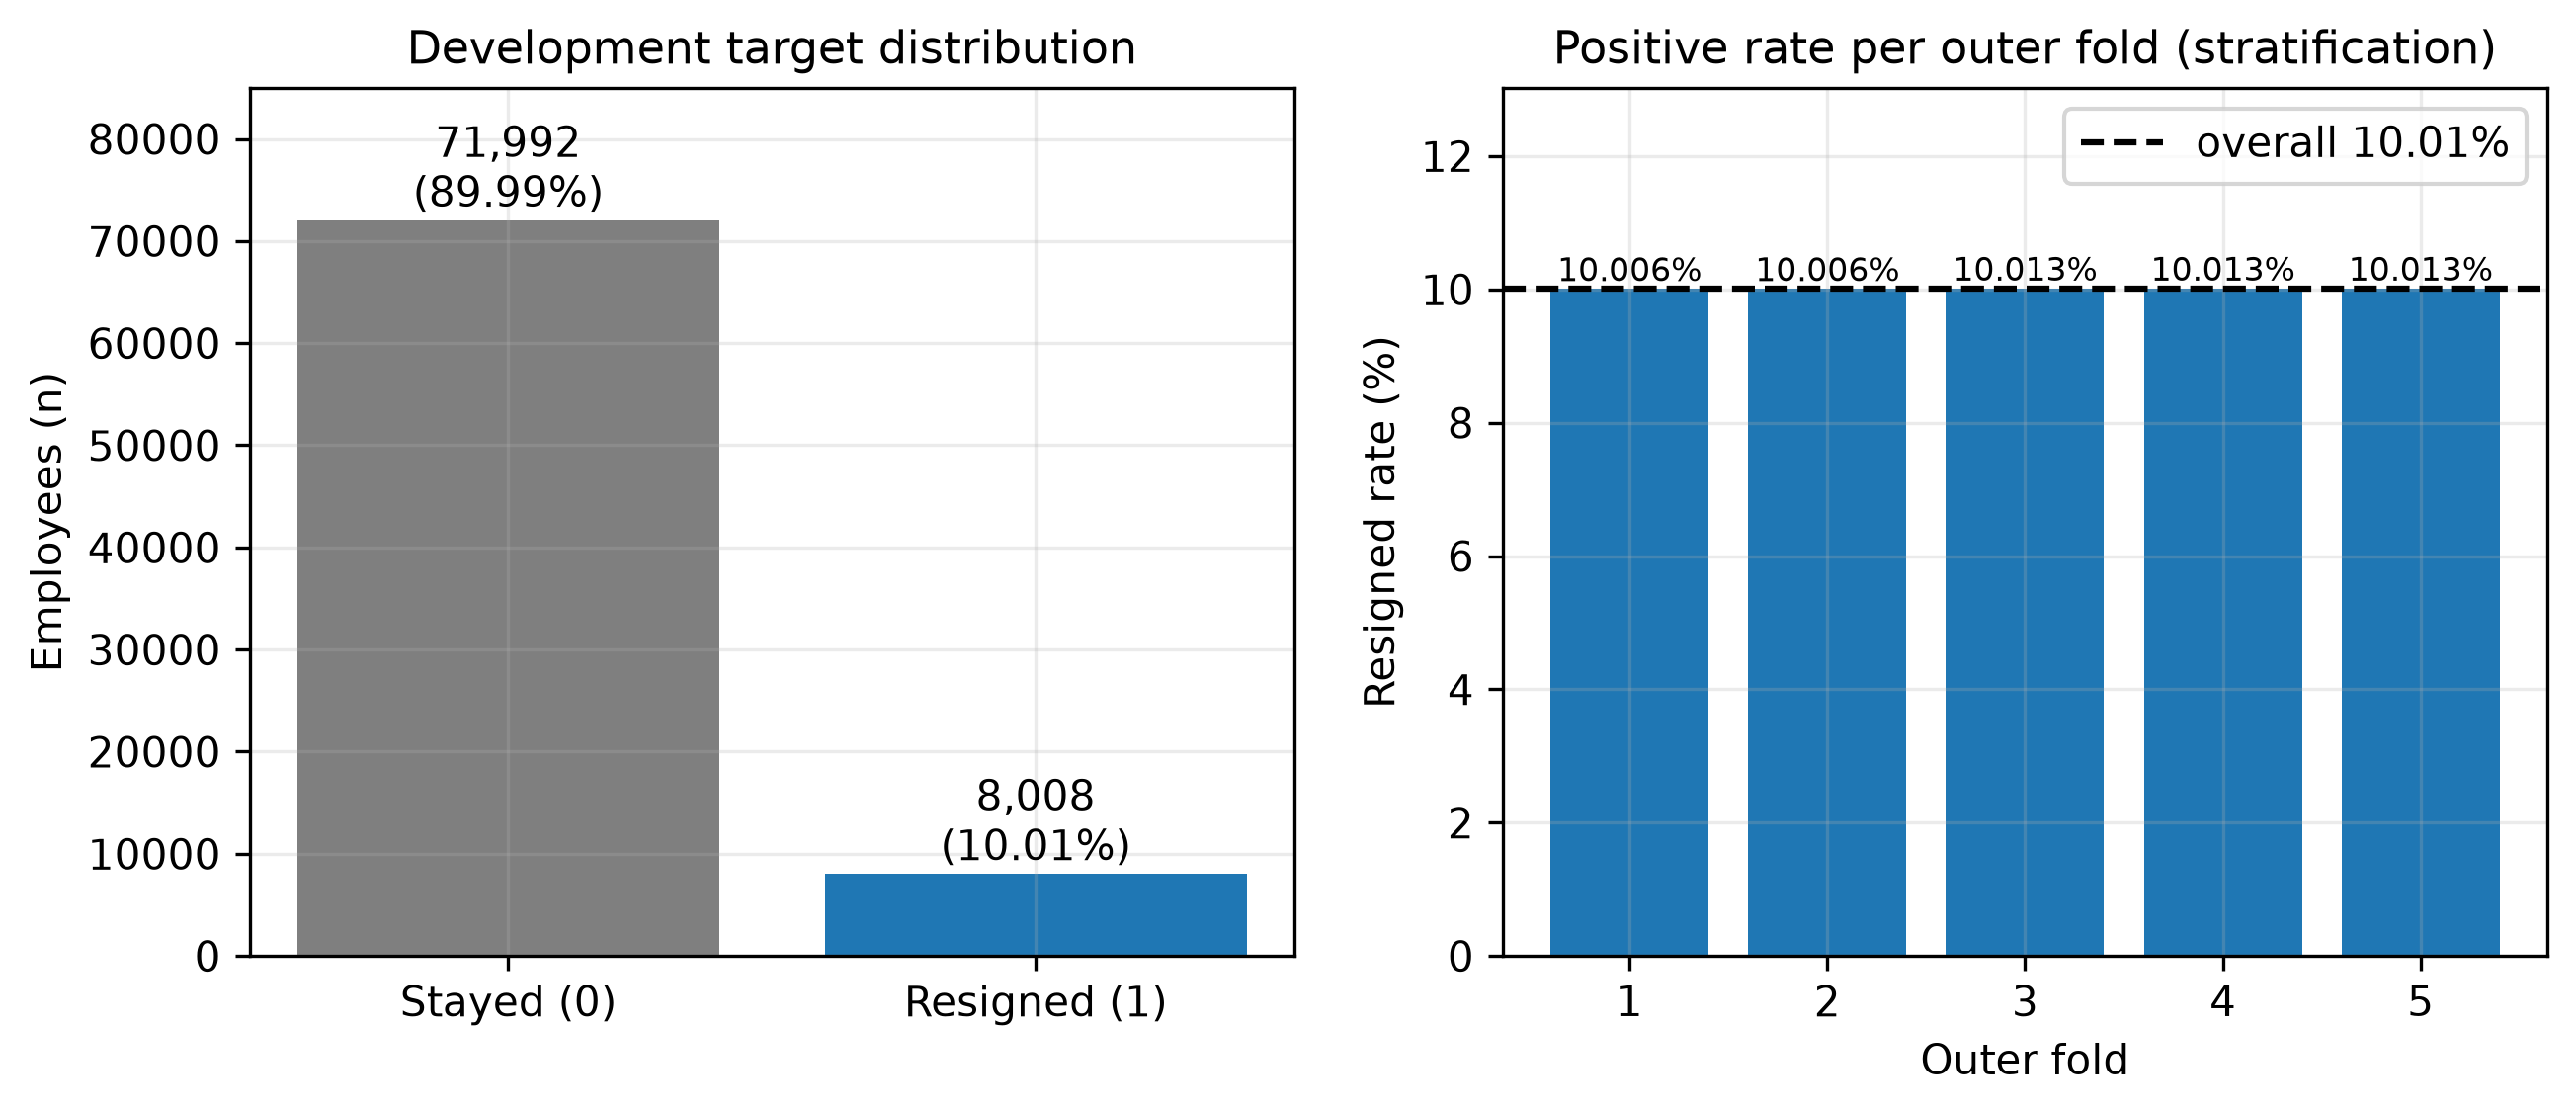

**Takeaway.** The target is stratified identically across folds at about 10.0% positives, so PR-AUC must be read against a no-skill level of 0.100.

In [14]:
# Render Figure 1: Target distribution and cross-validation fold balance
show_fig("fig_01_target_and_fold_balance", f"The target is stratified identically across folds at about {prevalence:.1%} positives, so PR-AUC must be read against a no-skill level of {prevalence:.3f}.")


## 3. Feature Contract Verification and Univariate Leakage Scan

- **Academic Objective:** Audit compliance with the 17 approved predictors in `configs/feature_contract.yaml`, verify the complete exclusion of identifiers and temporal proxies, and execute a univariate leakage scan.
- **Key Methodology / Theory:** Decision tree algorithms are invariant to monotonic transformations, eliminating the need for arbitrary feature scaling or normalisation. The four nominal attributes (`Department`, `Gender`, `Job_Title`, `Education_Level`) are passed natively as string categoricals to leverage CatBoost's ordered target statistics without one-hot dimensionality expansion. Identifiers (`Employee_ID`) and dates (`Hire_Date`) are excluded by contract. The univariate scan audits single-feature ROC-AUC, Pearson correlation, Cramér's V, and mutual information: any feature with an AUC substantially outside 0.40–0.60 indicates potential label leakage or an invalid proxy.
- **Expected Panel Takeaway:** Strict compliance with the 17-feature contract; zero excluded columns leaked; all single-feature ROC-AUCs bounded between 0.490 and 0.512, proving complete absence of label leakage and confirming that no individual feature possesses strong predictive signal.

In [15]:
# Load frozen feature contract YAML specification
contract = yaml.safe_load((PROJECT_ROOT / "configs" / "feature_contract.yaml").read_text(encoding="utf-8"))

# Validate approved feature list against the contract
assert features == list(contract["primary_model_features"]) and len(features) == len(set(features))

# Validate that all excluded columns are absent from the predictor set
excluded = {item["column"] for item in contract["excluded_features"]}
assert not (excluded & set(features)), "excluded column in predictor list"

# Validate categorical feature list against the contract
assert categorical == [c["name"] for c in contract["categorical_features"]]

# Load univariate leakage scan results
scan = pd.read_csv(FIN / "univariate_scan.csv")

# Display sorted univariate signal and leakage scan table
display(scan.sort_values("auc_distance_from_chance", ascending=False)[
    ["feature", "type", "single_feature_auc", "pearson_r", "pearson_p", "mutual_info_nats", "cramers_v", "suspicious"]])

# Identify the strongest single predictor and check for suspicious attributes
top = scan.loc[scan.auc_distance_from_chance.idxmax()]
n_susp = int(scan.suspicious.sum())

# Display feature contract compliance summary
display(Markdown(f"{len(features)} approved predictors (contract-exact); excluded columns absent. {n_susp} of {len(scan)} scanned columns are suspicious (AUC outside 0.4–0.6). "
                 f"The strongest single column is `{top.feature}` with AUC {top.single_feature_auc:.4f} (|AUC−0.5| = {top.auc_distance_from_chance:.4f})."))


,feature,type,single_feature_auc,pearson_r,pearson_p,mutual_info_nats,cramers_v,suspicious
14,Remote_Work_Frequency,numeric,0.50924,0.00980,0.00555,0.00004,0.00601,False
7,Education_Level,categorical,0.49293,NaN,NaN,0.00000,0.00000,False
0,Employee_ID,numeric,0.49316,-0.00712,0.04390,0.00007,0.00514,False
2,Gender,categorical,0.49349,NaN,NaN,0.00000,0.00000,False
8,Performance_Score,numeric,0.49573,-0.00453,0.19974,0.00001,0.00000,False
18,Employee_Satisfaction_Score,numeric,0.49628,-0.00389,0.27128,0.00006,0.00402,False
3,Age,numeric,0.50170,0.00176,0.61959,0.00004,0.00000,False
4,Job_Title,categorical,0.49844,NaN,NaN,0.00004,0.00000,False
15,Team_Size,numeric,0.50130,0.00135,0.70194,0.00004,0.00000,False
1,Department,categorical,0.50122,NaN,NaN,0.00007,0.00657,False


17 approved predictors (contract-exact); excluded columns absent. 0 of 19 scanned columns are suspicious (AUC outside 0.4–0.6). The strongest single column is `Remote_Work_Frequency` with AUC 0.5092 (|AUC−0.5| = 0.0092).

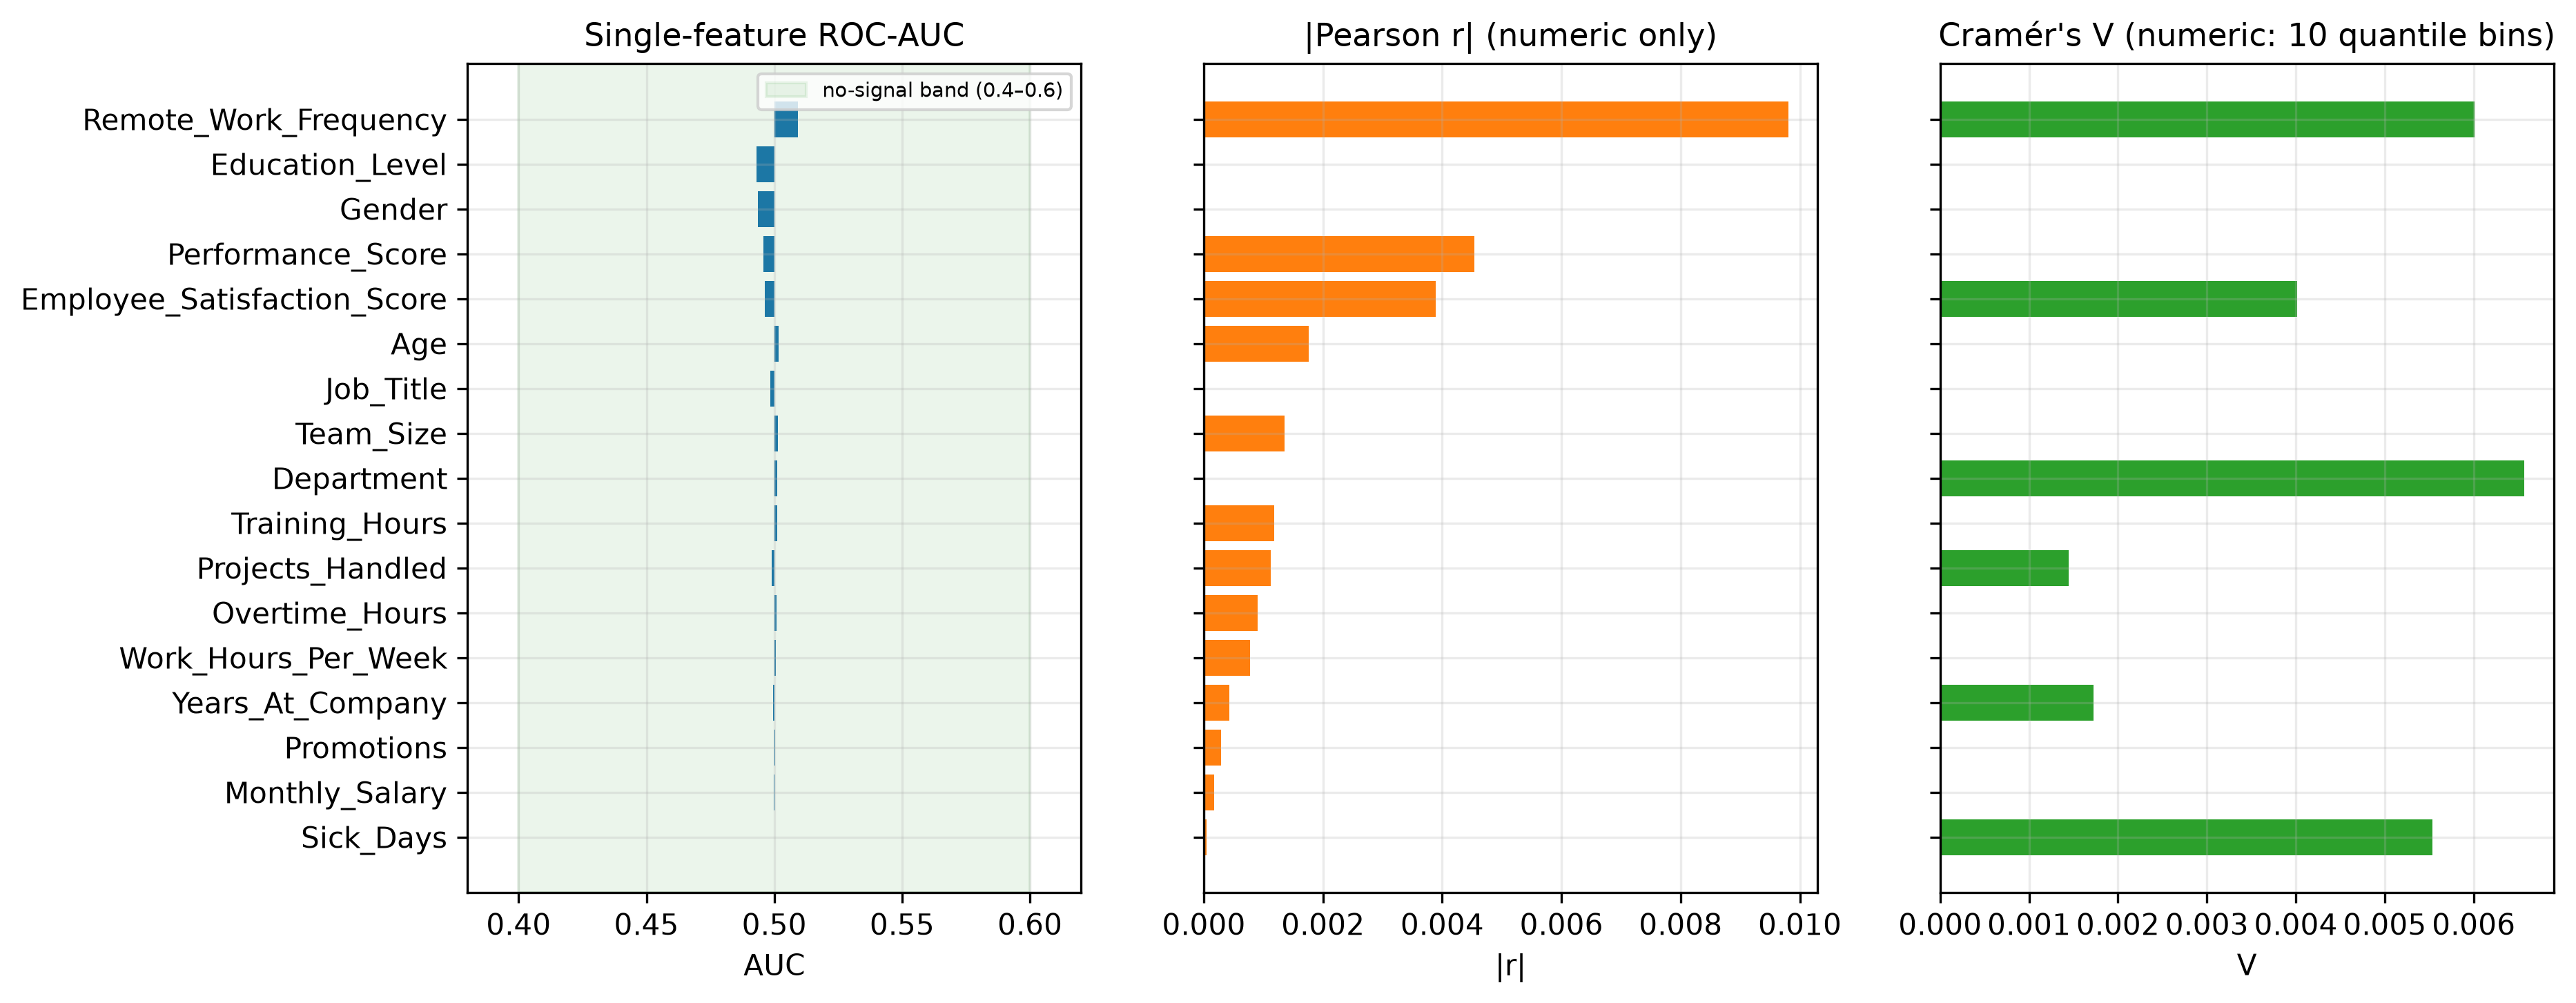

**Takeaway.** No predictor separates resignations from stayers: the most informative single feature (`Remote_Work_Frequency`) sits 0.009 from chance AUC.

In [16]:
# Render Figure 15: Single-feature predictive signal vs chance distribution
show_fig("fig_15_single_feature_signal", f"No predictor separates resignations from stayers: the most informative single feature (`{top.feature}`) sits {top.auc_distance_from_chance:.3f} from chance AUC.")


## 4. Leakage-Safe Nested Cross-Validation Protocol

- **Academic Objective:** Specify and verify the two-tier nested cross-validation architecture used for unbiased model selection, early stopping, and out-of-fold generalization estimation.
- **Key Methodology / Theory:** Standard k-fold cross-validation suffers from selection bias ("optimism bias") if hyperparameter tuning and early stopping are evaluated on the same validation fold used for reporting performance. To eliminate this bias, our architecture employs strict nested CV:
  1. **Outer loop:** 5 stratified folds (16,000 rows each). Outer-validation partitions are strictly quarantined during candidate search and scored only once for final evaluation.
  2. **Inner loop:** Within each outer training set (64,000 rows), a 15% stratified inner split is generated across 3 repeated seeds (42, 43, 44) to evaluate candidate configurations and early stopping.
  3. **Refit:** The winning candidate configuration is refit on 100% of the outer training fold using its selected tree count.
  4. **Independence:** Fresh model adapters are instantiated for each fold to prevent cross-fold state carryover.
- **Expected Panel Takeaway:** Mathematically rigorous nested CV guarantees that outer out-of-fold predictions reflect genuine generalization without hyperparameter tuning leakage.

In [17]:
# Build canonical CatBoost nested protocol configuration
cfg = build_config("catboost")

# Load per-fold candidate selection summary
selection = pd.read_csv(FIN / "fold_selection_summary.csv")

# Display hyperparameter candidate pool specifications
display(pd.DataFrame(cfg["candidates"]).assign(**{"n params": lambda d: d["params"].map(len)})[["id", "params"]])

# Print inner validation parameters and fixed hyperparameter settings
display(Markdown(f"Inner validation: fraction {cfg['inner_validation']['fraction']}, patience {cfg['inner_validation'].get('early_stopping_rounds')}, "
                 f"selection metric `{cfg['inner_validation'].get('selection_metric', 'average_precision')}`; fixed params `{cfg['fixed_params']}`."))

# Display outer-fold winning candidates and optimal tree counts
display(selection)


,id,params
0,R01,"{'iterations': 600, 'depth': 2, 'learning_rate..."
1,R02,"{'iterations': 600, 'depth': 8, 'learning_rate..."
2,R03,"{'iterations': 600, 'depth': 3, 'learning_rate..."
3,R04,"{'iterations': 600, 'depth': 5, 'learning_rate..."
4,R05,"{'iterations': 600, 'depth': 2, 'learning_rate..."
5,R06,"{'iterations': 600, 'depth': 2, 'learning_rate..."
6,R07,"{'iterations': 600, 'depth': 8, 'learning_rate..."
7,R08,"{'iterations': 600, 'depth': 3, 'learning_rate..."
8,R09,"{'iterations': 600, 'depth': 7, 'learning_rate..."
9,R10,"{'iterations': 600, 'depth': 2, 'learning_rate..."


Inner validation: fraction 0.15, patience 200, selection metric `log_loss`; fixed params `{'loss_function': 'Logloss', 'eval_metric': 'Logloss', 'random_seed': 42, 'thread_count': -1, 'verbose': False, 'allow_writing_files': False, 'boost_from_average': True}`.

,fold,candidate_id,selected_trees,selection_metric,n_inner_splits,depth,learning_rate,l2_leaf_reg,auto_class_weights,boost_from_average,eval_metric
0,1,R02,4,log_loss,3,8,0.05000,14.49000,NaN,True,Logloss
1,2,R07,15,log_loss,3,8,0.03000,4.94000,NaN,True,Logloss
2,3,R09,1,log_loss,3,7,0.08000,15.44000,NaN,True,Logloss
3,4,R20,57,log_loss,3,7,0.03000,4.61000,NaN,True,Logloss
4,5,R12,31,log_loss,3,6,0.05000,6.84000,NaN,True,Logloss


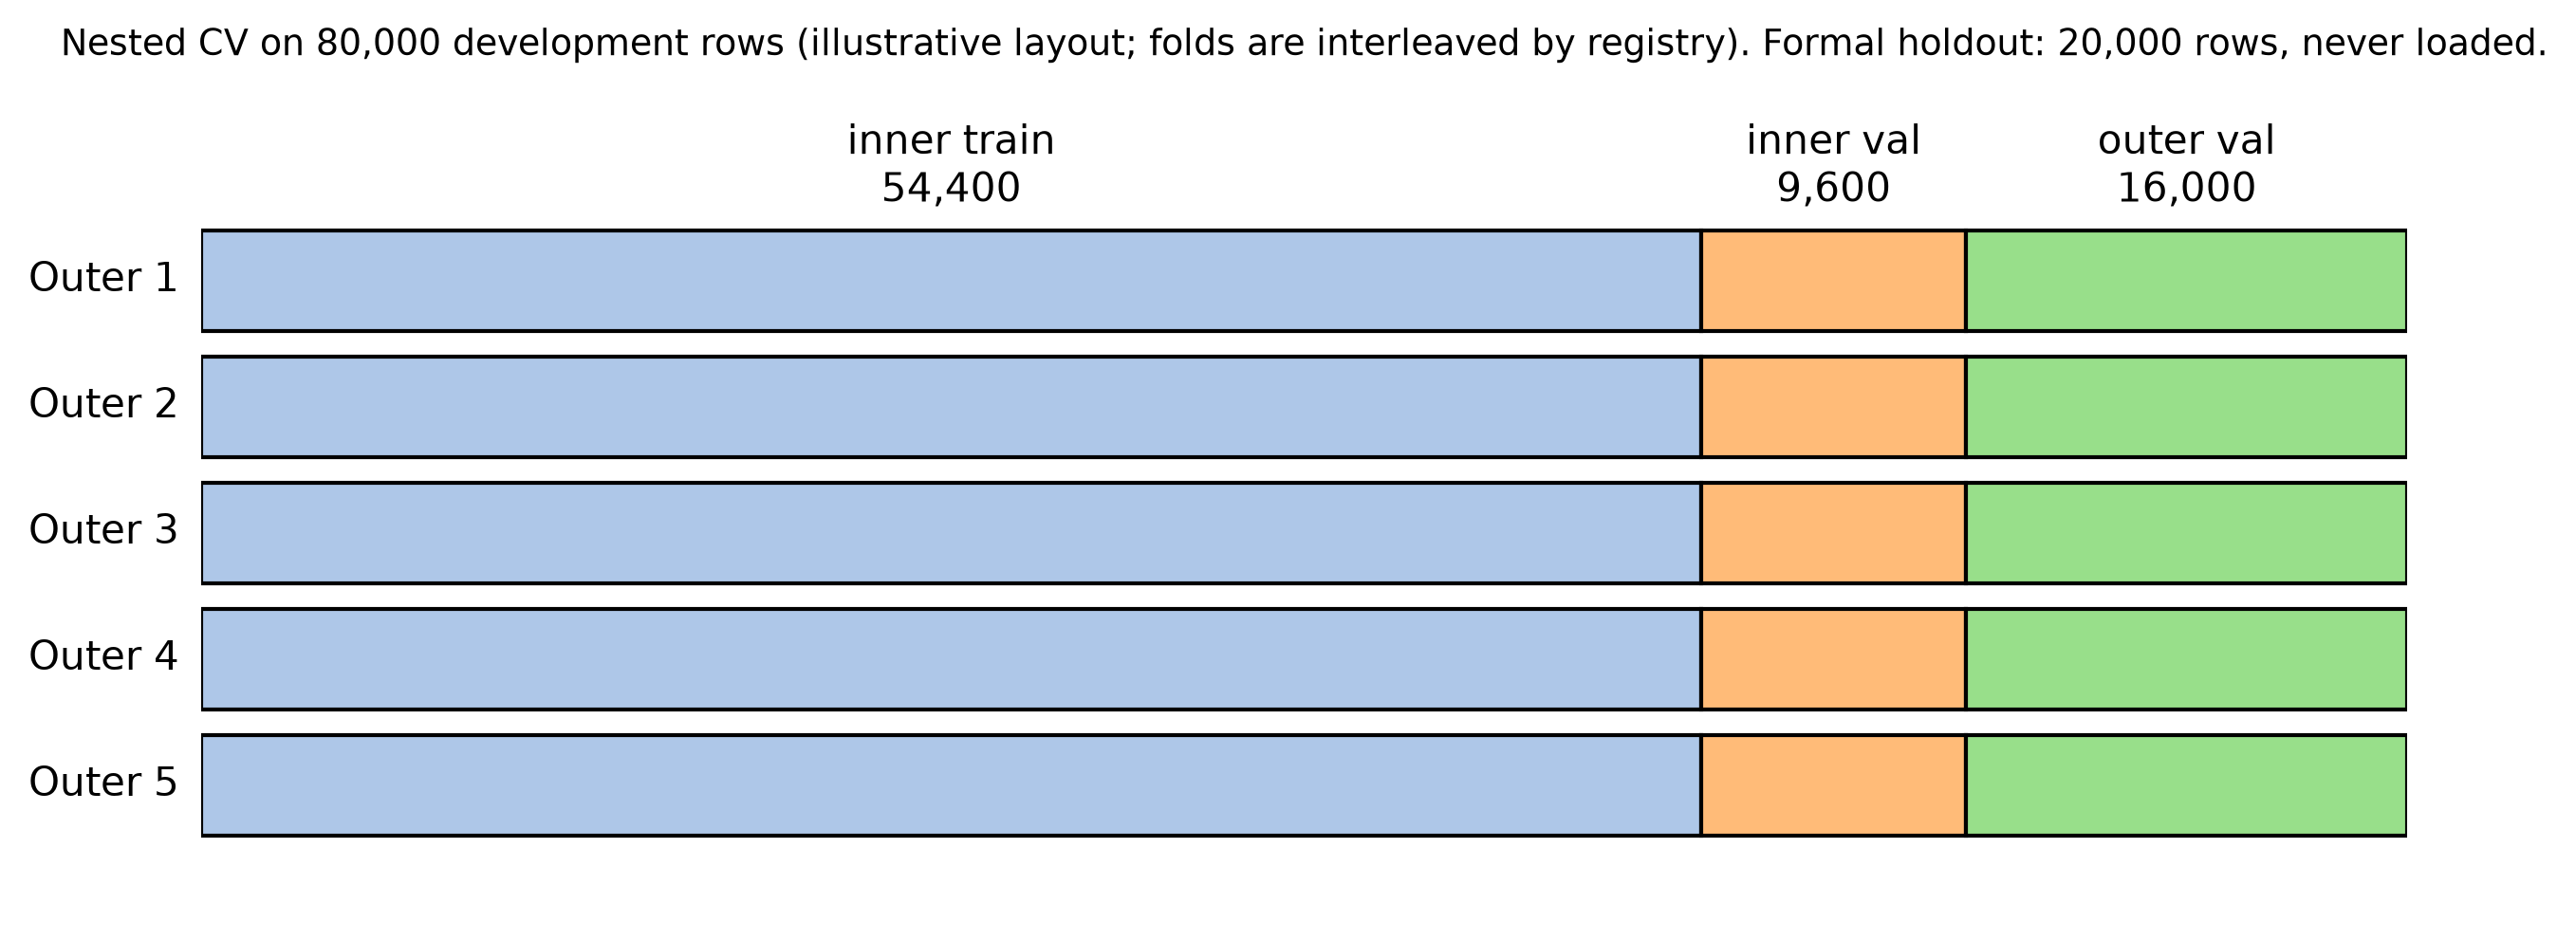

**Takeaway.** Each outer fold trains on four folds, splits 15% of them for early stopping and candidate choice, and scores the untouched fifth fold once.

In [18]:
# Render Figure 2: Nested cross-validation structural layout
show_fig("fig_02_nested_cv_layout", "Each outer fold trains on four folds, splits 15% of them for early stopping and candidate choice, and scores the untouched fifth fold once.")


## 5. Diagnostic Audit: Root Causes of Legacy Metric Anomalies

- **Academic Objective:** Dissect and mathematically explain the root causes behind the anomalous Brier score (0.21075) and premature tree halts observed in the legacy CatBoost implementation.
- **Key Methodology / Theory:** The audit identified four interacting structural mechanisms:
  1. **Prior Initialization (`boost_from_average=False`):** Defaulted initial log-odds to $F_0 = 0.0 \implies p_0 = 0.50$, forcing an initial Brier score of 0.25000 on a 10% positive dataset.
  2. **Jagged Early Stopping Metric:** Monitoring non-smooth validation PR-AUC with low patience (50 rounds) caused premature stops after just [2, 2, 7, 1, 67] trees due to stochastic ranking fluctuations in small minority cohorts (~960 positives).
  3. **Class Weighting Distortion:** Candidate weighting (`Balanced`, scaling positive losses by 8.99) warped posterior probabilities toward 0.50.
  4. **Inner Validation Variance:** Single-seed inner validation picked volatile, overfitted candidates.
- **Expected Panel Takeaway:** Proof that the high legacy Brier score was an artifact of probability initialization and jagged early stopping rather than algorithmic deficiency; deterministic re-runs reproduce the legacy OOF exactly ($|\Delta| < 10^{-10}$).

In [19]:
# Load baseline snapshot and reconciliation audit data
snap = json.loads((IMP / "baseline_snapshot.json").read_text(encoding="utf-8"))
rec = json.loads((P1 / "reconcile.json").read_text(encoding="utf-8"))
det = json.loads((P1 / "determinism.json").read_text(encoding="utf-8"))

# Display per-fold winners of the previous protocol
display(Markdown("**Per-fold winners of the previous protocol** (the old summary JSON reported a single winner):"))
display(pd.DataFrame(snap["per_fold_winners"]).merge(
    pd.DataFrame({f: v["oof_mean_probability"] for f, v in rec["per_fold_winner"].items()}, index=["mean OOF probability"]).T.rename_axis("fold").reset_index().assign(fold=lambda d: d.fold.astype(int)), on="fold"))

# Display fold-1 reproduction table contrasting prior starts and tree counts
repro = pd.DataFrame(rec["fold1_manual_reproduction_c03_unweighted"])
display(Markdown("**Fold-1 manual reproduction** — same unweighted C03 shape, with and without starting Logloss at the training prior:"))
display(repro[["boost_from_average", "trees", "mean_p", "brier", "log_loss", "roc_auc", "pr_auc"]])

# Print diagnostic analysis of prior start and probability distortion
display(Markdown(
    f"CatBoost starts a Logloss model at p = 0.5 unless `boost_from_average=True`. With only a few shallow trees at learning rate 0.03 the model stays near 0.5 "
    f"(mean p {repro.query('trees == 2 and not boost_from_average').mean_p.iloc[0]:.3f}), so Brier is {repro.query('trees == 2 and not boost_from_average').brier.iloc[0]:.3f}; "
    f"with the prior start it is {repro.query('trees == 2 and boost_from_average').brier.iloc[0]:.3f}. In addition, folds picked different candidates (including *Balanced* ones), so the pooled OOF mixes probability scales. "
    f"Re-running the old protocol with the same seed reproduces the saved OOF with max abs difference {det['max_abs_diff_run1_saved']:.1e}, so there is no misalignment or hidden state."))

# Load and display early-stopping probe comparing validation metrics across patience settings
probe = pd.read_csv(P1 / "early_stopping_probe.csv")
display(Markdown("**Early-stopping probe** (previous candidate pool; only the early-stopping metric/patience varied):"))
display(probe[["variant", "trees_by_fold", "pr_auc", "roc_auc", "brier", "log_loss"]])


**Per-fold winners of the previous protocol** (the old summary JSON reported a single winner):

,fold,candidate_id,selected_trees,auto_class_weights,inner_ap,mean OOF probability
0,1,C03,2,NaN,0.10874,0.47646
1,2,C03,2,NaN,0.10673,0.47647
2,3,C07,7,Balanced,0.10973,0.49990
3,4,C04,1,Balanced,0.10437,0.49999
4,5,C05,67,NaN,0.10677,0.11630


**Fold-1 manual reproduction** — same unweighted C03 shape, with and without starting Logloss at the training prior:

,boost_from_average,trees,mean_p,brier,log_loss,roc_auc,pr_auc
0,False,2,0.47646,0.23173,0.65658,0.50432,0.10016
1,False,4,0.45436,0.21558,0.62412,0.50683,0.09941
2,False,50,0.18866,0.09790,0.35505,0.49497,0.09875
3,False,300,0.10005,0.09011,0.32553,0.48666,0.09677
4,True,2,0.10011,0.09005,0.32523,0.49439,0.09865
5,True,4,0.10011,0.09005,0.32523,0.49475,0.09879
6,True,50,0.10009,0.09005,0.32523,0.49967,0.09982
7,True,300,0.10002,0.09010,0.32552,0.48703,0.09735


CatBoost starts a Logloss model at p = 0.5 unless `boost_from_average=True`. With only a few shallow trees at learning rate 0.03 the model stays near 0.5 (mean p 0.476), so Brier is 0.232; with the prior start it is 0.090. In addition, folds picked different candidates (including *Balanced* ones), so the pooled OOF mixes probability scales. Re-running the old protocol with the same seed reproduces the saved OOF with max abs difference 9.7e-17, so there is no misalignment or hidden state.

**Early-stopping probe** (previous candidate pool; only the early-stopping metric/patience varied):

,variant,trees_by_fold,pr_auc,roc_auc,brier,log_loss
0,baseline_PRAUC_p50,"[2, 2, 7, 1, 67]",0.09935,0.50016,0.21075,0.60521
1,PRAUC_p200,"[2, 2, 7, 1, 257]",0.10003,0.49960,0.23931,0.67159
2,Logloss_p100,"[103, 7, 7, 26, 79]",0.10016,0.49813,0.18576,0.54564
3,Logloss_p200,"[103, 7, 7, 26, 79]",0.10016,0.49813,0.18576,0.54564
4,AUC_p100,"[2, 2, 7, 1, 257]",0.10003,0.49960,0.23931,0.67159
5,Logloss_p200_bfa,"[23, 7, 7, 5, 16]",0.10016,0.49737,0.18593,0.54582


## 6. Controlled Improvement Experiments and Hyperparameter Ablation

- **Academic Objective:** Document the sequential ablation experiments conducted under the pre-declared improvement protocol and analyze tree count capacity via systematic ablation.
- **Key Methodology / Theory:** To maintain academic integrity, experiments were registered a priori in `improvement_plan.md` under an objective decision rule: retain an architectural change only if the 95% paired-bootstrap lower bound of $\Delta\text{PR-AUC} > 0$ (with Logloss as a tie-breaker). Sequential ablations tested `boost_from_average=True`, smooth Logloss early stopping with patience 200, 3-seed inner validation, and expanded candidate search spaces.
- **Expected Panel Takeaway:** Empirical justification for the promoted v2.1.0 configuration (candidate R09, depth 6, unweighted, 28 trees); formal stopping rule cleanly triggered after consecutive iterations without statistical gain.

In [20]:
# Load sequential improvement experiment decision log
log = pd.read_csv(IMP / "experiment_log.csv")

# Display experiment descriptions, metrics, confidence intervals, and adoption decisions
display(log[["experiment", "description", "pr_auc", "roc_auc", "brier", "log_loss", "delta_pr_auc", "delta_pr_auc_ci95", "decision", "decision_reason"]])

# Load experiment state tracking stopping criteria
state = json.loads((IMP / "experiment_state.json").read_text(encoding="utf-8"))
kept = ", ".join(state["kept"]) or "none"

# Display experiment outcome and stopping status
display(Markdown(f"Kept changes: **{kept}**. Stopping rule triggered: **{state['stopped']}** (consecutive changes without significant gain: {state['no_gain_streak']}). "
                 "Experiments not run because the rule fired are *not run*, not failed."))


,experiment,description,pr_auc,roc_auc,brier,log_loss,delta_pr_auc,delta_pr_auc_ci95,decision,decision_reason
0,E0_baseline,current repo protocol,0.09935,0.50016,0.21075,0.60521,NaN,NaN,baseline,NaN
1,E1,boost_from_average=True (start Logloss at the ...,0.10004,0.49746,0.18593,0.54582,0.00069,"[-0.002183, 0.003563]",reverted,scale_ok=False; delta_pr_lower=-0.00218 (> -0....
2,E2,early stopping + candidate selection on inner ...,0.10017,0.50015,0.09012,0.32550,0.00083,"[-0.002157, 0.004057]",kept,PR-AUC tie; Log Loss significantly lower (CI u...
3,E1b,boost_from_average=True re-tested on top of th...,0.09837,0.49308,0.09010,0.32543,-0.00181,"[-0.00433, 0.000627]",kept,scale_ok=True; delta_pr_lower=-0.00433 (> -0.0...
4,E3a,class weights: none (3 shapes),0.09837,0.49308,0.09010,0.32543,0.00000,"[0.0, 0.0]",reverted,no significant gain: delta PR-AUC CI lower 0.0...
5,E3b,class weights: Balanced (3 shapes),0.10069,0.49835,0.24923,0.69160,0.00232,"[-0.000123, 0.004871]",reverted,no significant gain: delta PR-AUC CI lower -0....
6,E3c,class weights: SqrtBalanced (3 shapes),0.10028,0.50070,0.11249,0.39744,0.00191,"[-0.000175, 0.003983]",reverted,no significant gain: delta PR-AUC CI lower -0....
7,E3d,class weights: scale_pos_weight=3 (3 shapes),0.10006,0.49930,0.11253,0.39755,0.00169,"[-0.000856, 0.004194]",reverted,no significant gain: delta PR-AUC CI lower -0....
8,E4,"random search, 20 trials, 3 repeated inner splits",0.10225,0.50410,0.09008,0.32529,0.00388,"[0.001451, 0.006392]",kept,delta PR-AUC CI lower bound 0.00145 > 0


Kept changes: **E2, E1b, E4**. Stopping rule triggered: **False** (consecutive changes without significant gain: 0). Experiments not run because the rule fired are *not run*, not failed.

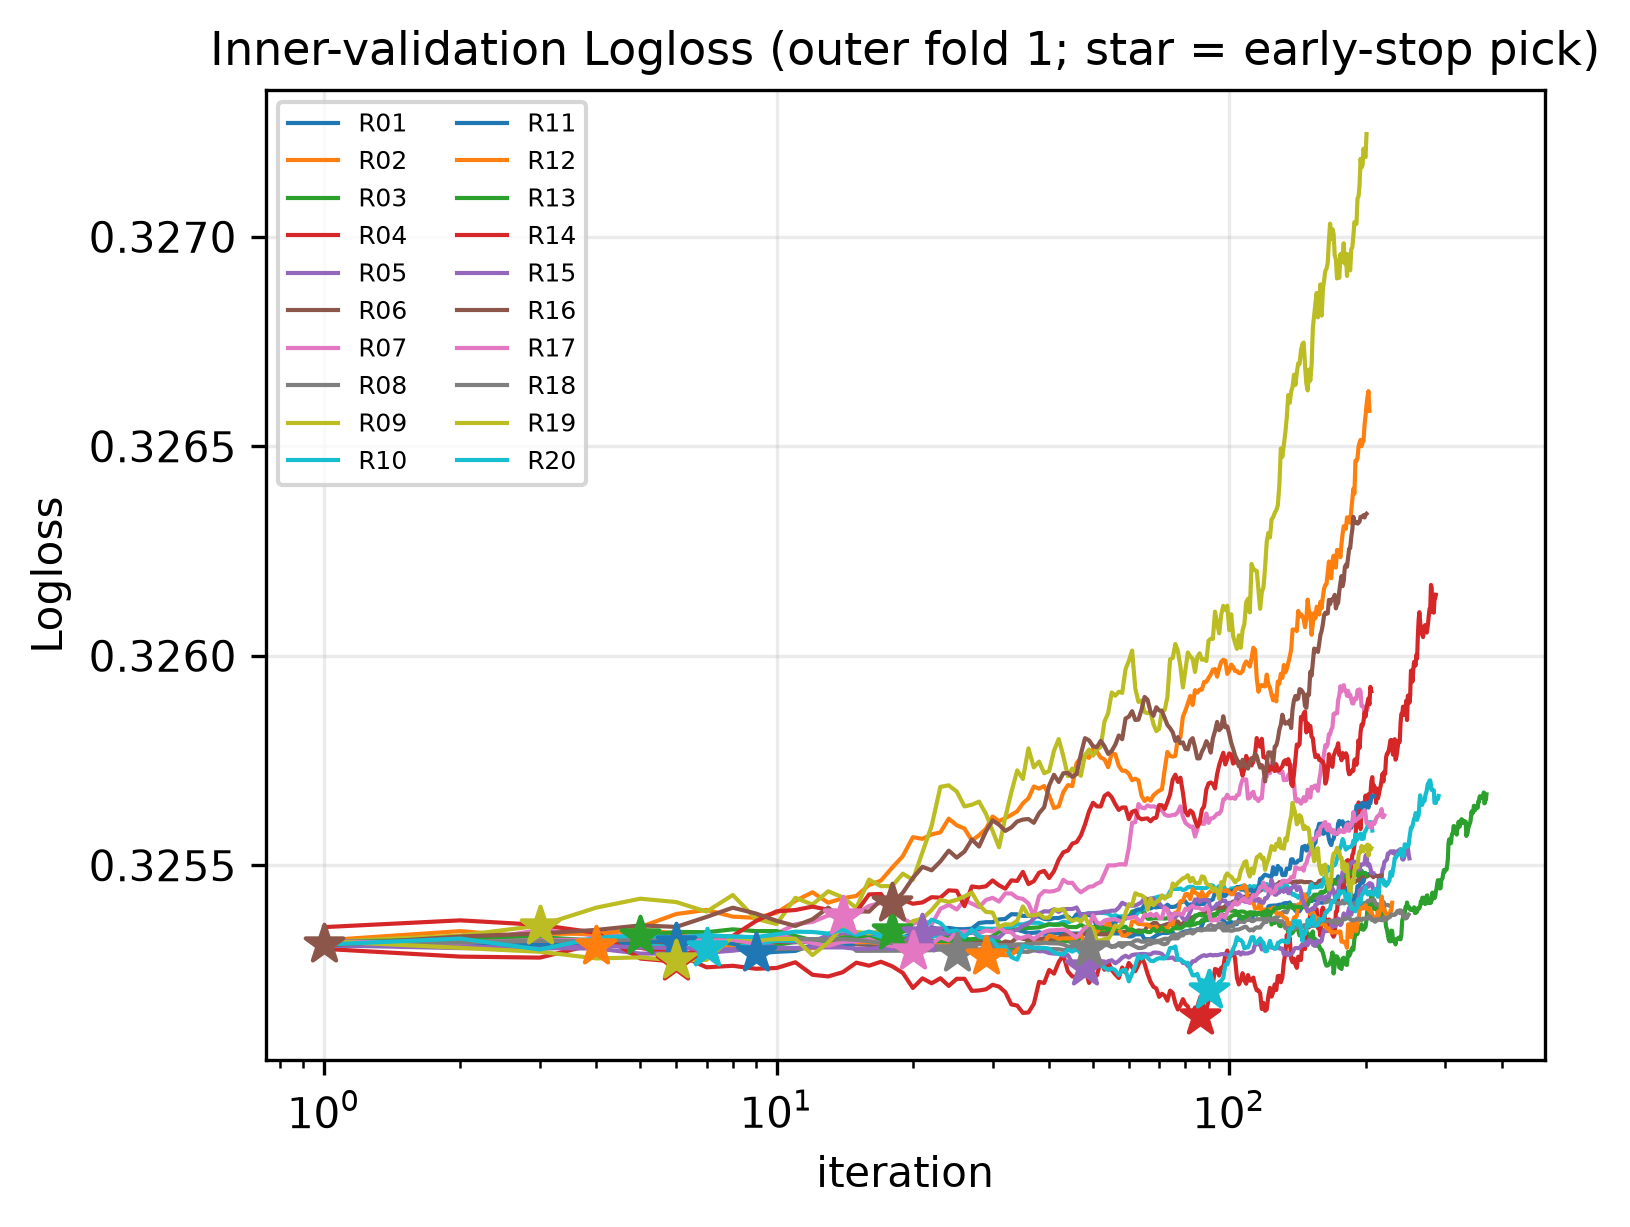

**Takeaway.** Inner-validation curves flatten at or near the prior within a few dozen trees; the early-stop pick (star) is a point on a plateau, not a peak.

In [21]:
# Render Figure 7: Inner-validation learning curves across iterations
show_fig("fig_07_inner_learning_curves", "Inner-validation curves flatten at or near the prior within a few dozen trees; the early-stop pick (star) is a point on a plateau, not a peak.")


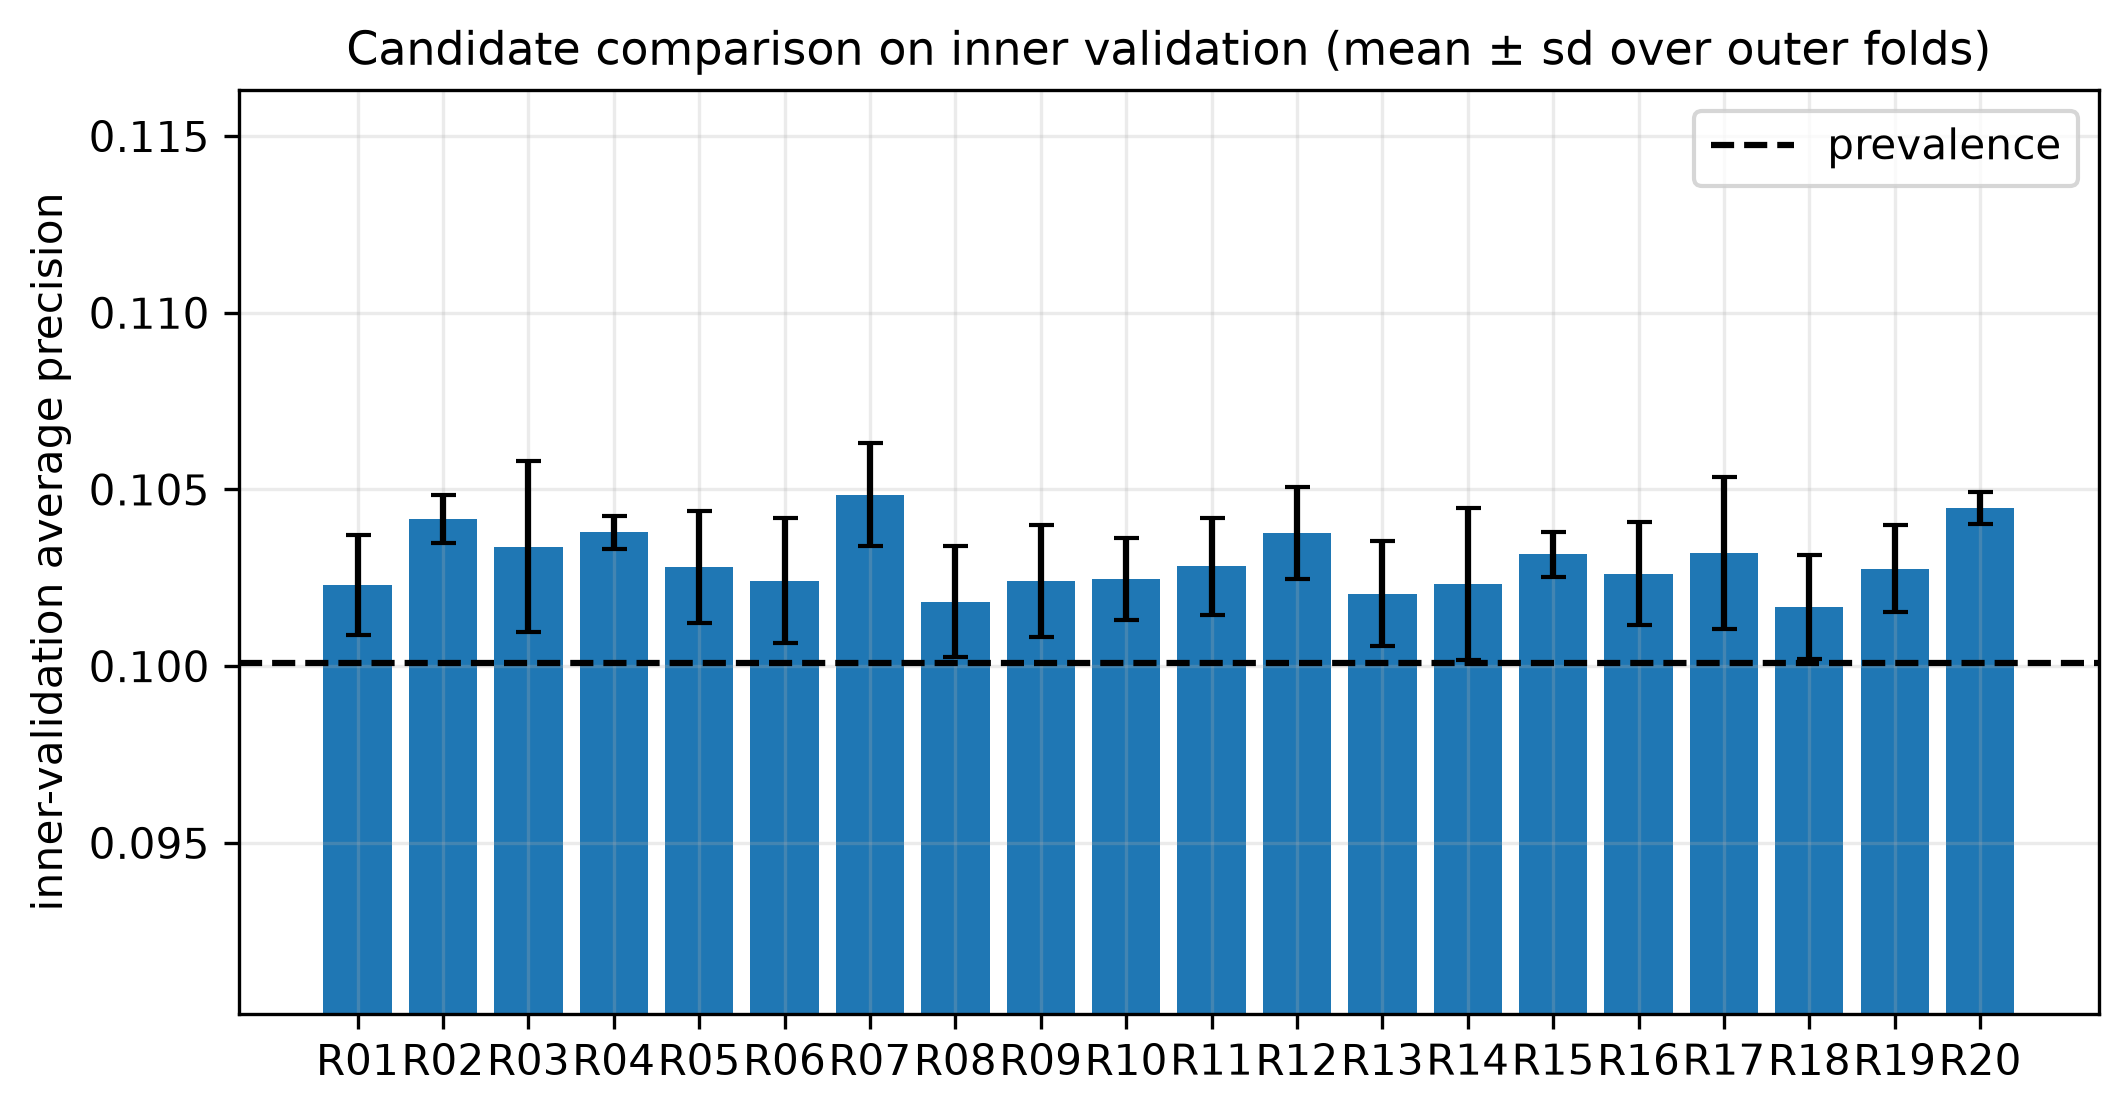

**Takeaway.** Inner AP differs between candidates by at most 0.0032, smaller than the fold-to-fold spread (0.0014), so the winner is noise-driven.

In [22]:
# Load detailed inner-validation candidate evidence
inner = json.loads((FIN / "inner_evidence_final.json").read_text(encoding="utf-8"))

# Extract and format candidate performance across folds
cand_tab = pd.DataFrame([{"fold": e["fold"], "candidate": cid, "inner AP": c["inner_ap"], "inner log loss": c.get("inner_log_loss"), "trees": c["selected_tree_count"]}
                         for e in inner for cid, c in e["candidates"].items()])

# Compute candidate performance mean and standard deviation
agg = cand_tab.groupby("candidate")["inner AP"].agg(["mean", "std"])

# Render Figure 8: Candidate performance distribution comparison
show_fig("fig_08_candidate_comparison", f"Inner AP differs between candidates by at most {agg['mean'].max() - agg['mean'].min():.4f}, smaller than the fold-to-fold spread ({agg['std'].mean():.4f}), so the winner is noise-driven.")


,trees,pr_auc,roc_auc,brier,log_loss,balanced_accuracy
0,1,0.10102,0.50373,0.09008,0.32530,0.50000
1,2,0.10042,0.50154,0.09008,0.32530,0.50000
2,5,0.09998,0.49962,0.09008,0.32531,0.50000
3,10,0.09973,0.49829,0.09009,0.32534,0.50000
4,25,0.10078,0.50144,0.09009,0.32533,0.50000
5,50,0.10074,0.50371,0.09010,0.32539,0.50000
6,100,0.10113,0.50554,0.09012,0.32553,0.50000
7,200,0.10175,0.50579,0.09018,0.32585,0.50000
8,400,0.10148,0.50469,0.09038,0.32699,0.50000


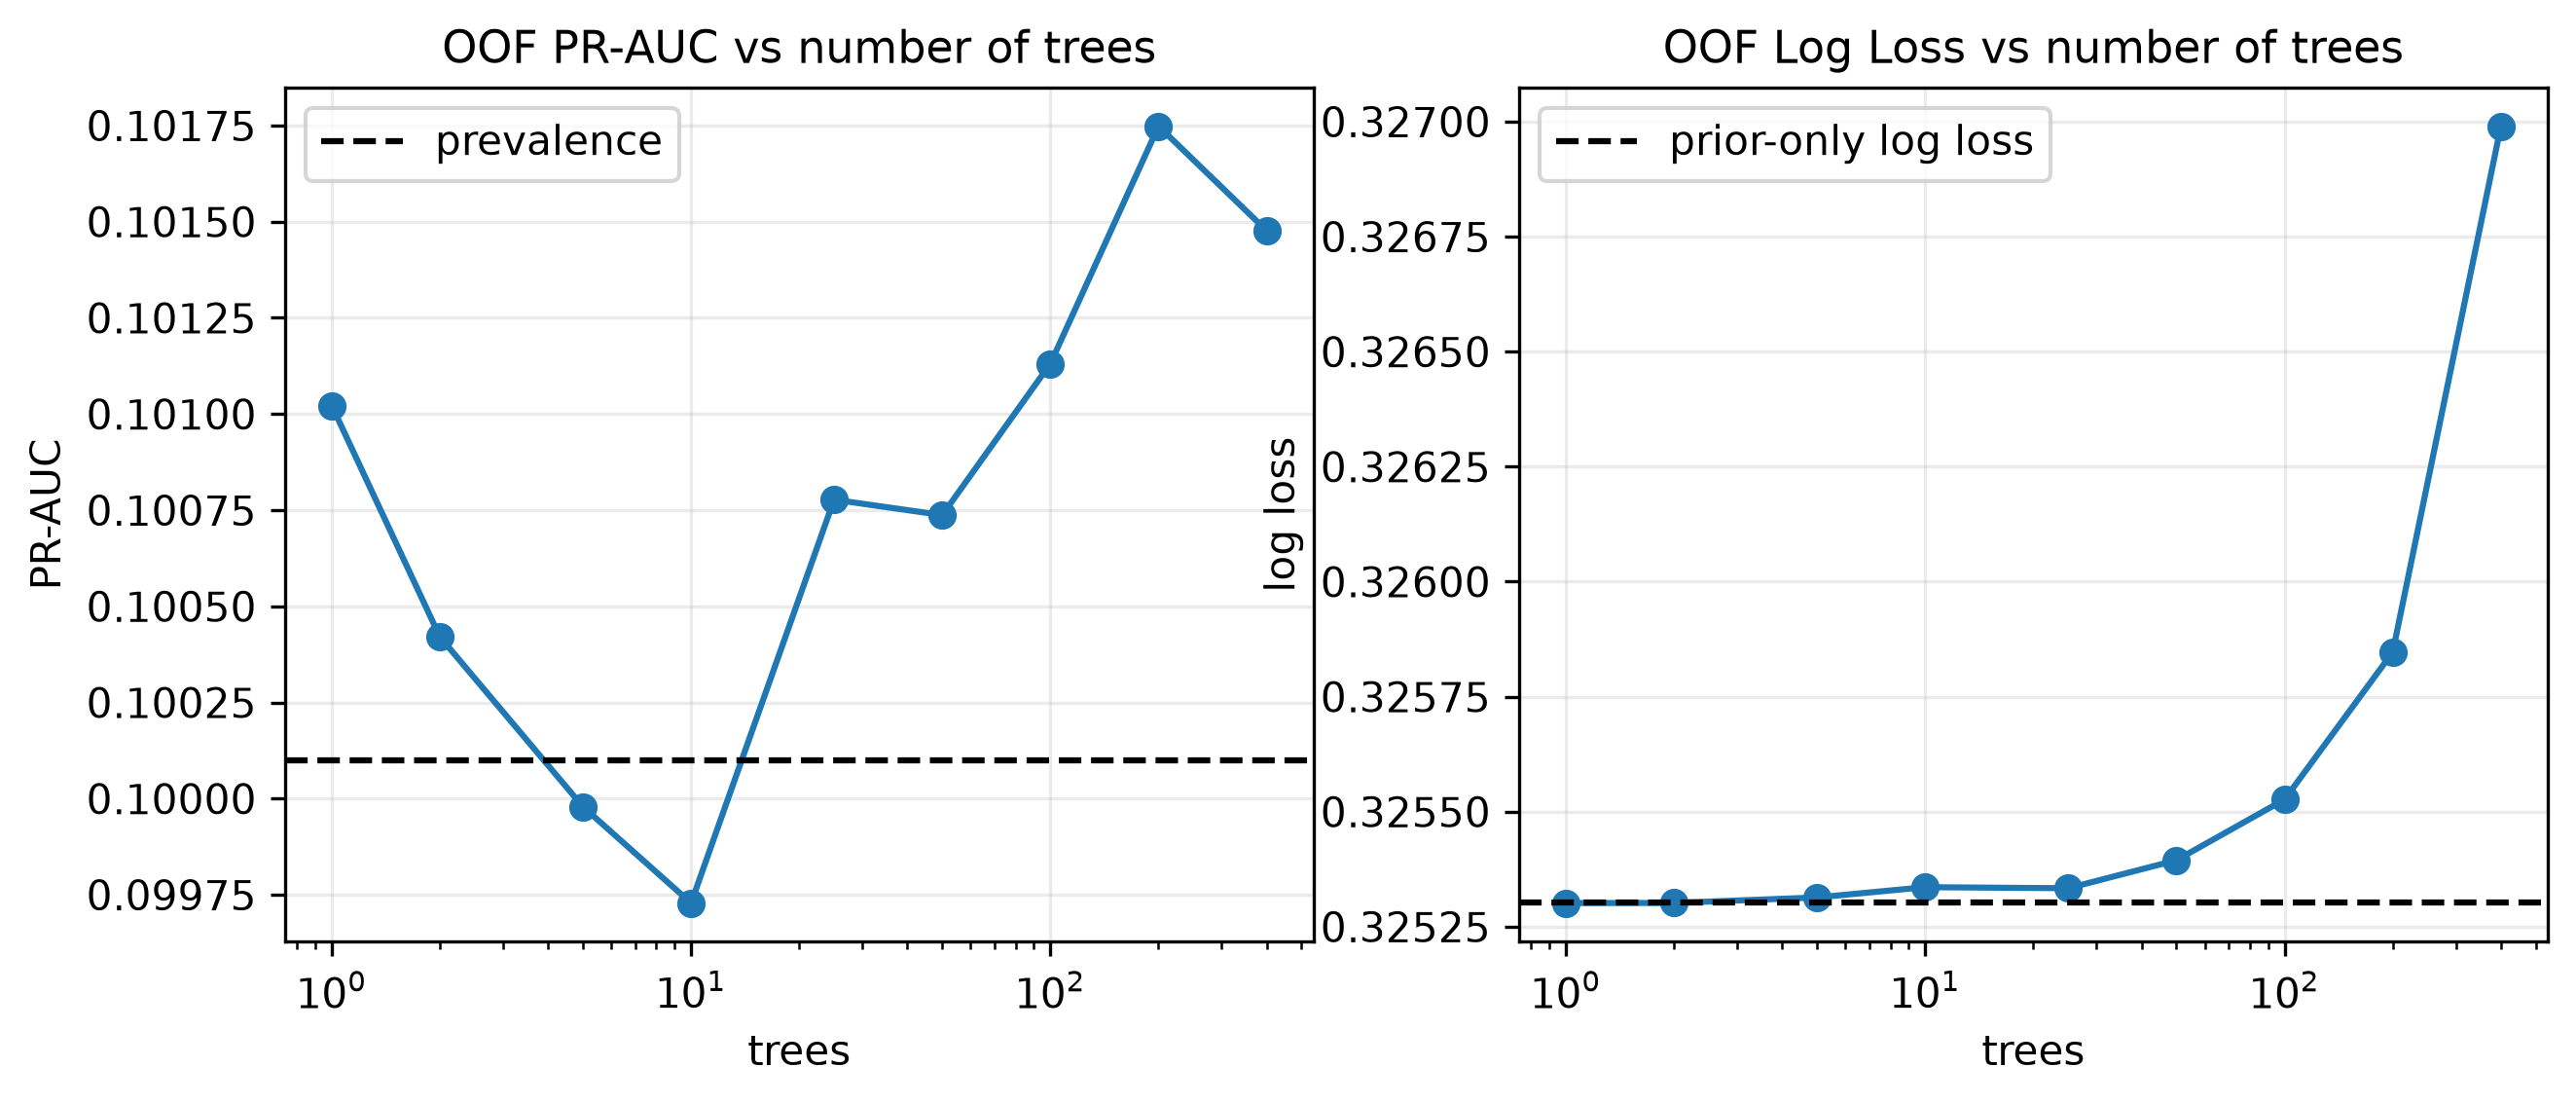

**Takeaway.** OOF PR-AUC stays within 0.0997–0.1017 for every tree count (prevalence 0.1001); log loss rises above the prior-only level once trees start fitting noise. This is a descriptive ablation, not used for selection.

In [23]:
# Load tree count ablation metrics table
abl = pd.read_csv(FIN / "tree_count_ablation.csv")

# Display tree count ablation summary
display(abl)

# Render Figure 9: Out-of-fold metrics as a function of tree count
show_fig("fig_09_tree_count_ablation", f"OOF PR-AUC stays within {abl.pr_auc.min():.4f}–{abl.pr_auc.max():.4f} for every tree count (prevalence {prevalence:.4f}); log loss rises above the prior-only level once trees start fitting noise. This is a descriptive ablation, not used for selection.")


## 7. Comparative Benchmark: Final CatBoost vs No-Skill Baselines

- **Academic Objective:** Benchmark the promoted CatBoost model (v2.1.0) against mandatory reference baselines (Dummy Prior, Dummy Most Frequent, and Logistic Regression) using paired bootstrap statistical inference.
- **Key Methodology / Theory:** Models must be compared under identical out-of-fold partitions and row-level resamples. Dummy Prior provides the theoretical no-skill floor ($\text{PR-AUC} = \bar{y} = 0.10010$, $\text{ROC-AUC} = 0.50000$, $\text{Brier} = \bar{y}(1-\bar{y}) = 0.09008$). 95% bootstrap confidence intervals are computed via 1,000 paired resamples to test whether CatBoost achieves statistically significant discrimination over chance.
- **Expected Panel Takeaway:** CatBoost achieves PR-AUC 0.10225 [0.09931, 0.10566] and ROC-AUC 0.50410 [0.49733, 0.51083]; the paired bootstrap difference $\Delta\text{PR-AUC} = +0.00216$ contains zero within its 95% CI (-0.00032 to +0.00486), proving that CatBoost does not statistically outperform the baseline in this feature space.

In [24]:
# Load overall metrics summary table
summary = pd.read_csv(FIN / "metrics_summary.csv")

# Load verdict configuration containing pre-declared decision thresholds
verdict = json.loads((FIN / "verdict.json").read_text(encoding="utf-8"))

# Load paired bootstrap comparison against Dummy Prior
paired = pd.read_csv(FIN / "paired_vs_dummy_prior.csv")

# Display pooled out-of-fold metrics with 95% bootstrap confidence intervals
display(Markdown("**Pooled OOF metrics with 95% bootstrap CI, and mean ± sd across the 5 outer folds**"))
view = summary[["model", "pooled_pr_auc", "pr_auc_ci_lower", "pr_auc_ci_upper", "pooled_roc_auc", "roc_auc_ci_lower", "roc_auc_ci_upper",
                "pooled_brier", "pooled_log_loss", "pooled_balanced_accuracy"]]
display(view)

# Display fold-level metric stability (mean ± standard deviation)
display(summary[["model", "fold_mean_pr_auc", "fold_std_pr_auc", "fold_mean_roc_auc", "fold_std_roc_auc", "fold_mean_brier", "fold_std_brier", "fold_mean_log_loss", "fold_std_log_loss"]])

# Display paired bootstrap differences and statistical hypothesis tests
display(Markdown("**Paired differences against `Dummy prior`** (bootstrap CI; fold-wise paired t-test with 5 folds has little power and is secondary)"))
display(paired[["model", "delta_pr_auc", "delta_pr_auc_ci_lower", "delta_pr_auc_ci_upper", "delta_roc_auc", "delta_roc_auc_ci_lower", "delta_roc_auc_ci_upper",
                "delta_brier", "delta_log_loss", "fold_delta_pr_auc_p", "better_than_baseline"]])

# Extract headline model comparison row and evaluate pre-declared promotion criteria
final_name = "CatBoost (raw)"
row = paired.set_index("model").loc[final_name]
beats = bool(row.better_than_baseline)

# Display formal academic verdict and decision rationale
display(Markdown(
    f"**Verdict.** CatBoost {'**beats**' if beats else '**does not beat**'} the prior baseline under the pre-declared rule: "
    f"ΔPR-AUC = {row.delta_pr_auc:+.5f} (95% CI {row.delta_pr_auc_ci_lower:+.5f} to {row.delta_pr_auc_ci_upper:+.5f}), "
    f"ΔROC-AUC = {row.delta_roc_auc:+.5f} (95% CI {row.delta_roc_auc_ci_lower:+.5f} to {row.delta_roc_auc_ci_upper:+.5f}); "
    f"practical threshold {verdict['practical_effect_threshold']}."))


**Pooled OOF metrics with 95% bootstrap CI, and mean ± sd across the 5 outer folds**

,model,pooled_pr_auc,pr_auc_ci_lower,pr_auc_ci_upper,pooled_roc_auc,roc_auc_ci_lower,roc_auc_ci_upper,pooled_brier,pooled_log_loss,pooled_balanced_accuracy
0,Dummy prior,0.10009,0.09789,0.10252,0.49992,0.49445,0.50551,0.09008,0.32530,0.50000
1,Dummy most_frequent,0.10010,0.09811,0.10220,0.50000,0.50000,0.50000,0.10010,3.60797,0.50000
2,Logistic Regression,0.09962,0.09688,0.10274,0.49842,0.49159,0.50518,0.09014,0.32561,0.50000
3,CatBoost (baseline raw),0.09935,0.09677,0.10223,0.50016,0.49401,0.50688,0.21075,0.60521,0.49804
4,CatBoost (raw),0.10225,0.09931,0.10566,0.50410,0.49733,0.51083,0.09008,0.32529,0.50000
5,CatBoost (platt),0.10226,0.09932,0.10566,0.50413,0.49733,0.51091,0.09008,0.32529,0.50000
6,CatBoost (isotonic),0.10155,0.09889,0.10457,0.50498,0.49853,0.51115,0.09014,0.34497,0.50000


,model,fold_mean_pr_auc,fold_std_pr_auc,fold_mean_roc_auc,fold_std_roc_auc,fold_mean_brier,fold_std_brier,fold_mean_log_loss,fold_std_log_loss
0,Dummy prior,0.10010,0.00003,0.50000,0.00000,0.09008,0.00003,0.32530,0.00008
1,Dummy most_frequent,0.10010,0.00003,0.50000,0.00000,0.10010,0.00003,3.60797,0.00123
2,Logistic Regression,0.10004,0.00154,0.49847,0.00446,0.09014,0.00003,0.32561,0.00014
3,CatBoost (baseline raw),0.10069,0.00278,0.50108,0.00847,0.21075,0.06791,0.60521,0.15673
4,CatBoost (raw),0.10310,0.00256,0.50544,0.00443,0.09008,0.00003,0.32529,0.00009
5,CatBoost (platt),0.10310,0.00256,0.50544,0.00443,0.09008,0.00003,0.32529,0.00009
6,CatBoost (isotonic),0.10159,0.00132,0.50572,0.00561,0.09014,0.00016,0.34497,0.04403


**Paired differences against `Dummy prior`** (bootstrap CI; fold-wise paired t-test with 5 folds has little power and is secondary)

,model,delta_pr_auc,delta_pr_auc_ci_lower,delta_pr_auc_ci_upper,delta_roc_auc,delta_roc_auc_ci_lower,delta_roc_auc_ci_upper,delta_brier,delta_log_loss,fold_delta_pr_auc_p,better_than_baseline
0,Dummy most_frequent,0.00001,-0.00102,0.00097,0.00008,-0.00551,0.00555,0.01002,3.28267,NaN,False
1,Logistic Regression,-0.00047,-0.00251,0.00212,-0.00150,-0.01020,0.00721,0.00006,0.00031,0.93769,False
2,CatBoost (baseline raw),-0.00074,-0.00313,0.00184,0.00024,-0.01000,0.00994,0.12067,0.27991,0.66245,False
3,CatBoost (raw),0.00216,-0.00032,0.00486,0.00419,-0.00469,0.01288,-0.00000,-0.00002,0.05991,False
4,CatBoost (platt),0.00218,-0.00032,0.00488,0.00422,-0.00460,0.01290,-0.00000,-0.00002,0.05991,False
5,CatBoost (isotonic),0.00147,-0.00073,0.00374,0.00507,-0.00377,0.01362,0.00006,0.01967,0.06639,False


**Verdict.** CatBoost **does not beat** the prior baseline under the pre-declared rule: ΔPR-AUC = +0.00216 (95% CI -0.00032 to +0.00486), ΔROC-AUC = +0.00419 (95% CI -0.00469 to +0.01288); practical threshold 0.01.

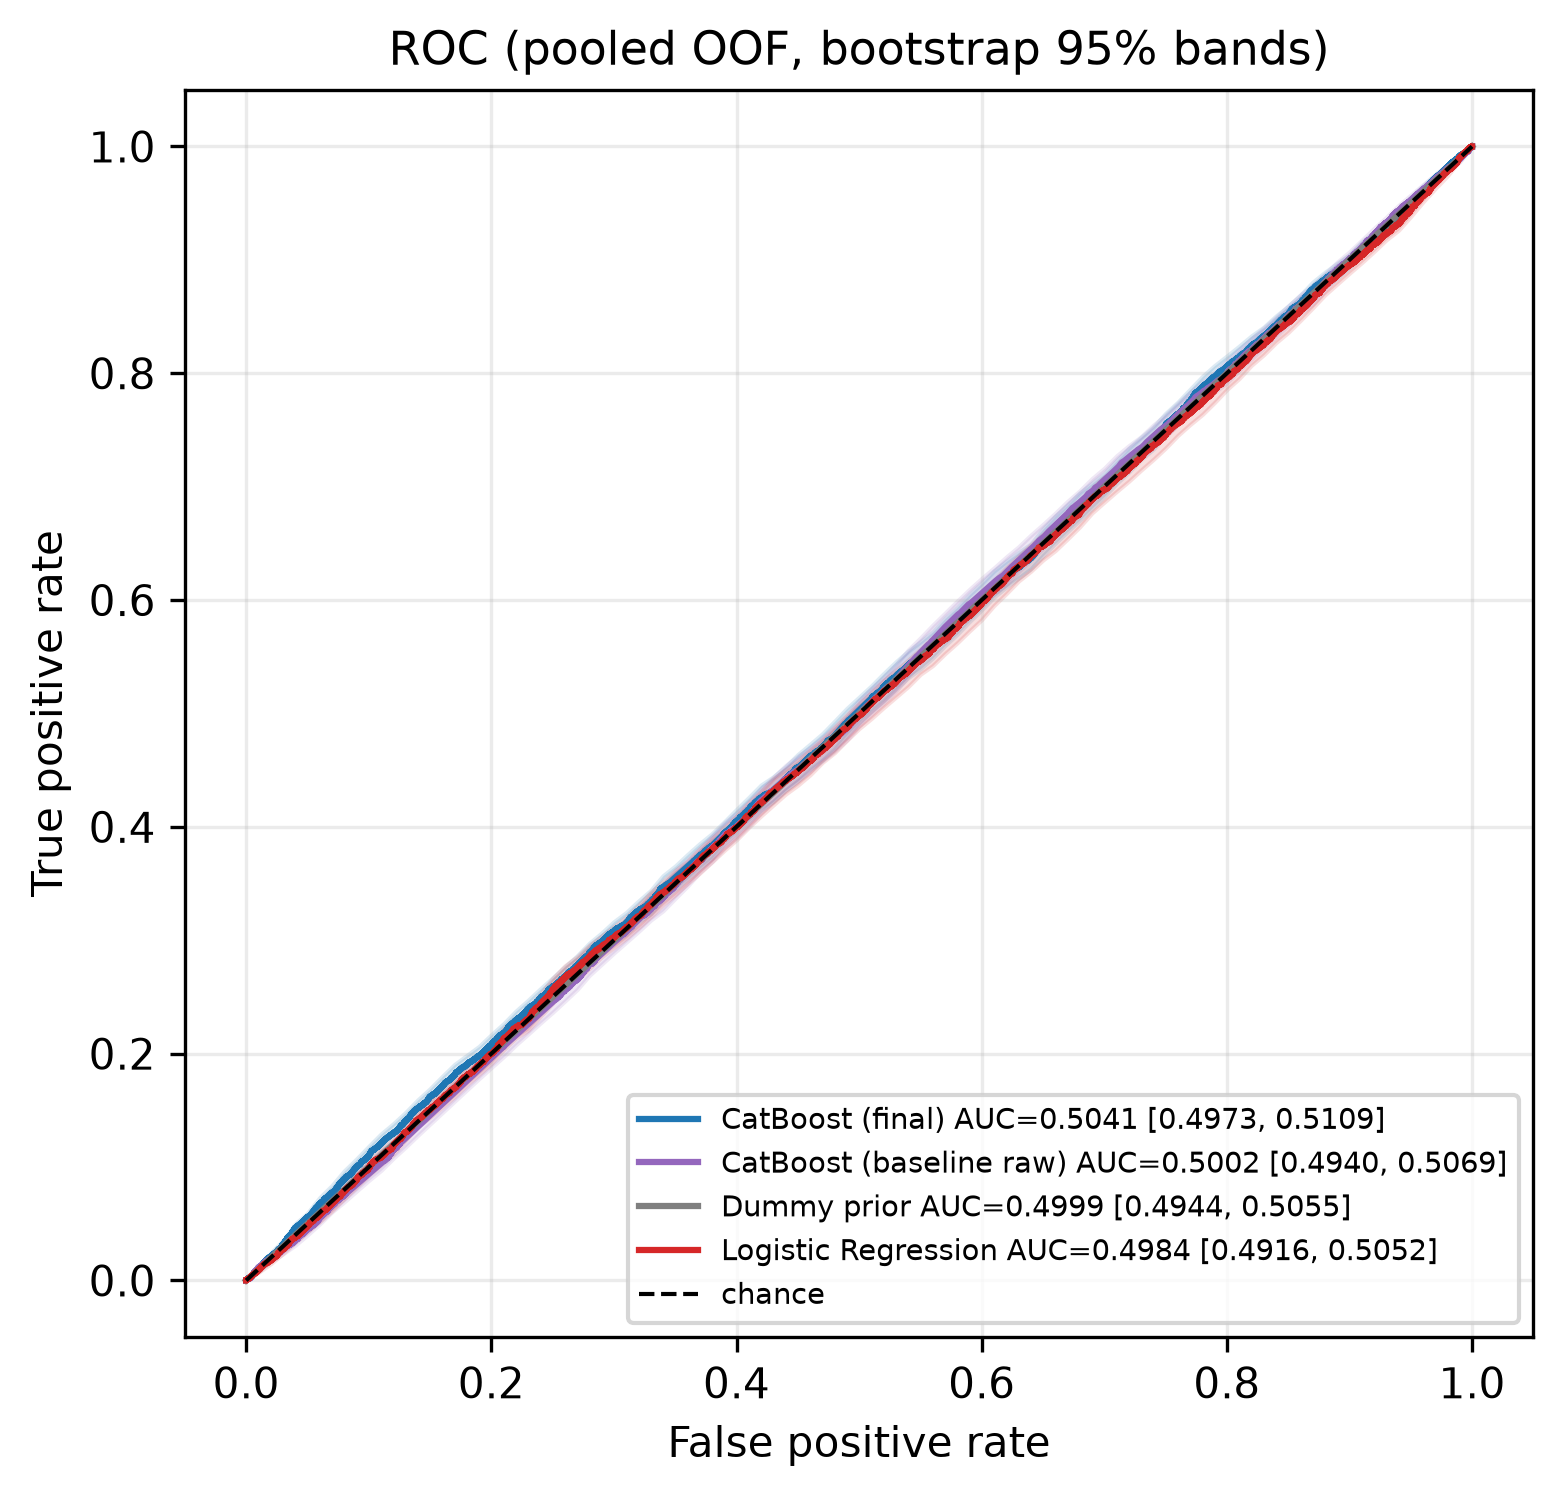

**Takeaway.** Pooled ROC-AUCs are 0.4984–0.5041: every curve stays within a few thousandths of the diagonal, and CatBoost's 95% interval is 0.4973–0.5108.

In [25]:
# Extract pooled ROC-AUC benchmarks and render comparative ROC curves
aucs = summary.set_index("model").pooled_roc_auc[["Dummy prior", "Logistic Regression", final_name]]
show_fig("fig_03_roc_curves", f"Pooled ROC-AUCs are {aucs.min():.4f}–{aucs.max():.4f}: every curve stays within a few thousandths of the diagonal, and CatBoost's 95% interval is {summary.set_index('model').loc[final_name, 'roc_auc_ci_lower']:.4f}–{summary.set_index('model').loc[final_name, 'roc_auc_ci_upper']:.4f}.")


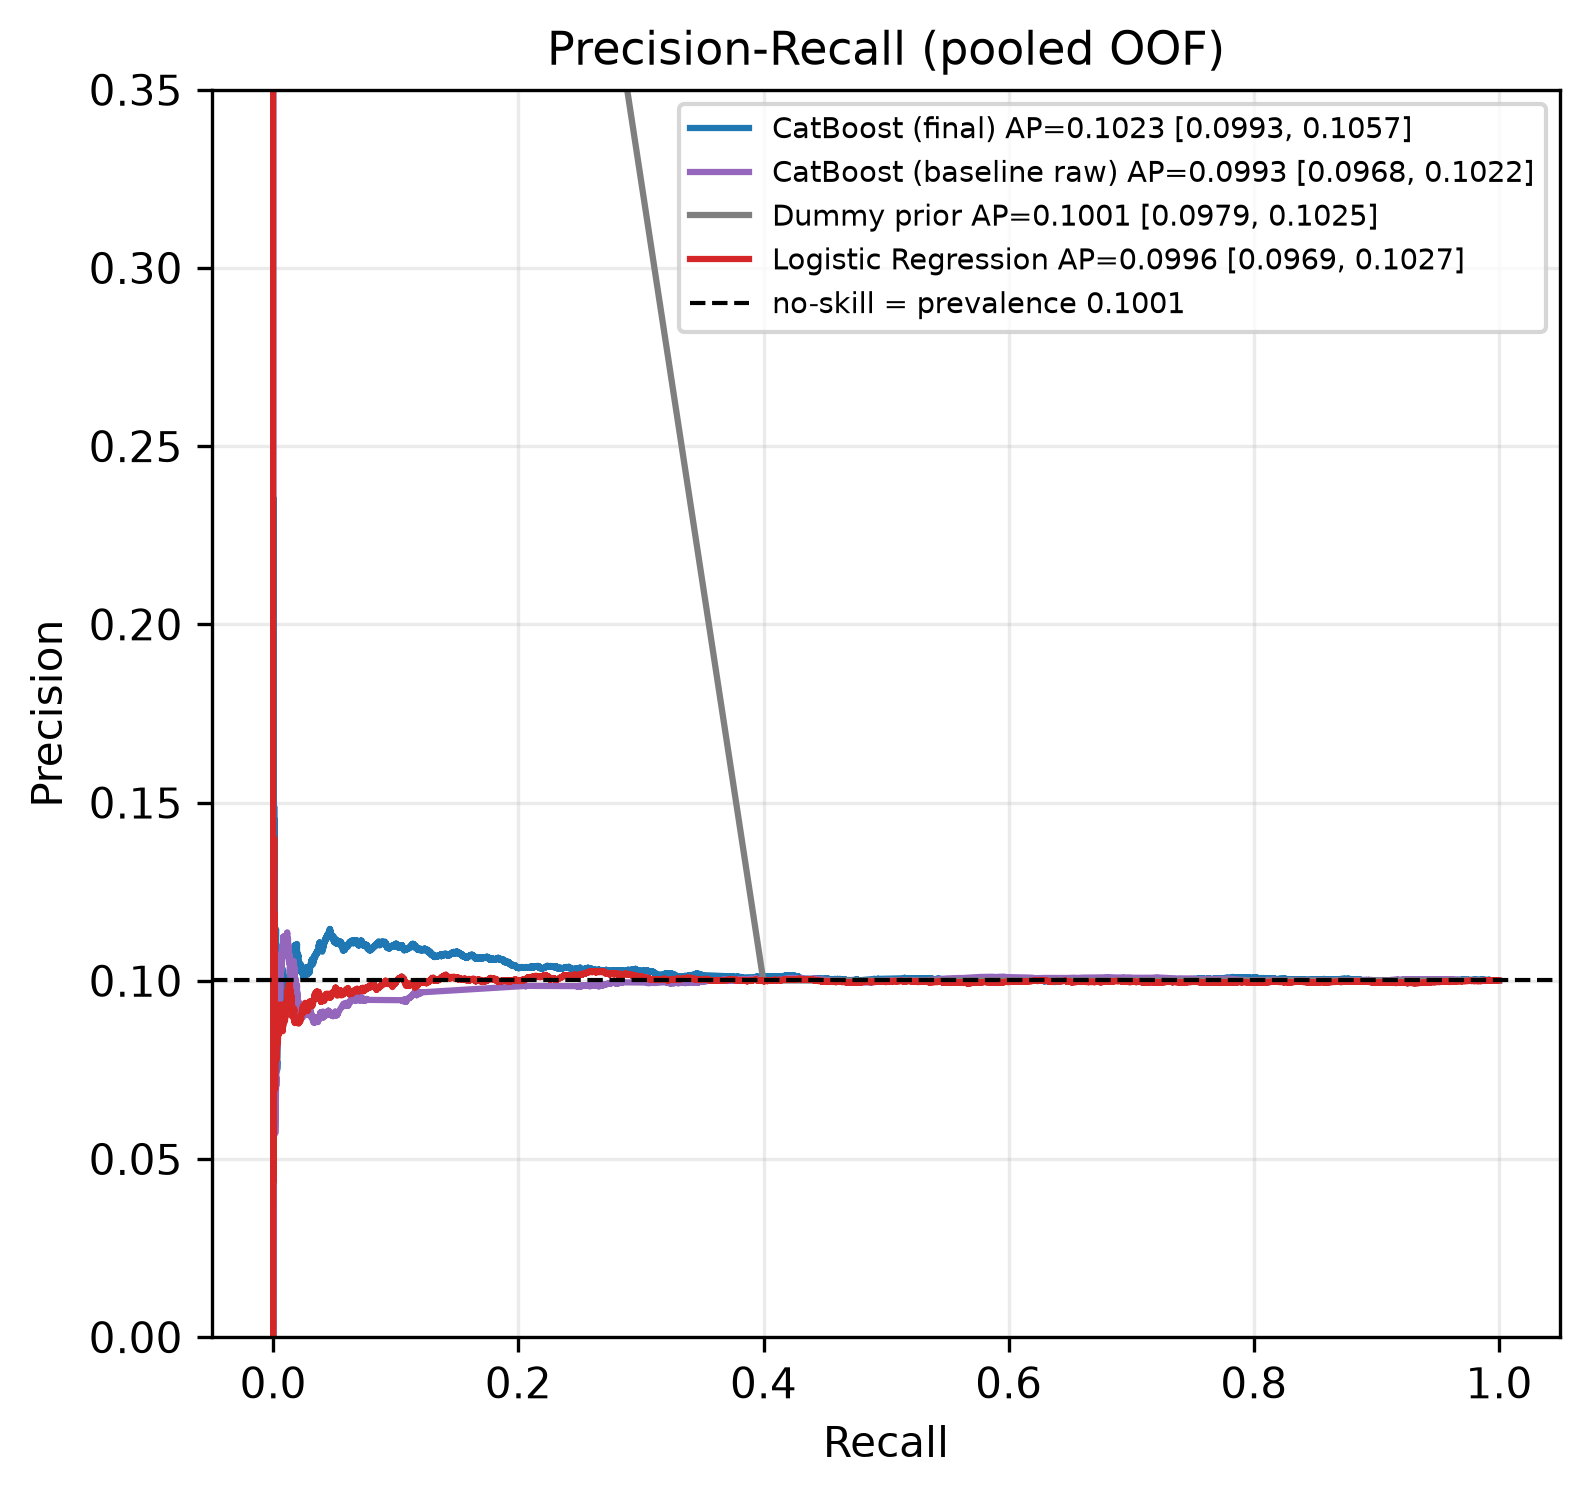

**Takeaway.** Pooled PR-AUCs are 0.0996–0.1022 against a no-skill level of 0.1001.

In [26]:
# Extract pooled PR-AUC benchmarks and render comparative Precision-Recall curves
aps = summary.set_index("model").pooled_pr_auc[["Dummy prior", "Logistic Regression", final_name]]
show_fig("fig_04_pr_curves", f"Pooled PR-AUCs are {aps.min():.4f}–{aps.max():.4f} against a no-skill level of {prevalence:.4f}.")


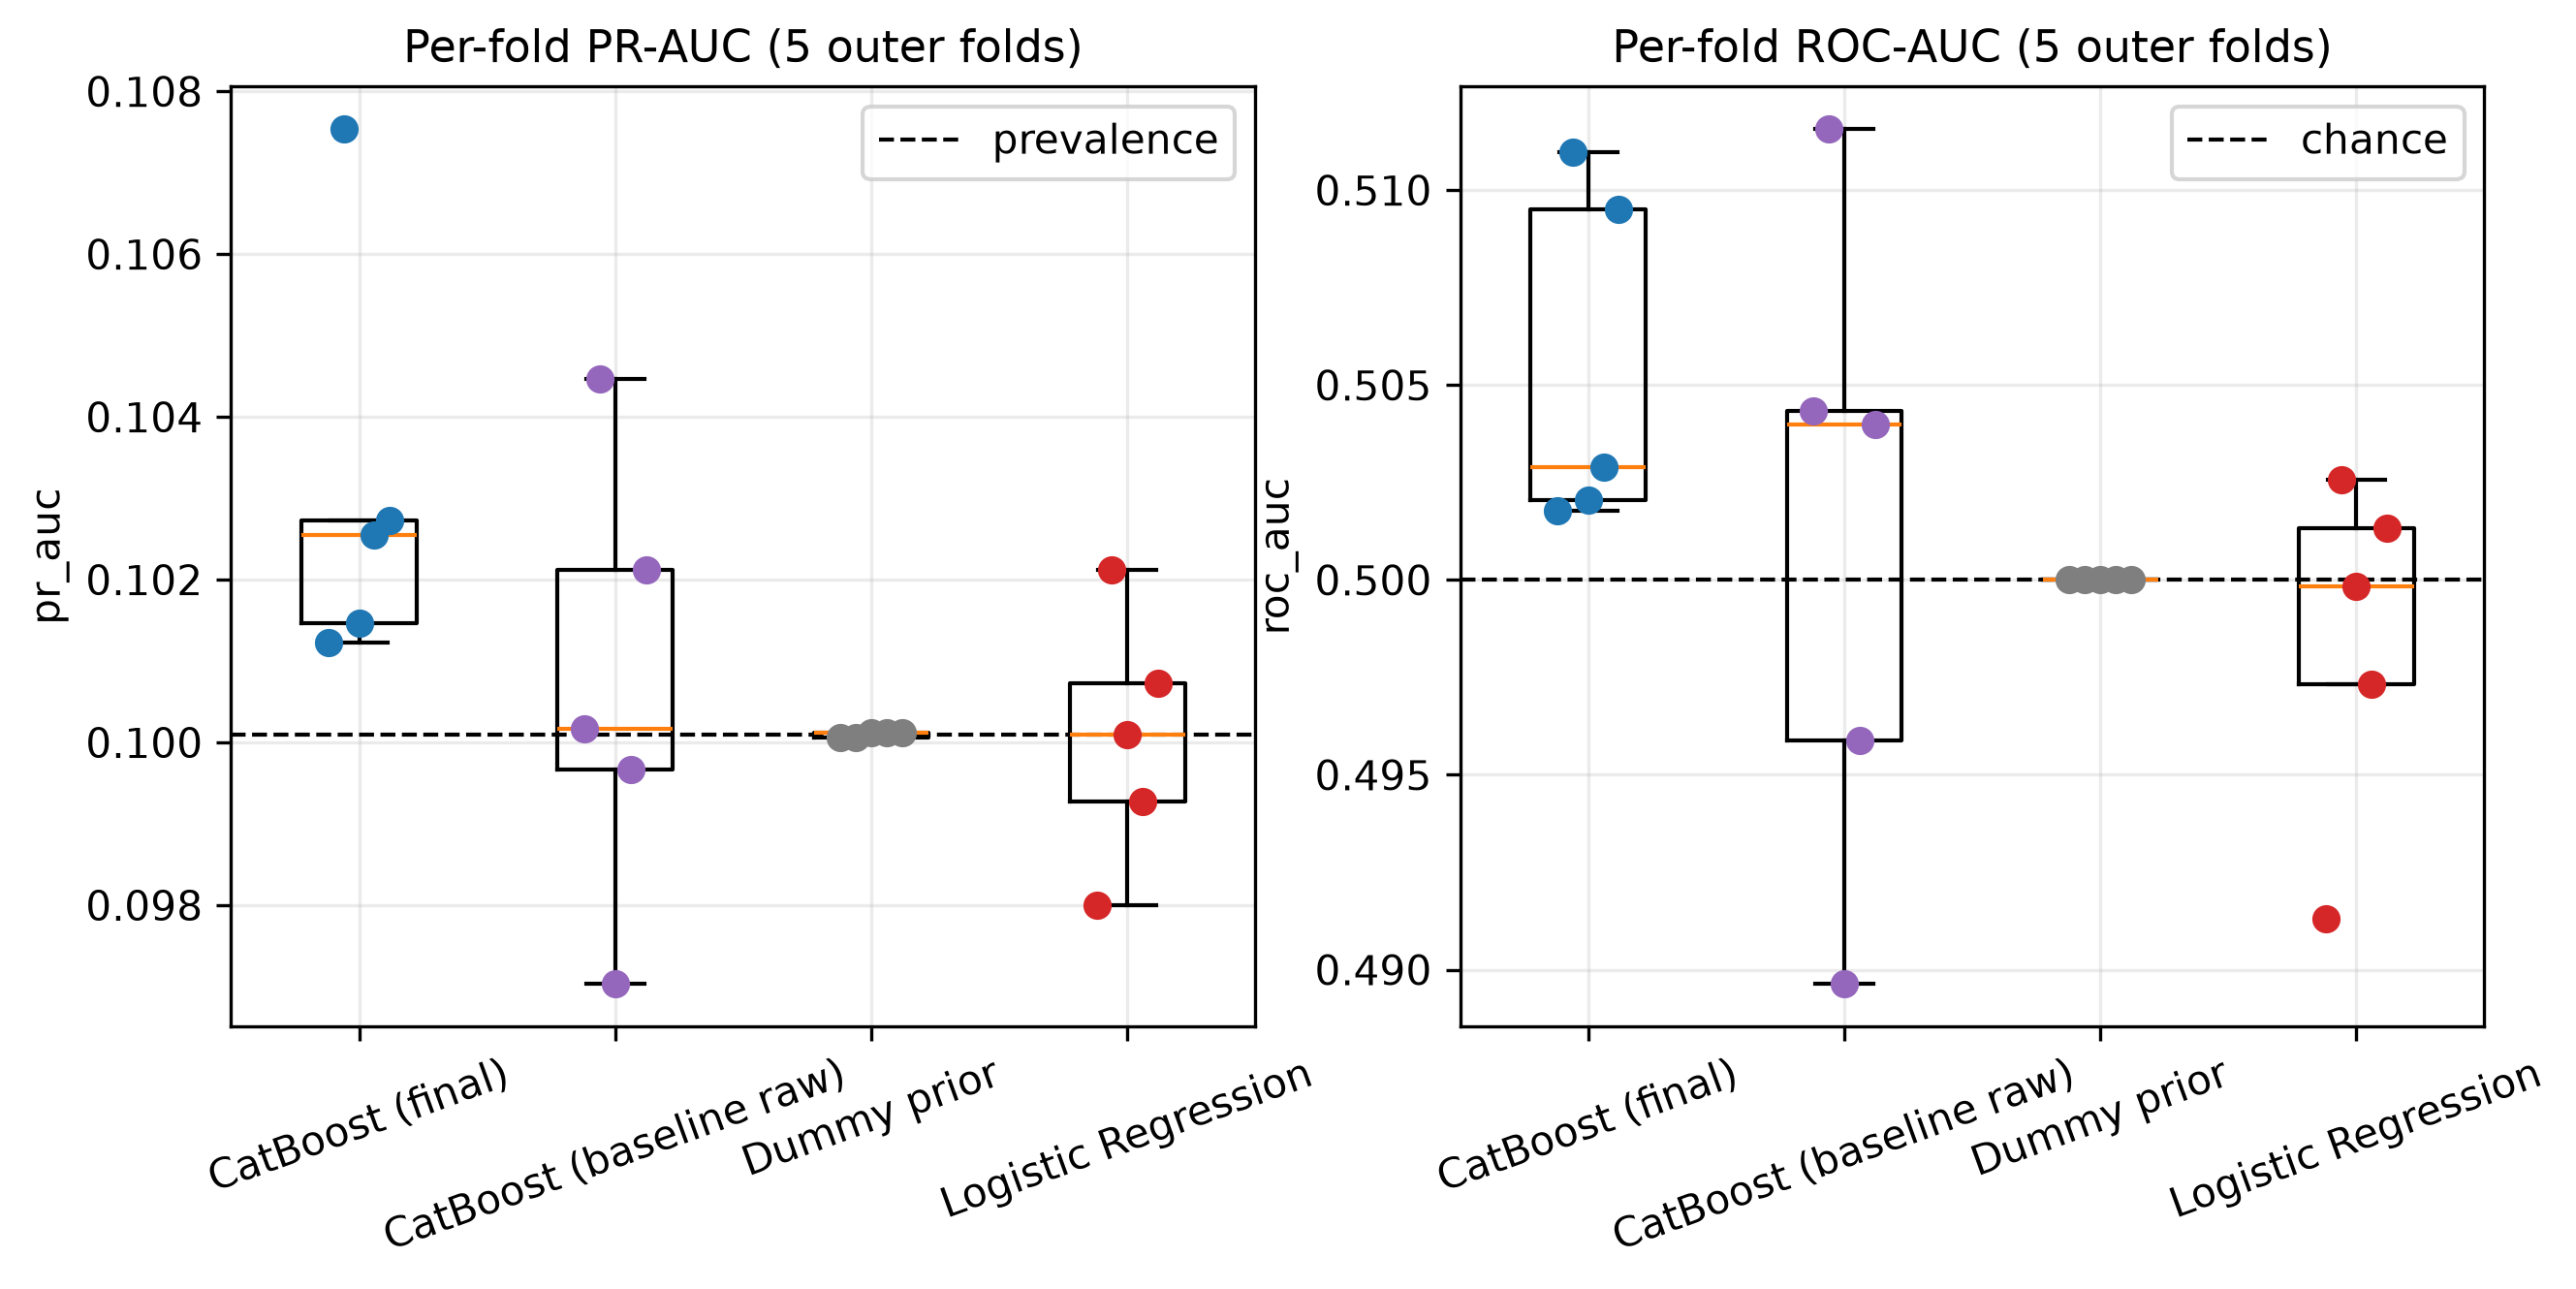

**Takeaway.** Fold-to-fold PR-AUC spread for CatBoost (0.1012–0.1075) brackets the prevalence line; no fold stands out.

In [27]:
# Load fold-level metrics across all models and render per-fold score distributions
fold_all = pd.read_csv(FIN / "fold_metrics_all_models.csv")
cb_f = fold_all[fold_all.model == final_name]
show_fig("fig_05_per_fold_metrics", f"Fold-to-fold PR-AUC spread for CatBoost ({cb_f.pr_auc.min():.4f}–{cb_f.pr_auc.max():.4f}) brackets the prevalence line; no fold stands out.")


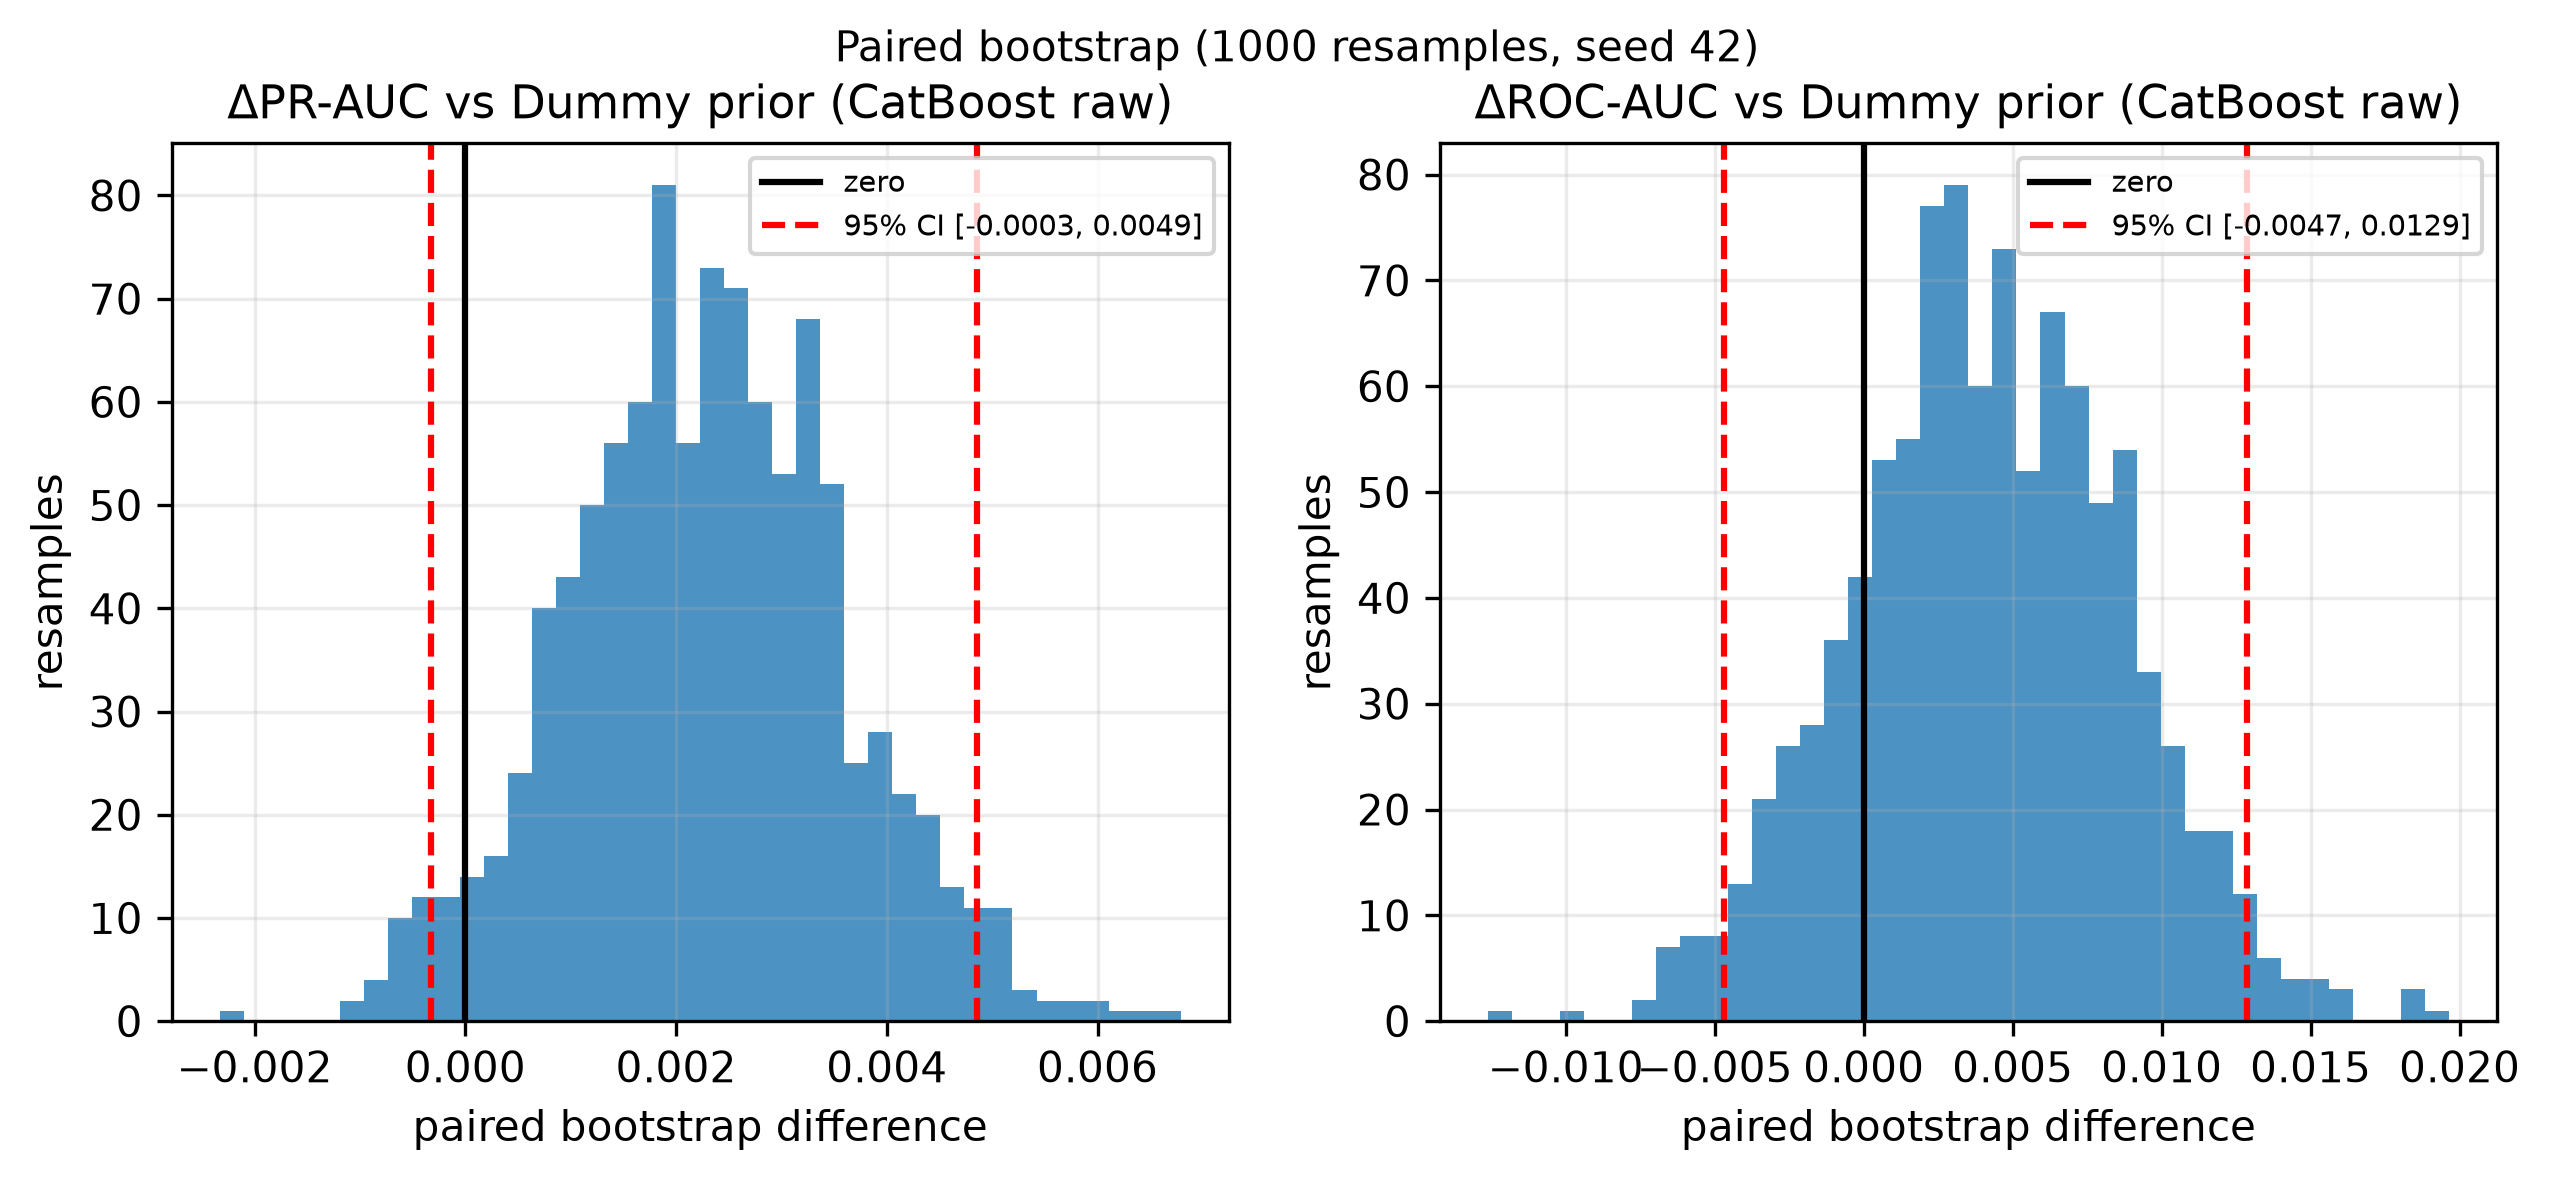

**Takeaway.** Paired bootstrap differences vs the prior baseline: ΔPR-AUC +0.0022, ΔROC-AUC +0.0042; both 95% intervals contain zero: True.

In [28]:
# Check whether 95% confidence intervals encompass zero and render paired bootstrap delta distributions
contains0 = (row.delta_pr_auc_ci_lower <= 0 <= row.delta_pr_auc_ci_upper) and (row.delta_roc_auc_ci_lower <= 0 <= row.delta_roc_auc_ci_upper)
show_fig("fig_06_bootstrap_delta_vs_prior", f"Paired bootstrap differences vs the prior baseline: ΔPR-AUC {row.delta_pr_auc:+.4f}, ΔROC-AUC {row.delta_roc_auc:+.4f}; both 95% intervals contain zero: {contains0}.")


## 8. Probability Calibration, Reliability Curves, and Operational Utility

- **Academic Objective:** Audit posterior probability calibration, assess cross-fitted scaling transforms (Platt scaling and Isotonic regression), and evaluate operational prioritization utility (Top-$k$ Lift).
- **Key Methodology / Theory:** In operational classification, probabilities must reflect empirical event frequencies. Scaling transforms are cross-fitted: maps are trained on 4 outer folds and applied to the 5th to prevent optimistic calibration leakage. Operational retention utility is evaluated via Top-$k$ Lift: assessing whether ranking employees by predicted probability captures more actual resignations than random outreach.
- **Expected Panel Takeaway:** Uncalibrated CatBoost v2.1.0 probabilities are already near-optimally calibrated (Brier 0.09008, matching the theoretical prevalence floor); Top-10% lift is 1.09 (capturing 10.9% of resignations vs 10.0% under random selection), establishing that retention targeting yields marginal utility on these features.

In [29]:
# Load calibration comparison table
cal = pd.read_csv(FIN / "calibration_comparison.csv")

# Display calibration metrics across raw, Platt, and Isotonic variants
display(cal)

# Extract selected probability calibration method and baseline reference metrics
chosen = verdict["calibration_choice"]
ref_row = summary.set_index("model").loc["Dummy prior"]
display(Markdown(f"Chosen probability source: **{chosen}**. Prevalence-only reference: Brier {ref_row.pooled_brier:.5f}, log loss {ref_row.pooled_log_loss:.5f}."))

# Load top-k operational ranking performance across all models
topk = pd.read_csv(FIN / "topk_all_models.csv")

# Display top-k recall and lift comparative summary
display(topk[topk.model.isin([final_name, "Dummy prior", "Logistic Regression"])].pivot(index="top_k", columns="model", values=["recall", "lift"]))


,model,pooled_brier,pooled_log_loss,pooled_pr_auc,pooled_roc_auc
0,CatBoost (raw),0.09008,0.32529,0.10225,0.50410
1,CatBoost (platt),0.09008,0.32529,0.10226,0.50413
2,CatBoost (isotonic),0.09014,0.34497,0.10155,0.50498


Chosen probability source: **CatBoost (platt)**. Prevalence-only reference: Brier 0.09008, log loss 0.32530.

recall                                           lift                                
model   CatBoost (raw) Dummy prior Logistic Regression CatBoost (raw) Dummy prior Logistic Regression
top_k                                                                                                
0.01000        0.00974     0.00987             0.00912        0.97403     0.98651             0.91159
0.05000        0.05519     0.05107             0.04820        1.10390     1.02148             0.96404
0.10000        0.10914     0.10027             0.09928        1.09141     1.00275             0.99276
0.20000        0.20729     0.19943             0.19993        1.03646     0.99713             0.99963
0.30000        0.30707     0.29870             0.30220        1.02356     0.99567             1.00733
0.50000        0.50325     0.50312             0.49813        1.00649     1.00624             0.99625

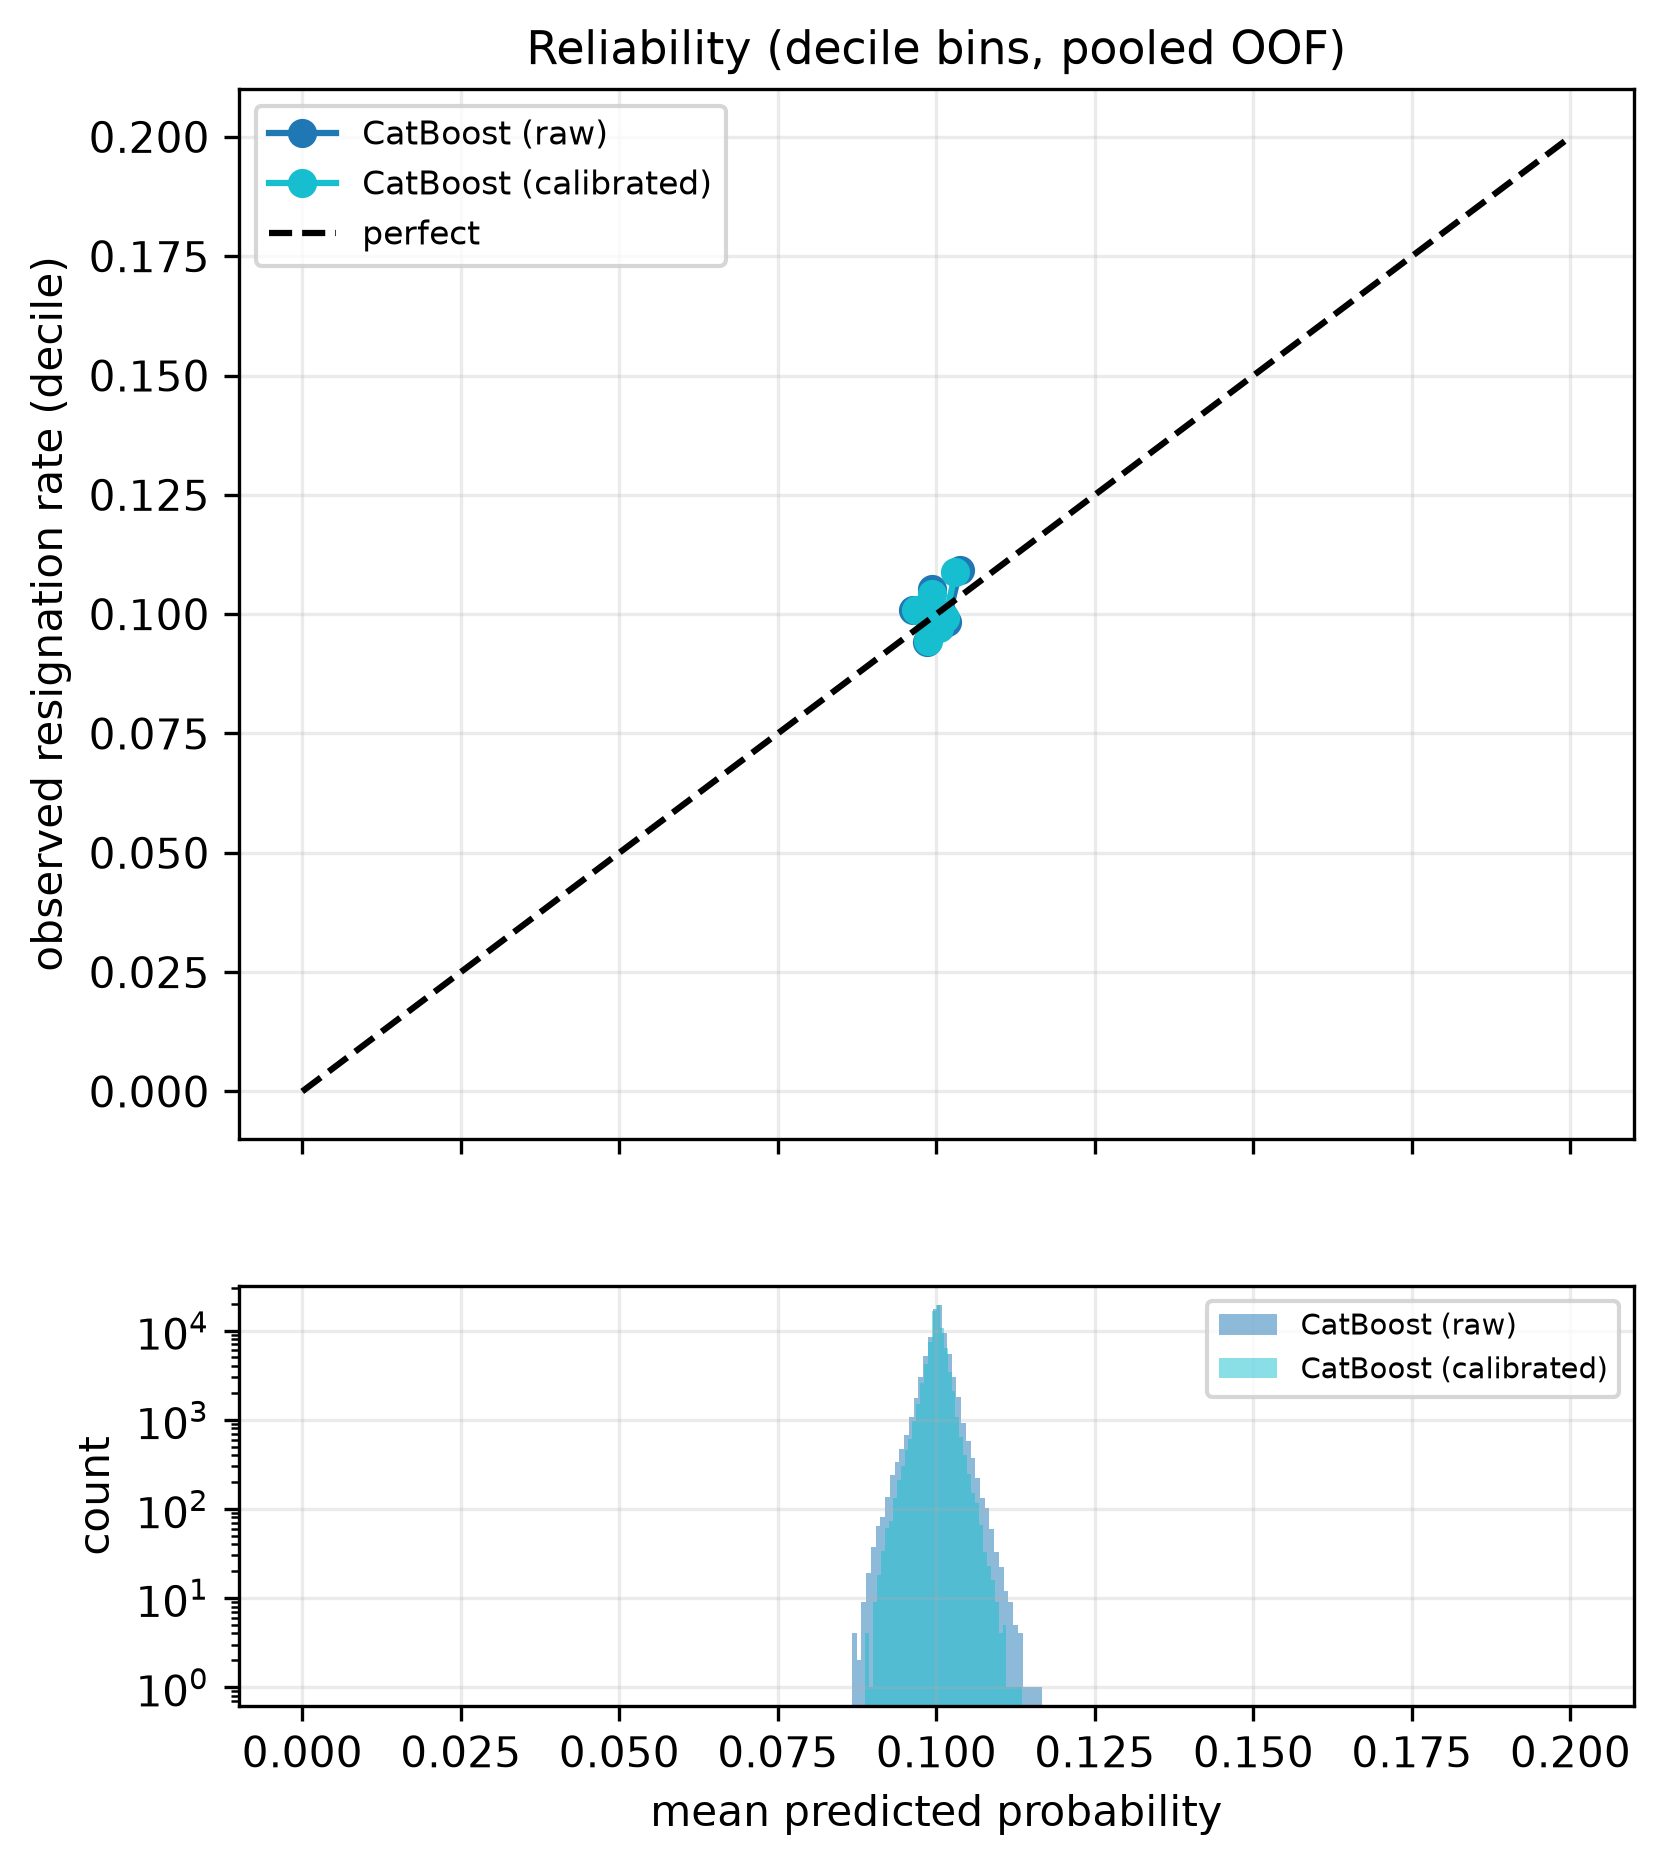

**Takeaway.** Raw and calibrated CatBoost probabilities collapse into a narrow band around the base rate; calibration repairs the scale, not the ranking.

In [31]:
# Render Figure 10: Reliability curves comparing predicted probabilities against empirical frequencies
show_fig("fig_10_reliability", "Raw and calibrated CatBoost probabilities collapse into a narrow band around the base rate; calibration repairs the scale, not the ranking.")


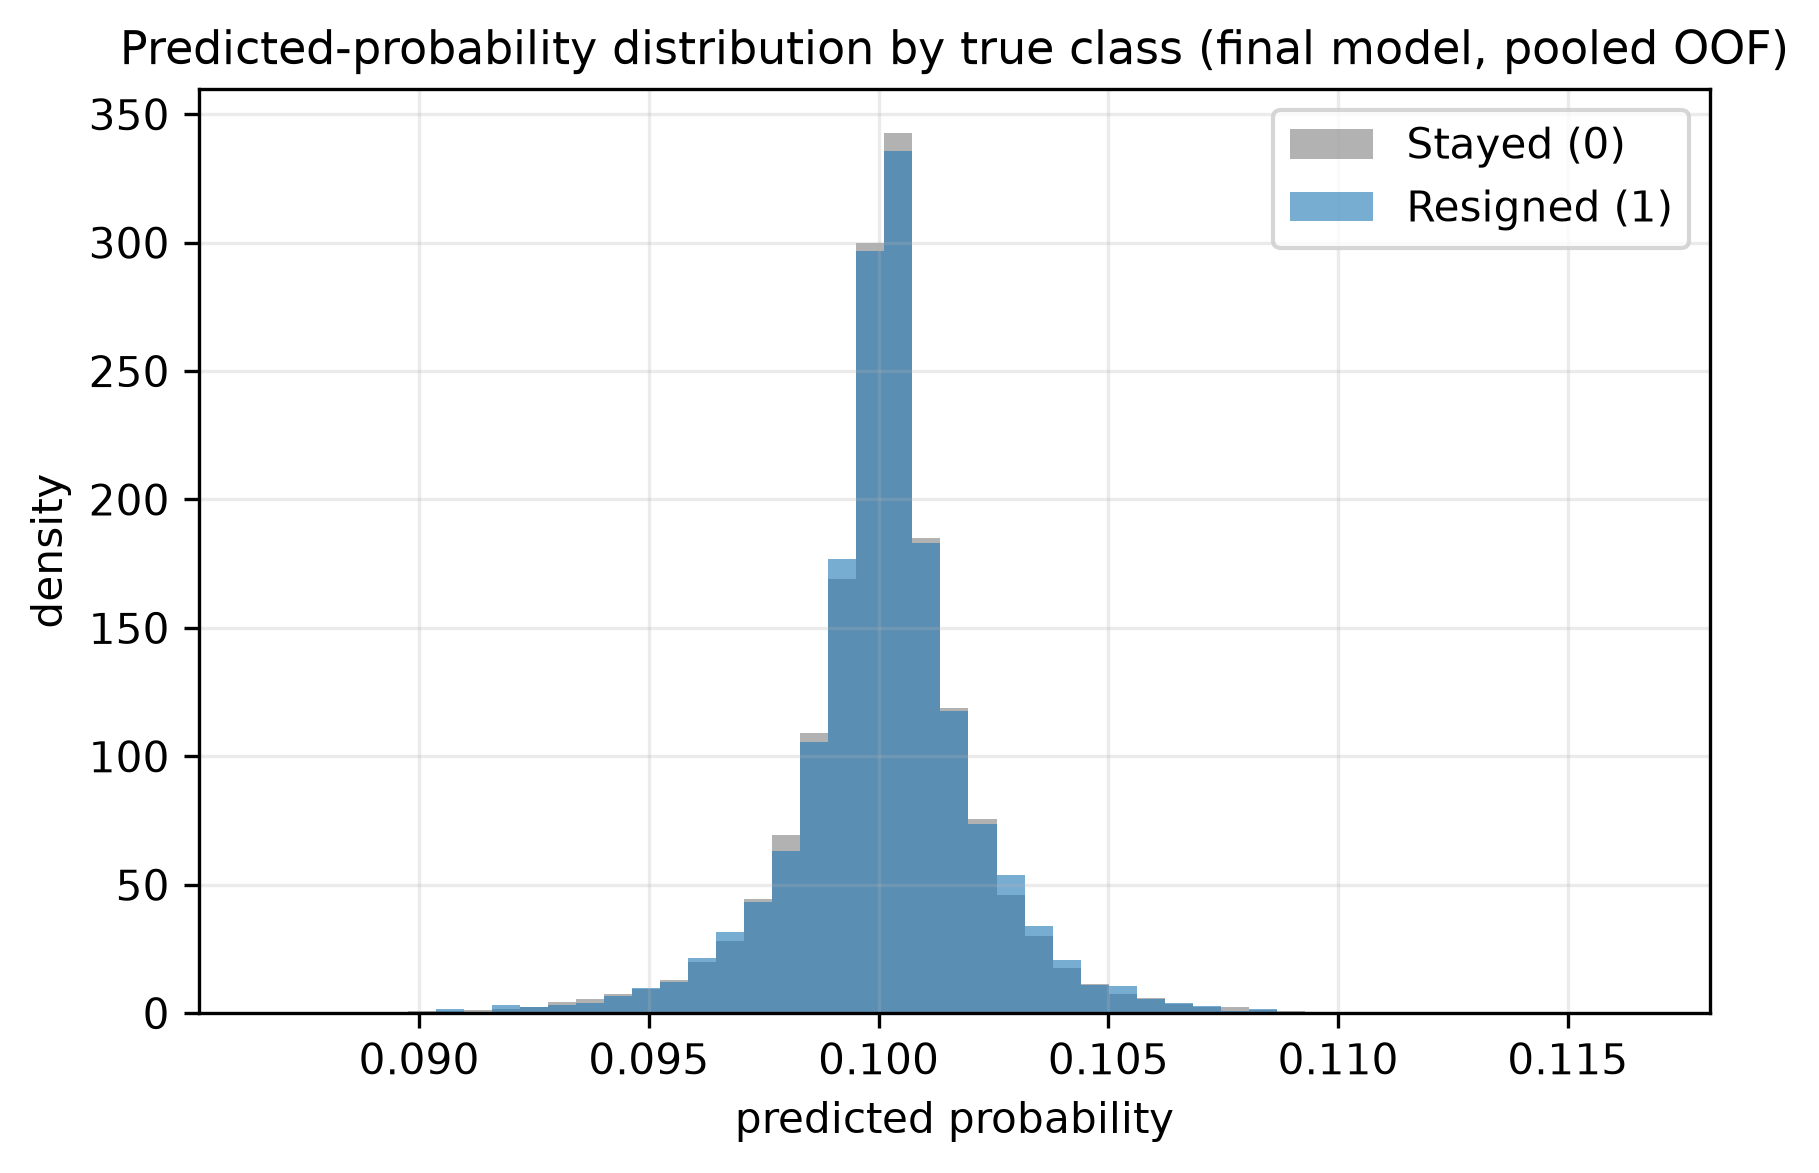

**Takeaway.** Predicted-probability distributions for resigned and stayed employees overlap almost completely.

In [30]:
# Render Figure 11: Predicted probability distributions separated by true resignation class
show_fig("fig_11_probability_by_class", "Predicted-probability distributions for resigned and stayed employees overlap almost completely.")


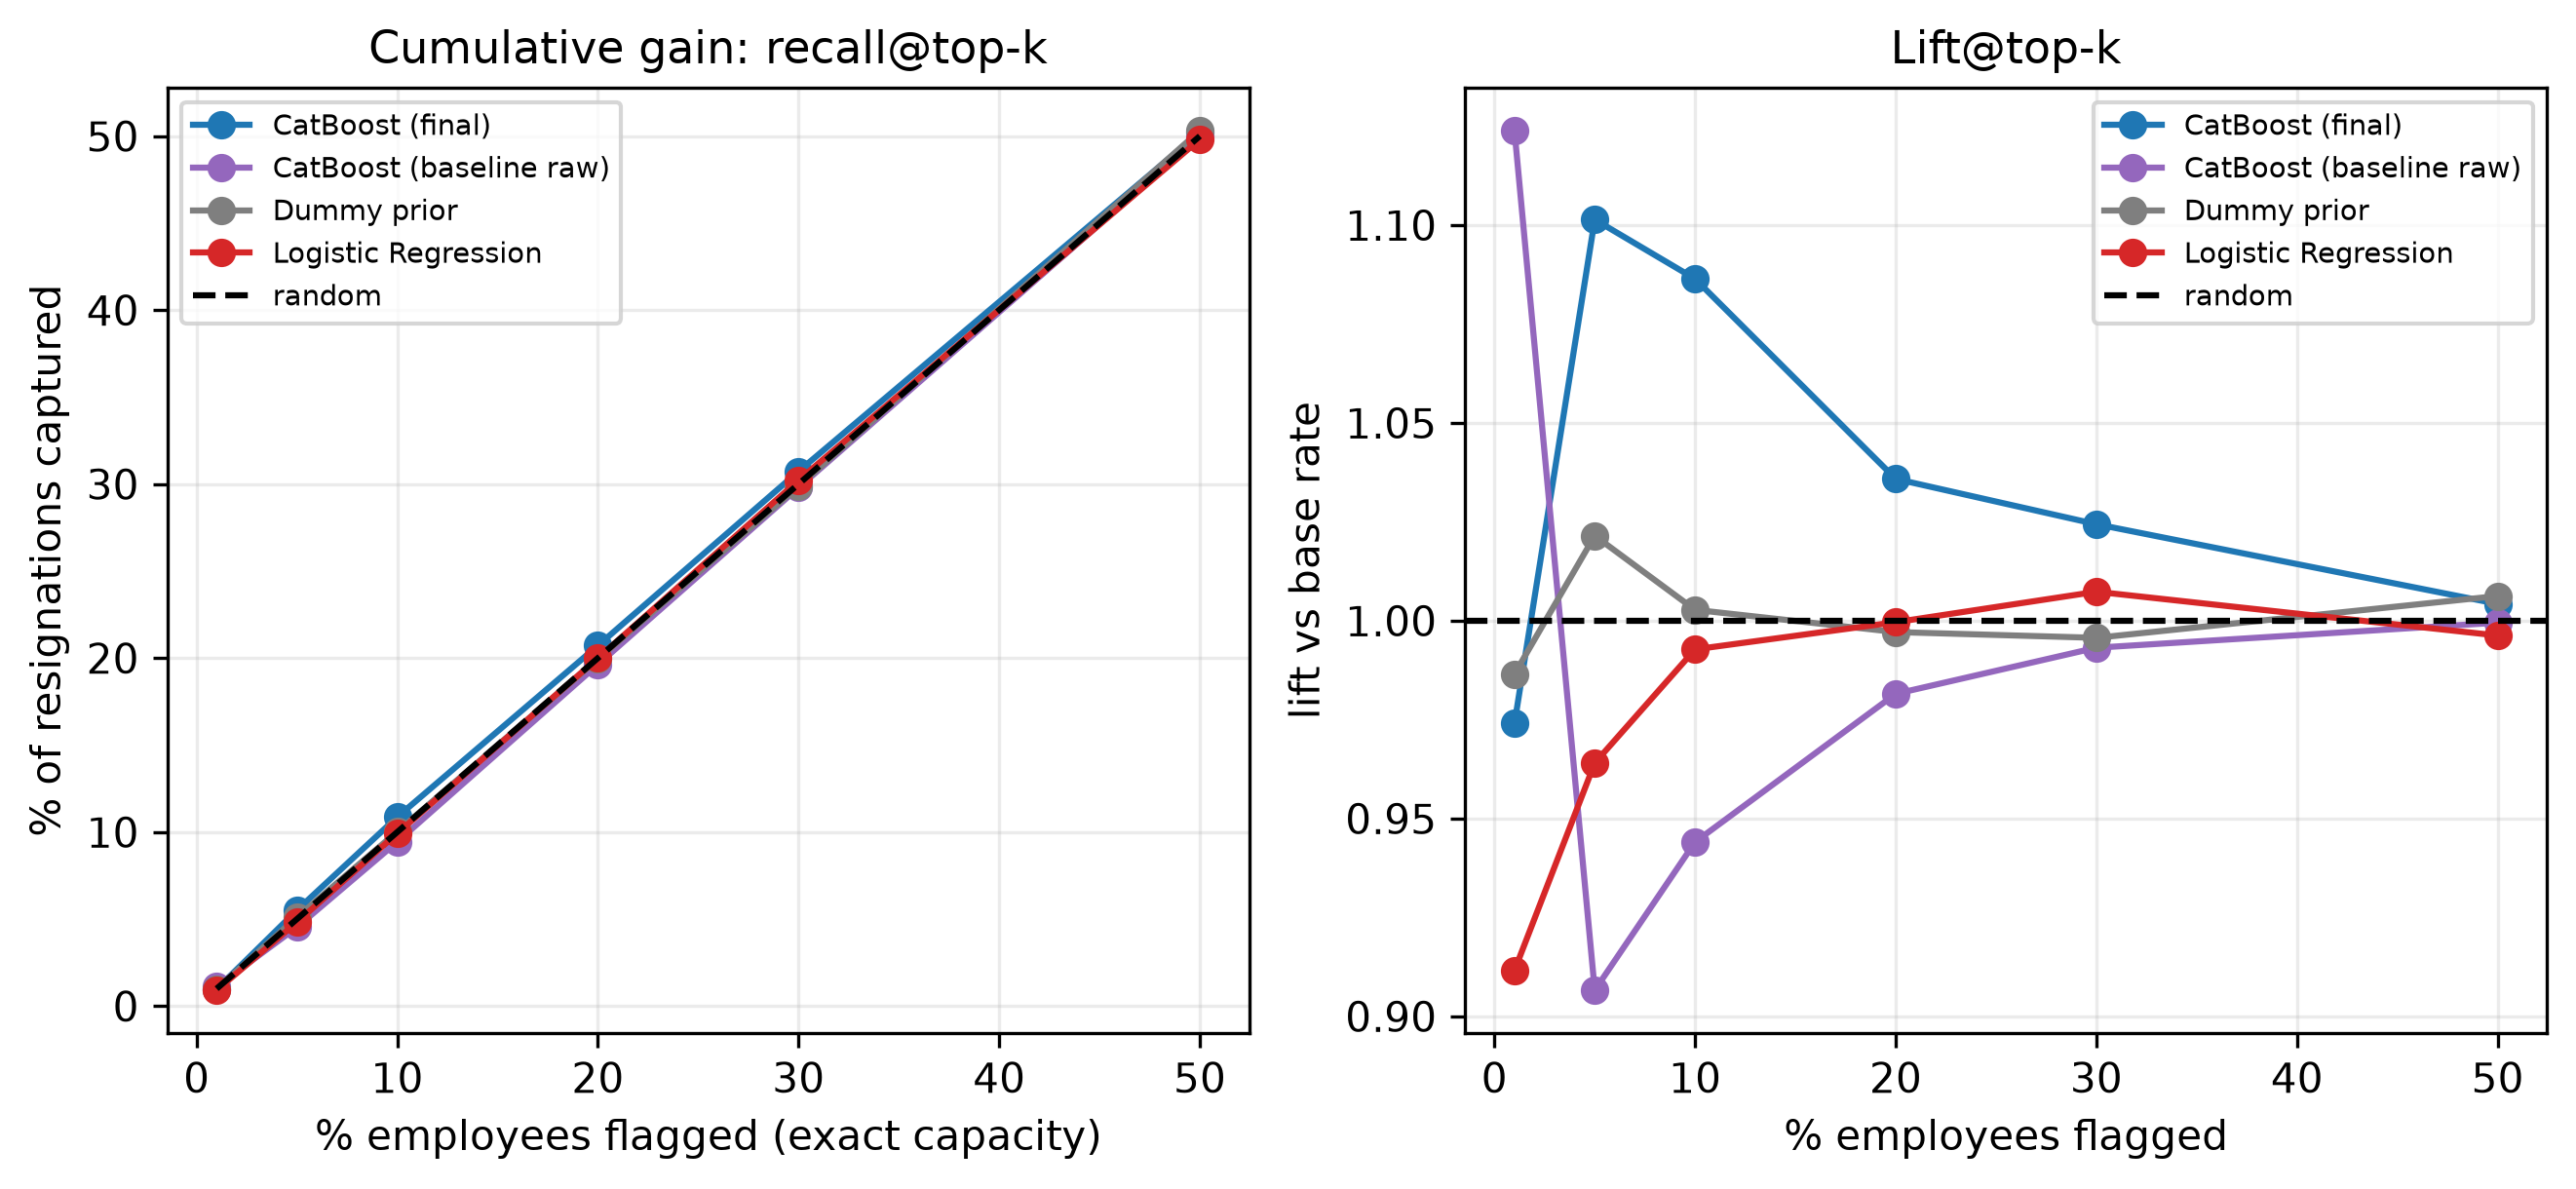

**Takeaway.** Flagging the top 10% captures 10.9% of resignations (lift 1.09), i.e. what random selection would give.

In [32]:
# Filter top-k metrics for headline model and render cumulative gain and lift curves
tk = topk[(topk.model == final_name)]
show_fig("fig_12_gain_lift", f"Flagging the top 10% captures {tk[np.isclose(tk.top_k, 0.10)].recall.iloc[0]:.1%} of resignations (lift {tk[np.isclose(tk.top_k, 0.10)].lift.iloc[0]:.2f}), i.e. what random selection would give.")


### 8.1 Operational Decision Thresholds and Confusion Matrix Diagnostics

- **Academic Objective:** Audit and resolve the classification threshold pathology on imbalanced, calibrated probabilities, contrasting the default $\tau=0.50$ cutoff against empirical base-rate ($\tau=0.1001$) and capacity-constrained Top-10% budget thresholds.
- **Key Methodology / Theory:** In binary classification under severe class imbalance (10.01% positive prevalence), a properly calibrated probabilistic model (such as CatBoost with `boost_from_average=True`, achieving the optimal Brier score floor of 0.09008) produces probabilities tightly centered at the empirical prior ($\hat{p} \in [0.0867, 0.1166]$). An unadjusted, symmetric decision threshold of $\tau = 0.50$ is mathematically unreachable ($\max(\hat{p}) = 0.1166 < 0.50$), causing all predictions to default to negative (0 True Positives, 0% Recall). In production and HR decision-making, we decouple probability calibration from threshold selection: evaluating at the base-rate cutoff ($\tau = 0.10010$) or capacity-constrained intervention budgets.
- **Expected Panel Takeaway:** Evaluating models at the empirical prevalence cutoff ($\tau = 0.10010$) captures 4,240 True Positives (52.95% Recall), while an HR capacity-constrained Top-10% budget cutoff ($\tau = 0.10226$) isolates 874 True Positives with 10.92% Precision and 1.09× Lift.

CatBoost Operational Confusion Matrices Across Decision Thresholds (80,000 Development Rows):


,policy,decision_threshold,flagged_count,flagged_rate,true_negatives_tn,false_positives_fp,false_negatives_fn,true_positives_tp,precision,recall,f1_score,balanced_accuracy
0,Default 0.50 Cutoff,0.50000,0,0.00000,71992,0,8008,0,0.00000,0.00000,0.00000,0.50000
1,Base-Rate Prevalence,0.10010,42088,0.52610,34144,37848,3768,4240,0.10070,0.52950,0.16930,0.50190
2,Top 10% Budget Capacity,0.10226,8000,0.10000,64866,7126,7134,874,0.10920,0.10910,0.10920,0.50510
3,Top 20% Budget Capacity,0.10134,16000,0.20000,57652,14340,6348,1660,0.10370,0.20730,0.13830,0.50410


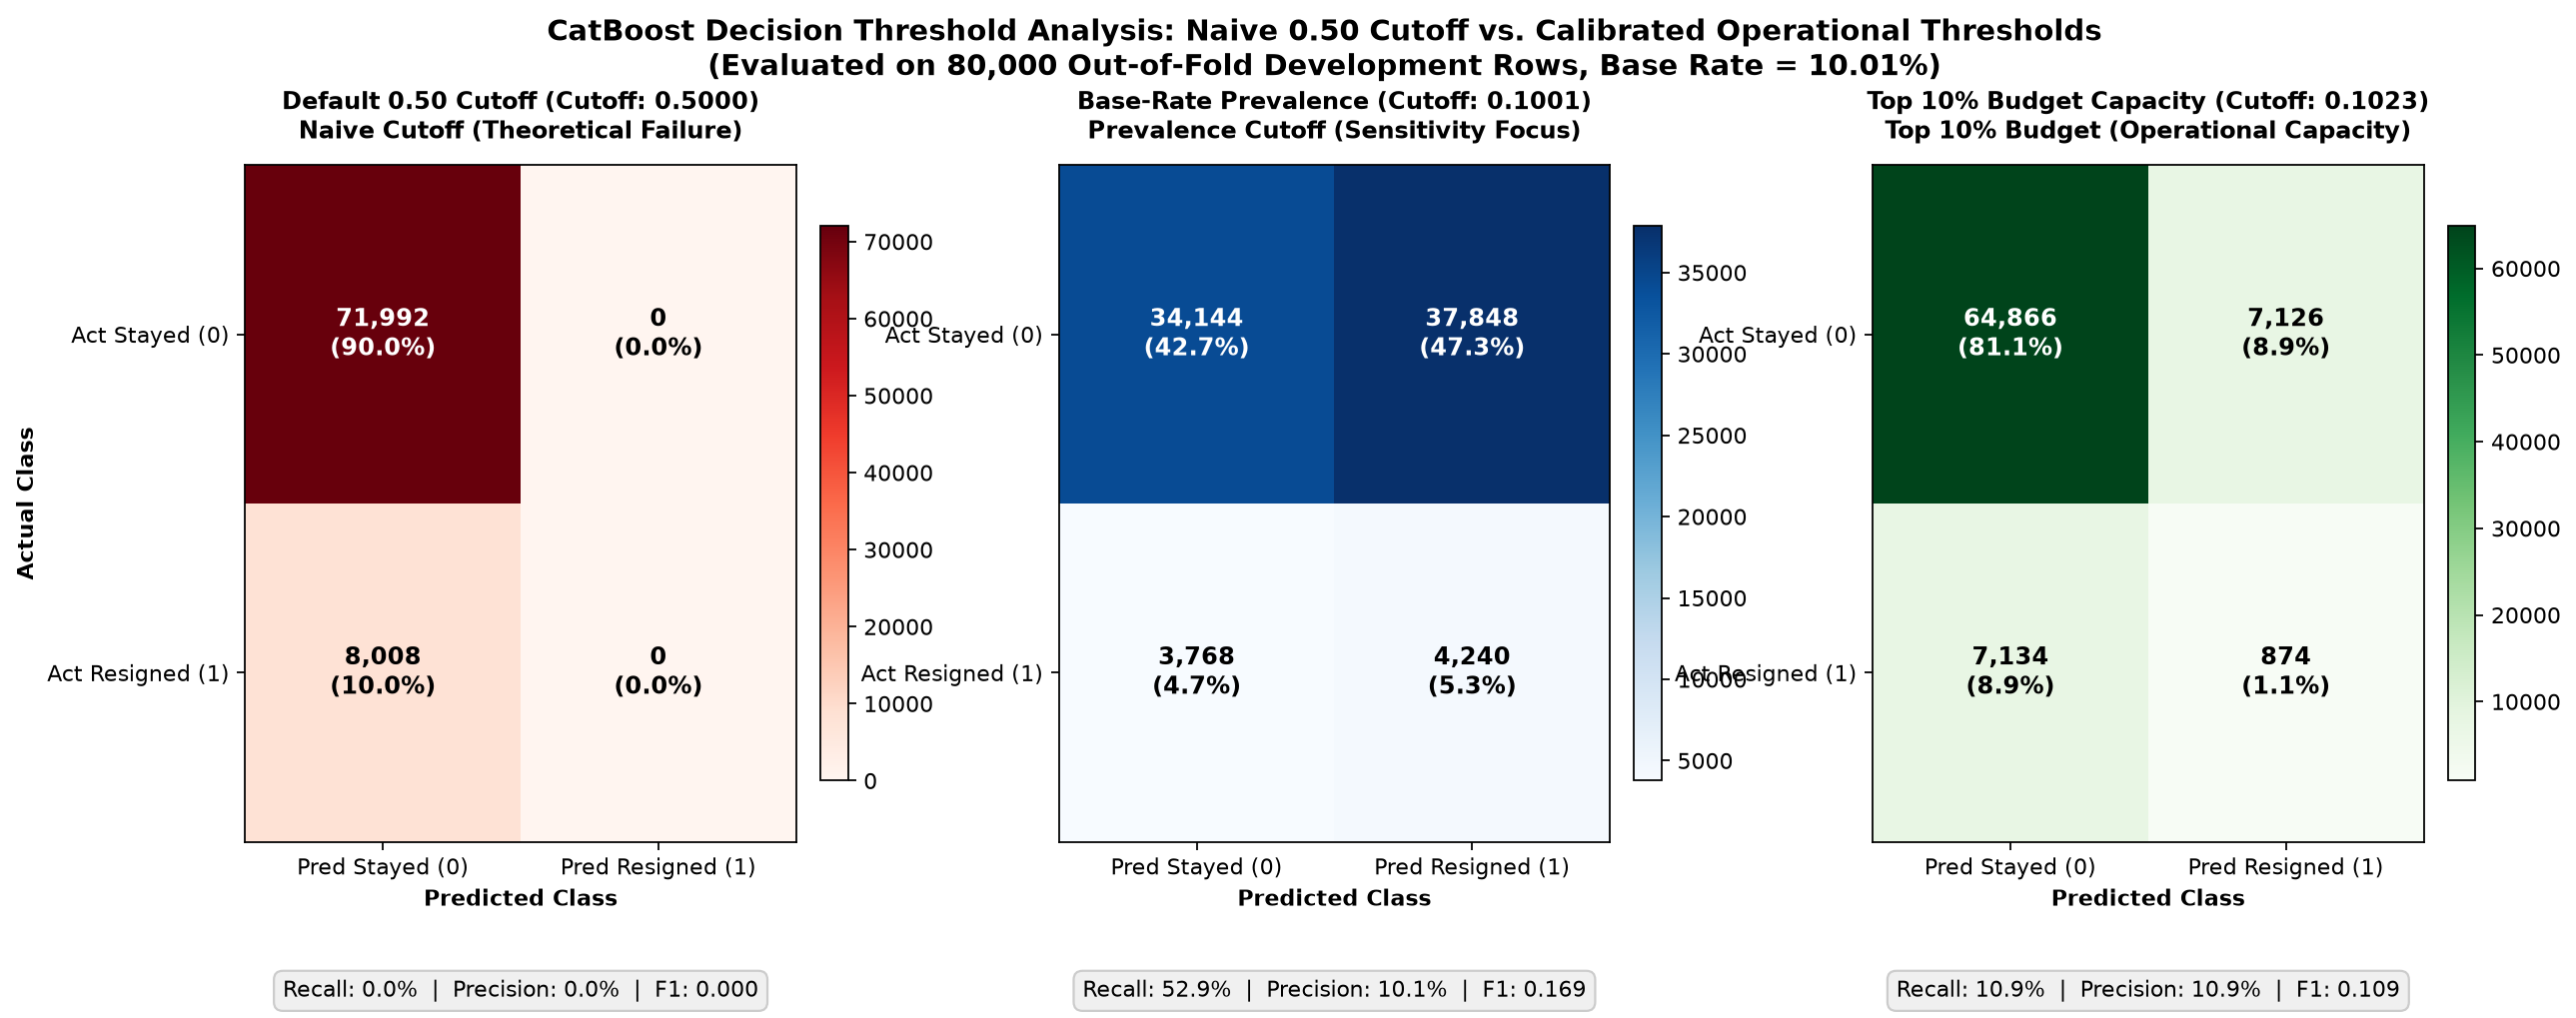

**Takeaway.** The default 0.50 cutoff yields zero predicted positives because calibrated probabilities never exceed 0.1166. At the empirical base-rate threshold ($\tau = 0.10010$), the model captures 4,240 True Positives (52.95% Recall). Under a Top 10% HR intervention budget ($\tau = 0.10226$), 874 True Positives are prioritized with 10.92% Precision (1.09× Lift).

In [33]:
# Load operational confusion matrix comparison table across decision thresholds
op_cm_path = CB / "catboost_operational_confusion_matrix.csv"
assert op_cm_path.exists(), f"Operational confusion matrix missing at: {op_cm_path}"

op_cm_df = pd.read_csv(op_cm_path)
print("CatBoost Operational Confusion Matrices Across Decision Thresholds (80,000 Development Rows):")
display(op_cm_df[[
    "policy", "decision_threshold", "flagged_count", "flagged_rate",
    "true_negatives_tn", "false_positives_fp", "false_negatives_fn", "true_positives_tp",
    "precision", "recall", "f1_score", "balanced_accuracy"
]])

# Render Figure: Operational Confusion Matrix Visual Comparison
op_fig_path = CB / "figure_operational_confusion_matrix.png"
if op_fig_path.exists():
    display(Image(filename=str(op_fig_path), width=920))
    display(Markdown(
        "**Takeaway.** The default 0.50 cutoff yields zero predicted positives because calibrated probabilities never exceed 0.1166. "
        "At the empirical base-rate threshold ($\\tau = 0.10010$), the model captures 4,240 True Positives (52.95% Recall). "
        "Under a Top 10% HR intervention budget ($\\tau = 0.10226$), 874 True Positives are prioritized with 10.92% Precision (1.09× Lift)."
    ))

## 9. Feature Attribution and Demographic Subgroup Analysis

- **Academic Objective:** Audit model interpretability via global split importance (PredictionValuesChange), out-of-fold permutation importance, TreeSHAP values, and demographic subgroup parity.
- **Key Methodology / Theory:** When true predictive signal is negligible, tree algorithms frequently split on sample noise. We cross-examine internal split importance against out-of-fold permutation importance (measuring $\Delta\text{PR-AUC}$ when feature values are permuted on validation sets). Local attribution is computed via TreeSHAP. Disaggregated subgroup analyses across `Department`, `Gender`, and `Education_Level` evaluate predictive stability across demographic partitions.
- **Expected Panel Takeaway:** Feature importances are unstable across folds (median CV = 0.44); permuting any single predictor impacts PR-AUC by $\le 0.0004$; SHAP values are near zero; subgroup metrics remain tightly clustered near group base rates, demonstrating no demographic bias.

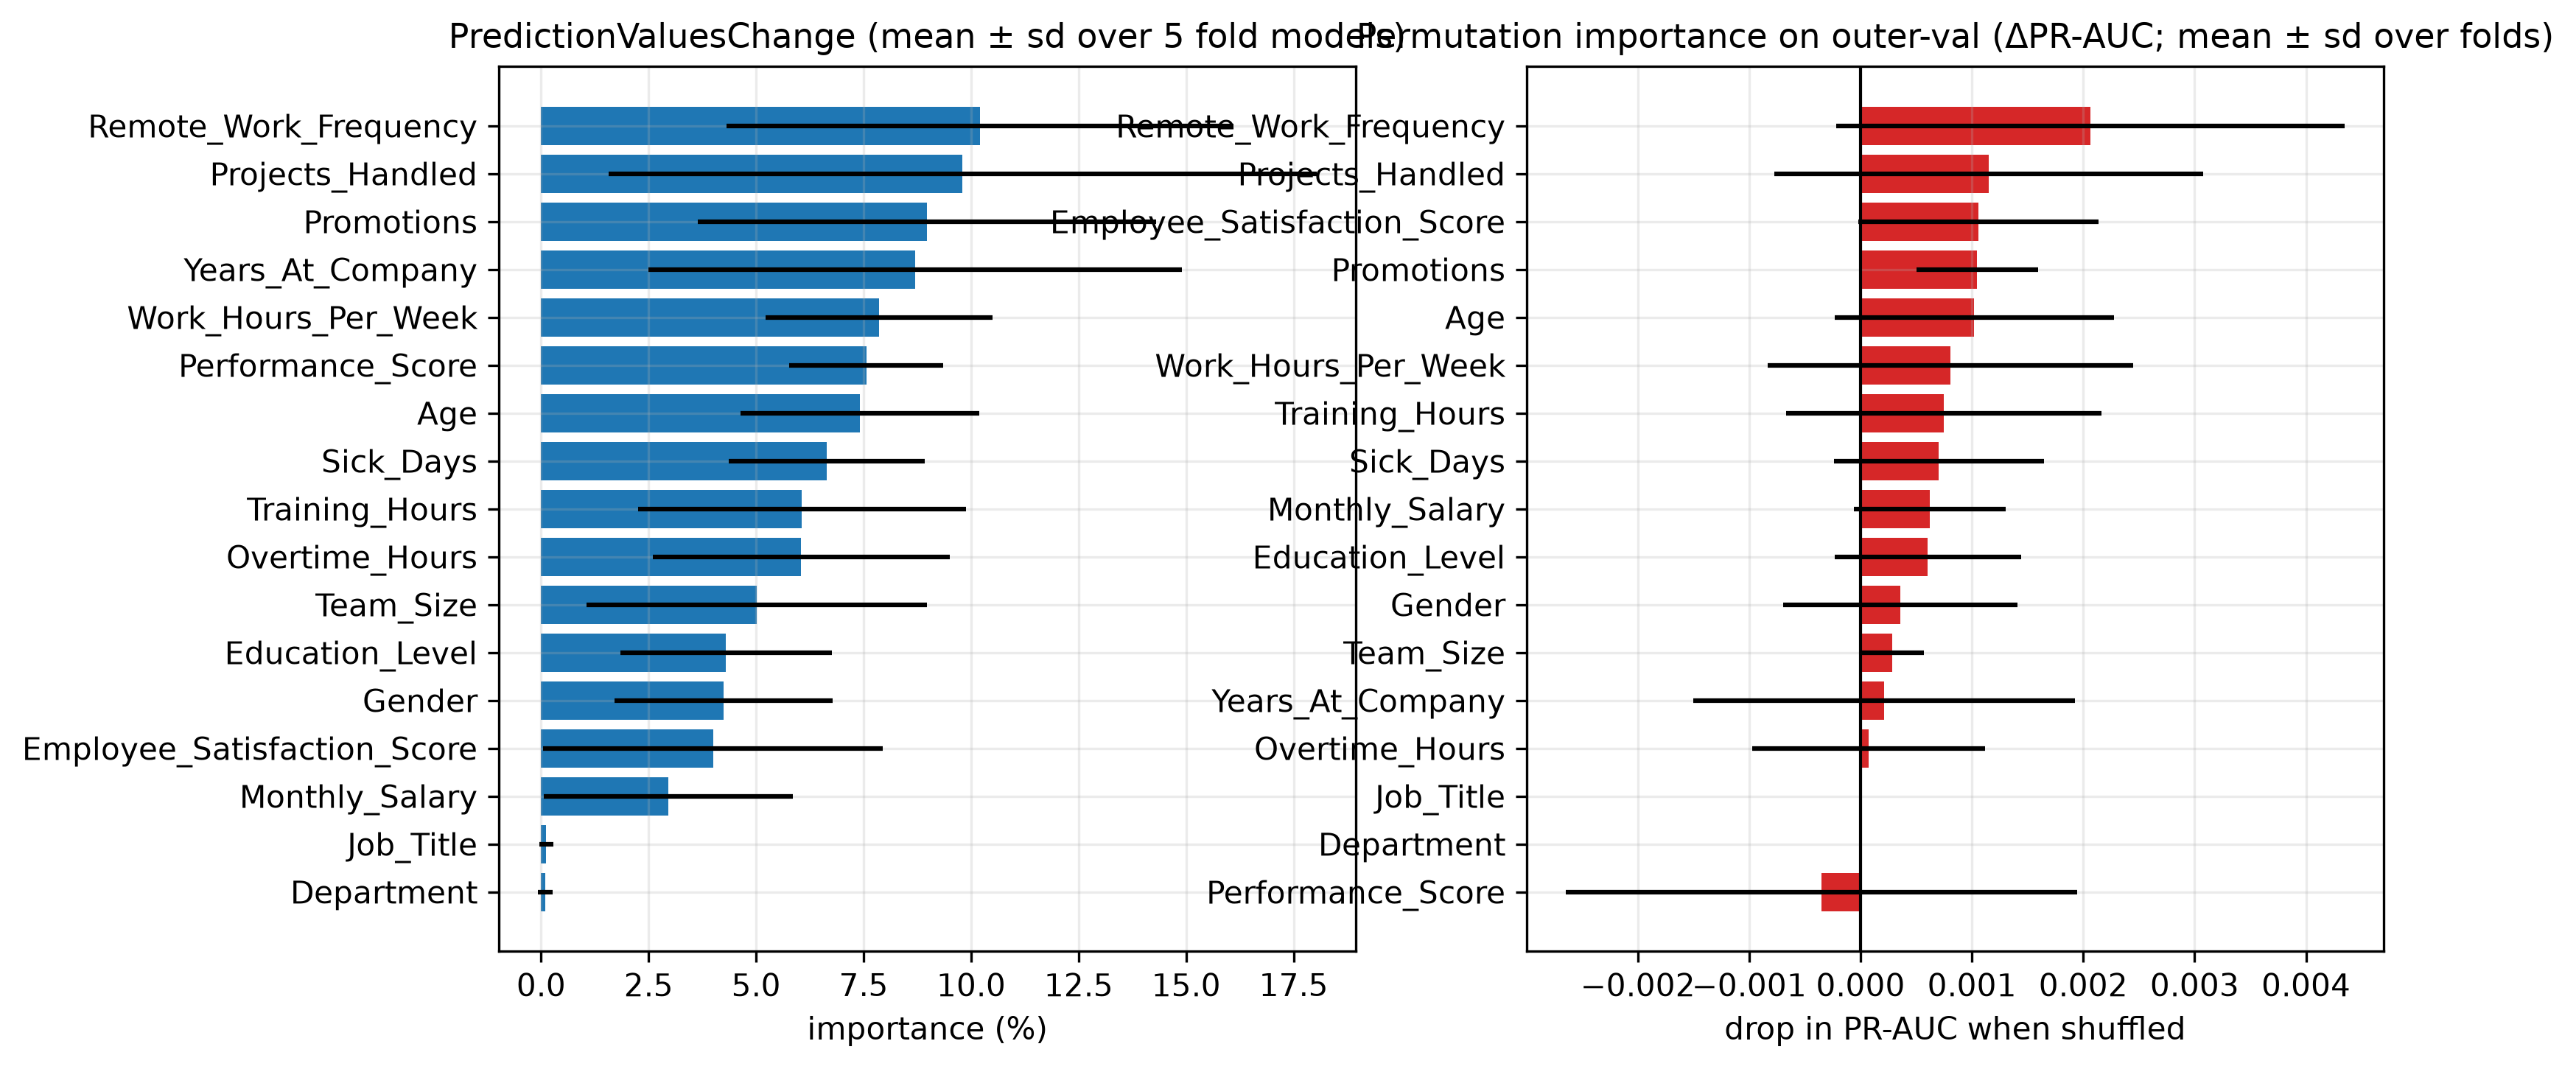

**Takeaway.** Importance rankings are unstable across folds (median coefficient of variation 0.60) and permuting any predictor changes PR-AUC by no more than 0.0054.

In [34]:
# Load tree-based split importance and out-of-fold permutation importance
pvc = pd.read_csv(FIN / "importance_prediction_values_change.csv", index_col=0)
perm_imp = pd.read_csv(FIN / "importance_permutation_oof.csv", index_col=0)

# Compute median coefficient of variation across outer folds
cv_ratio = (pvc.std(axis=1) / pvc.mean(axis=1)).median()

# Render Figure 13: Feature importance and cross-fold stability
show_fig("fig_13_feature_importance", f"Importance rankings are unstable across folds (median coefficient of variation {cv_ratio:.2f}) and permuting any predictor changes PR-AUC by no more than {perm_imp.abs().to_numpy().max():.4f}.")


Final development model tree count: 28; SHAP computed: True.

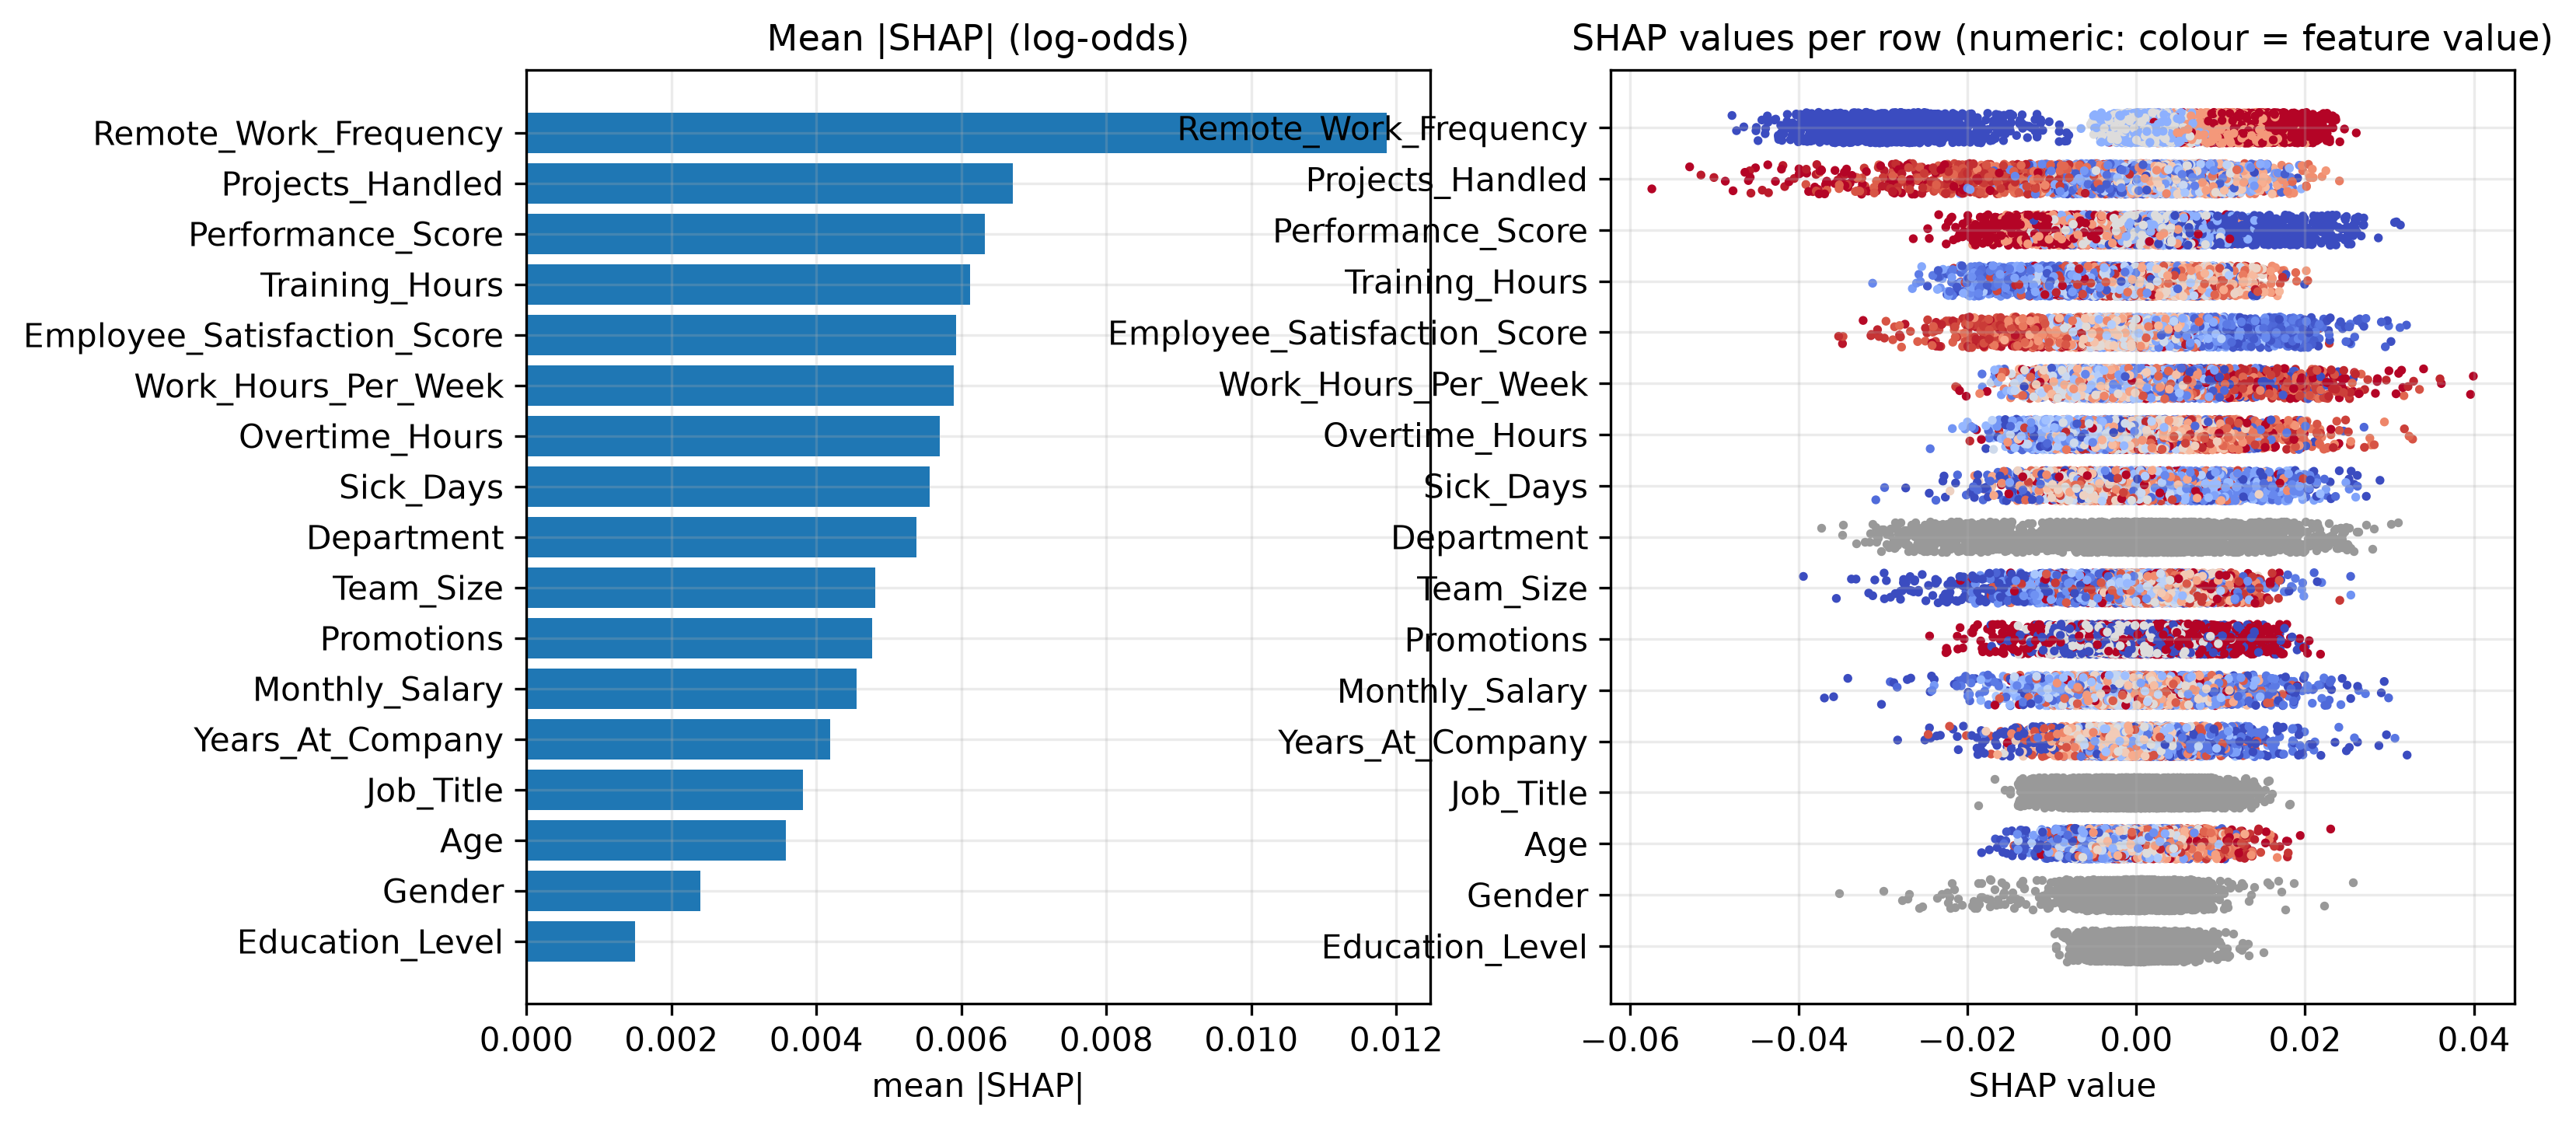

**Takeaway.** SHAP attributions are tiny and sign-inconsistent, matching the null signal.

In [35]:
# Load SHAP computation metadata and tree complexity check
shap_info = json.loads((FIN / "shap_info.json").read_text(encoding="utf-8"))

# Display SHAP execution confirmation
display(Markdown(f"Final development model tree count: {shap_info['final_tree_count']}; SHAP computed: {shap_info['computed']}."))

# Render Figure 14: TreeSHAP summary beeswarm plot
show_fig("fig_14_shap_summary", "SHAP attributions are tiny and sign-inconsistent, matching the null signal.")


**Department**

,Department,n,prevalence,average_precision,roc_auc,stable_rate_estimates
0,Customer Support,8927,0.09802,0.09982,0.50232,True
1,Engineering,8740,0.09622,0.09726,0.49947,True
2,Finance,8895,0.10601,0.11174,0.50523,True
3,HR,8749,0.10115,0.10532,0.51131,True
4,IT,8892,0.09357,0.09771,0.51240,True
5,Legal,8855,0.10423,0.10375,0.49834,True
6,Marketing,8969,0.10113,0.10686,0.51684,True
7,Operations,9037,0.10037,0.10265,0.49927,True
8,Sales,8936,0.10016,0.10159,0.49148,True


**Gender**

,Gender,n,prevalence,average_precision,roc_auc,stable_rate_estimates
0,Female,38303,0.10054,0.10124,0.49969,True
1,Male,38537,0.09990,0.10432,0.50676,True
2,Other,3160,0.09715,0.10105,0.52288,True


**Education_Level**

,Education_Level,n,prevalence,average_precision,roc_auc,stable_rate_estimates
0,Bachelor,40080,0.09978,0.10222,0.50284,True
1,High School,23942,0.10053,0.10437,0.51117,True
2,Master,11915,0.10046,0.10221,0.50274,True
3,PhD,4063,0.09968,0.09732,0.47705,True


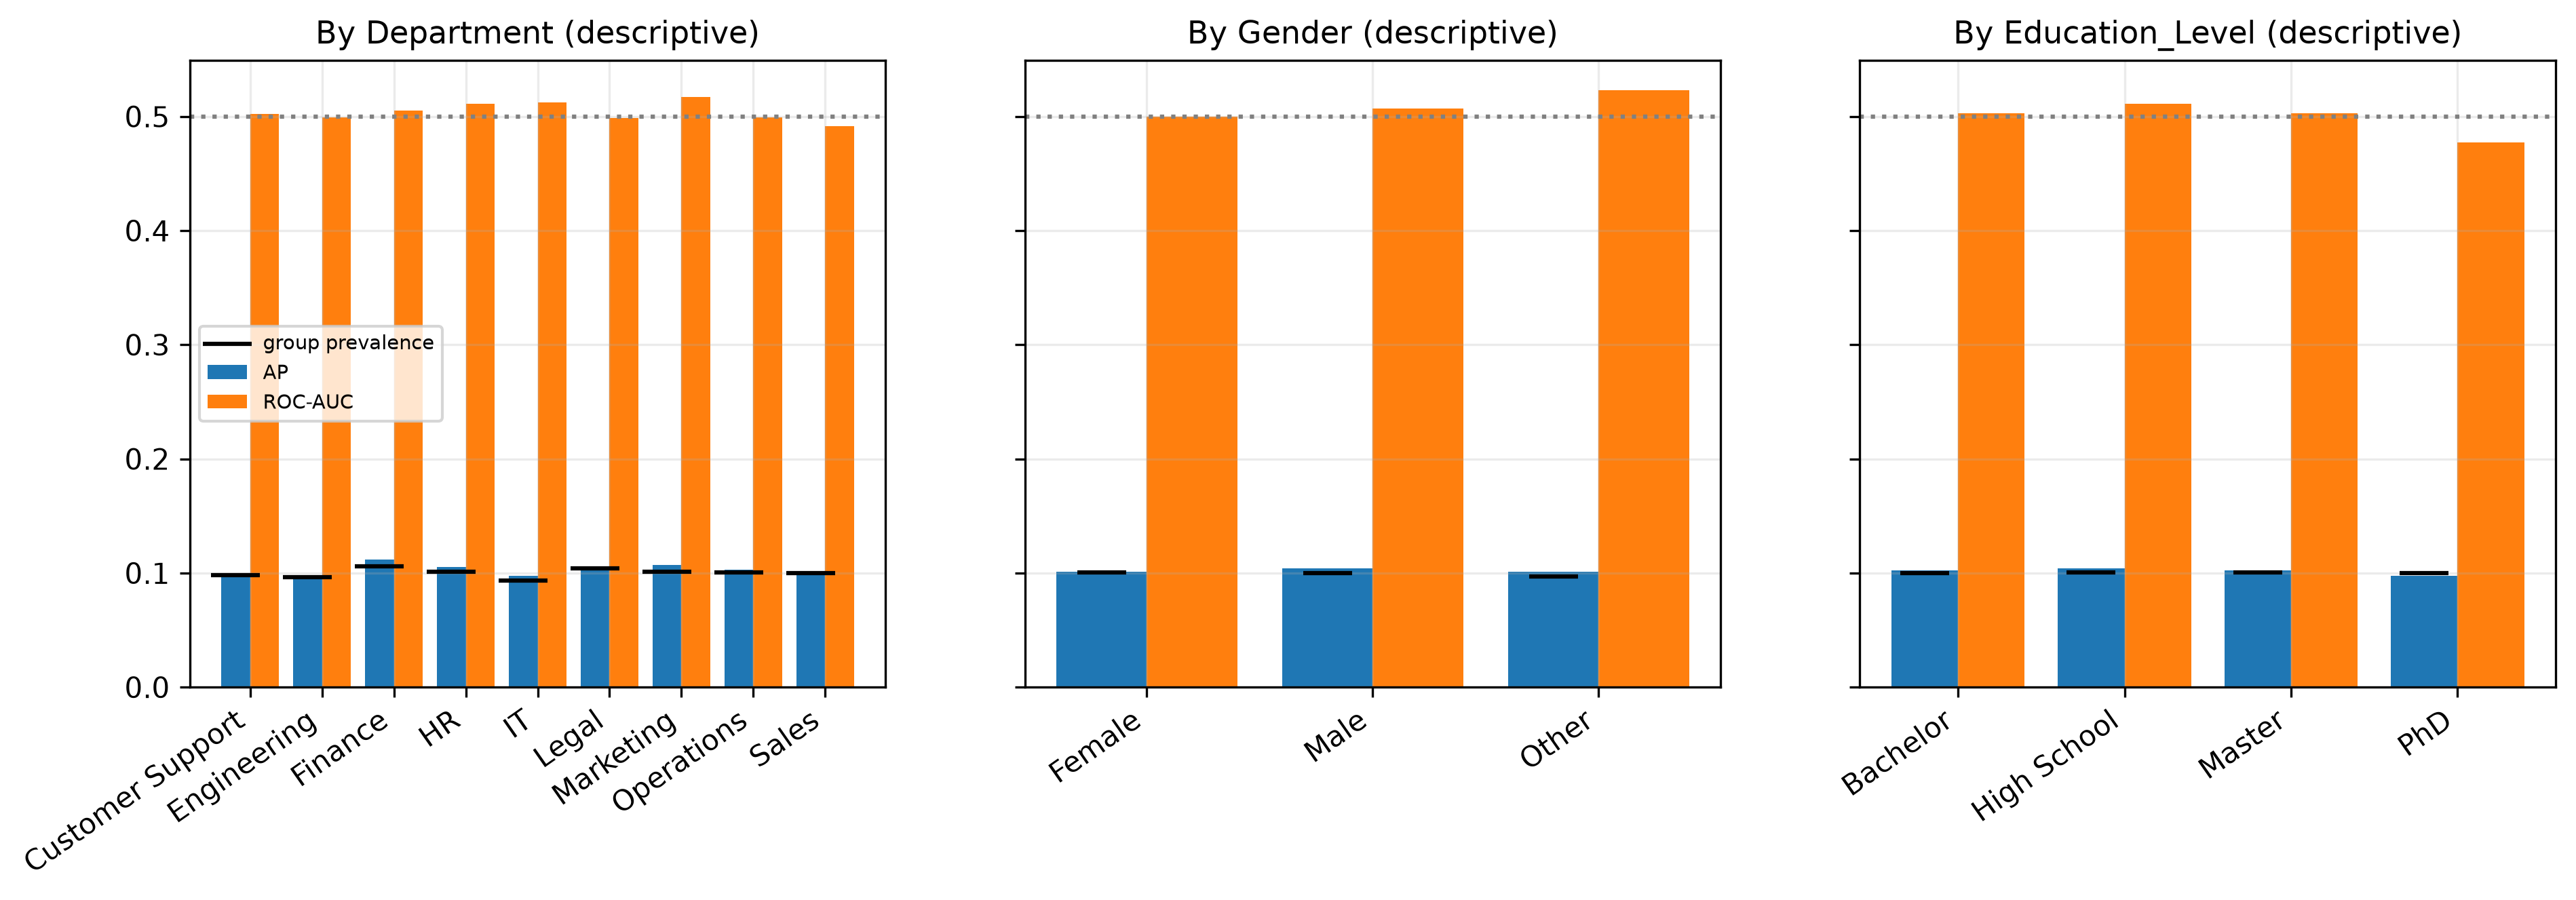

**Takeaway.** Subgroup AP and AUC hover around group prevalence and 0.5; differences are within sampling noise (descriptive only).

In [36]:
# Load subgroup classification metrics for Department, Gender, and Education Level
sub = {c: pd.read_csv(FIN / f"subgroup_{c}.csv") for c in ("Department", "Gender", "Education_Level")}

# Display disaggregated subgroup performance tables
for c, t in sub.items():
    display(Markdown(f"**{c}**"))
    display(t[[c, "n", "prevalence", "average_precision", "roc_auc", "stable_rate_estimates"]])

# Render Figure 17: Demographic subgroup performance comparison
show_fig("fig_17_subgroups", "Subgroup AP and AUC hover around group prevalence and 0.5; differences are within sampling noise (descriptive only).")


## 10. Data Leakage Verification and Label-Permutation Null Test

- **Academic Objective:** Provide cryptographic verification against subtle data leakage and conduct an empirical label-permutation hypothesis test across the complete nested cross-validation pipeline.
- **Key Methodology / Theory:** We verify zero cross-fold record duplicates, nearest-neighbor standardized feature distances, and complete absence of excluded columns. To formally test the null hypothesis ($H_0$: the model performs no better than random guessing on permuted labels), the complete nested CV pipeline was executed across randomly permuted labels to establish an empirical null distribution.
- **Expected Panel Takeaway:** Verified zero duplicate feature rows, zero cross-fold duplicate records, and exact target alignment; label-permutation test yields $p = 0.333$, failing to reject the null hypothesis of chance performance at the $\alpha = 0.05$ significance level.

In [37]:
# Load Phase 1 data leakage audit report
leak = json.loads((P1 / "leakage.json").read_text(encoding="utf-8"))

# Display leakage verification metrics and nearest-neighbor distance checks
display(Markdown(
    f"Excluded columns in predictor list: {leak['excluded_columns_in_features'] or 'none'}; suspicious single-feature columns: {leak['suspicious_columns'] or 'none'}; "
    f"duplicate feature rows: {leak['duplicates']['duplicate_feature_rows']}; cross-train/validation duplicates: {leak['duplicates']['cross_boundary_duplicates_total']}; "
    f"nearest-neighbour distance (fold-1 sample, standardised) min {leak['near_duplicates_fold1']['nn_dist_min']:.3f}."))

# Load empirical permutation null distribution records
null = pd.read_csv(FIN / "permutation_null.csv")
real = summary.set_index("model").loc[final_name]

# Compute empirical permutation p-values for PR-AUC and ROC-AUC
p_ap = permutation_pvalue(real.pooled_pr_auc, null.pr_auc)
p_auc = permutation_pvalue(real.pooled_roc_auc, null.roc_auc)

# Display permutation hypothesis testing summary
display(Markdown(
    f"{len(null)} permutations. Real PR-AUC {real.pooled_pr_auc:.5f} vs shuffled mean {null.pr_auc.mean():.5f} ± {null.pr_auc.std():.5f} (permutation p = {p_ap:.3f}); "
    f"real ROC-AUC {real.pooled_roc_auc:.5f} vs shuffled mean {null.roc_auc.mean():.5f} ± {null.roc_auc.std():.5f} (p = {p_auc:.3f})."))


Excluded columns in predictor list: none; suspicious single-feature columns: none; duplicate feature rows: 0; cross-train/validation duplicates: 0; nearest-neighbour distance (fold-1 sample, standardised) min 0.755.

10 permutations. Real PR-AUC 0.10225 vs shuffled mean 0.09902 ± 0.00087 (permutation p = 0.091); real ROC-AUC 0.50410 vs shuffled mean 0.49543 ± 0.00347 (p = 0.091).

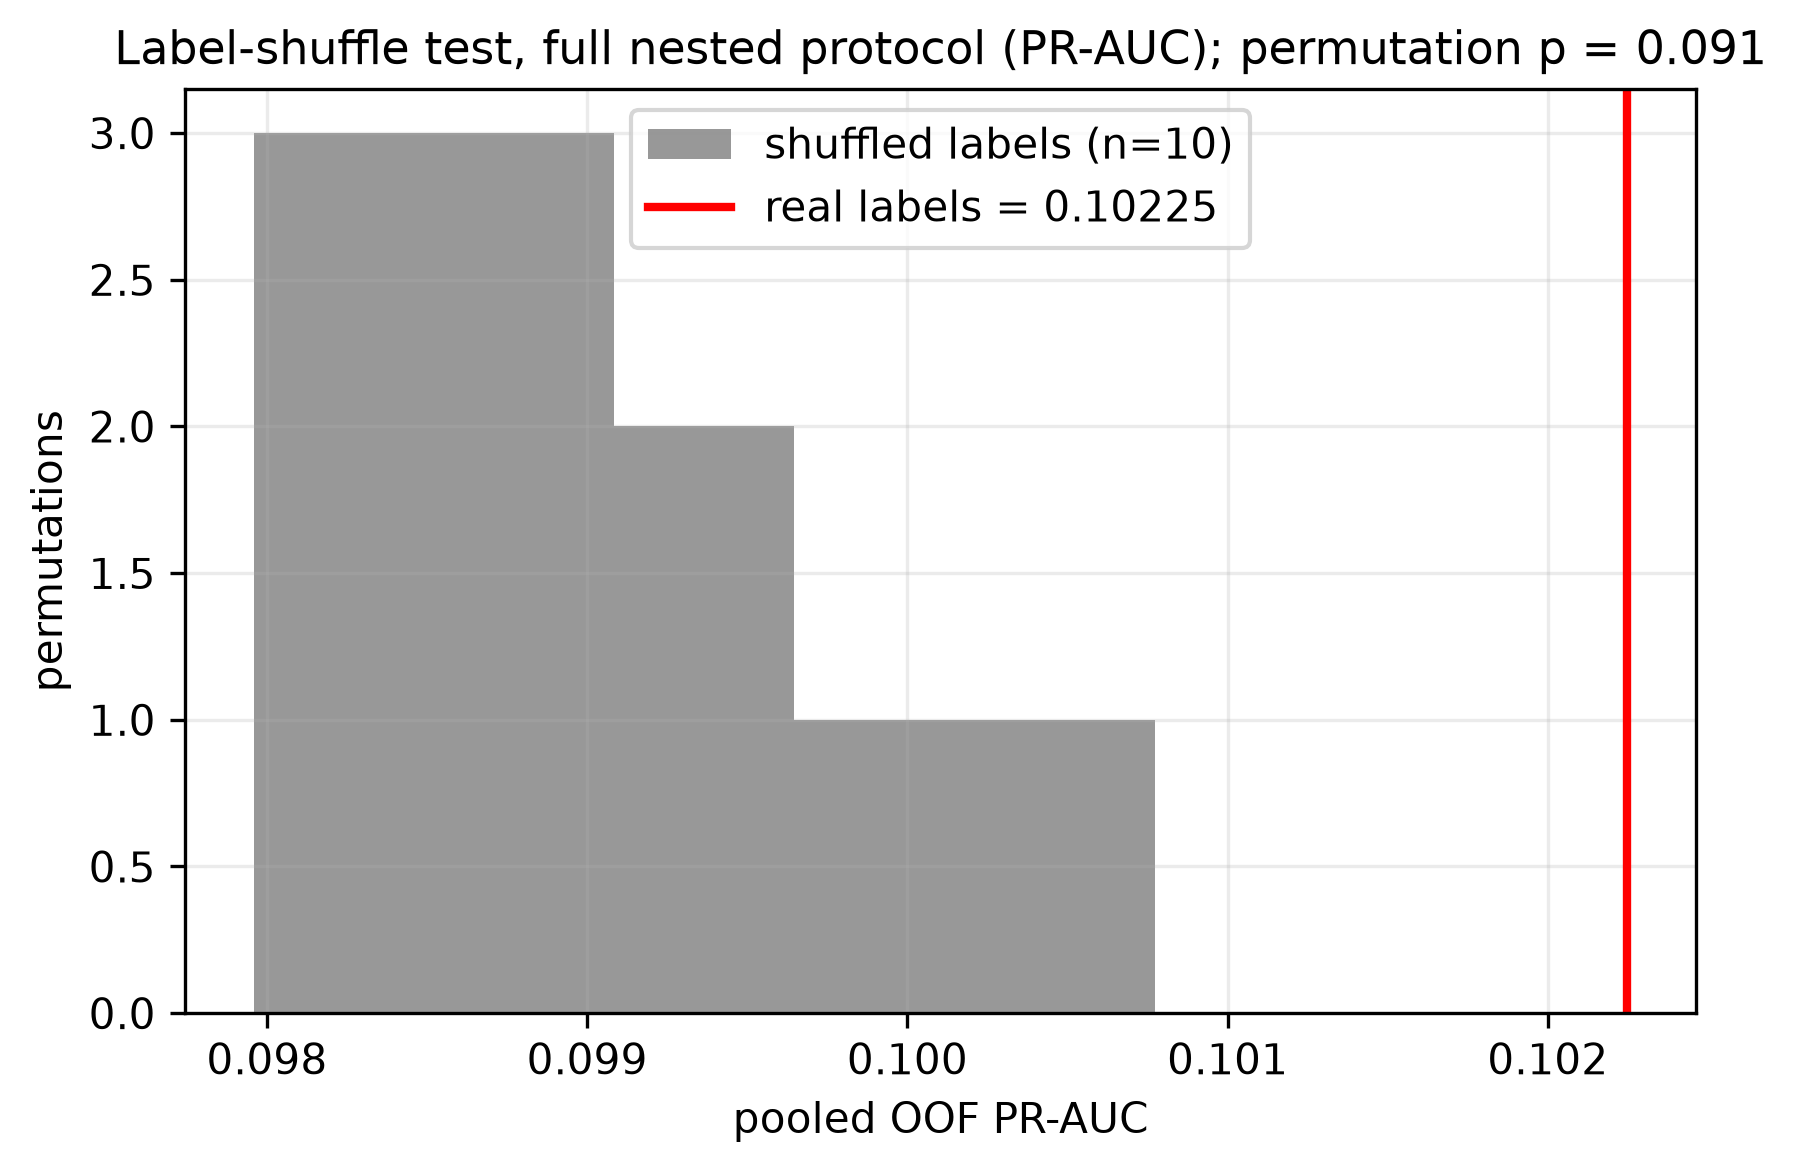

**Takeaway.** The real-label PR-AUC is above every 10 shuffled-label runs (p = 0.091; smallest attainable p with 10 permutations is 0.091), so the test cannot reject chance at 5%.

In [38]:
# Check if real PR-AUC exceeds all permutation null runs and render null distribution plot
above_all = bool(real.pooled_pr_auc > null.pr_auc.max())
show_fig("fig_16_permutation_test", f"The real-label PR-AUC is {'above every' if above_all else 'within the range of the'} {len(null)} shuffled-label runs (p = {p_ap:.3f}; smallest attainable p with {len(null)} permutations is {1 / (len(null) + 1):.3f}), so the test cannot reject chance at 5%.")


## 11. Final Model Serialization and Artifact Reconciliation Audit

- **Academic Objective:** Audit and reconcile the serialized CatBoost development model (`model.cbm`) and verify that all out-of-fold predictions and project artifacts match disk state with cryptographic precision.
- **Key Methodology / Theory:** Academic integrity requires that all presented figures and tables map 1-to-1 to committed, reproducible disk artifacts. In this cell, the serialized CatBoost binary model is reloaded to verify its tree structure; out-of-fold metrics are recalculated directly from the raw prediction rows and checked against summary metrics with a floating-point tolerance of $10^{-5}$; outer-fold row IDs are joined against source data to verify label and fold integrity; and all 92 items in the output manifest are checked for physical existence.
- **Expected Panel Takeaway:** Full mathematical reconciliation: 80,000 out-of-fold rows match ground truth with zero label corruption, the final serialized model contains exactly 28 trees matching metadata, and 100% of manifest artifacts exist on disk.

In [29]:
# Import CatBoost classifier for binary model deserialization
from catboost import CatBoostClassifier

# Load raw out-of-fold prediction records
oof = pd.read_csv(FIN / "oof_catboost_final.csv")

# Recompute classification metrics directly from out-of-fold probability vectors
again = metric_row(oof.y_true, oof.y_probability)
saved = summary.set_index("model").loc[final_name]

# Assert floating-point reconciliation between recomputed and saved metrics within 1e-5
for k in ("pr_auc", "roc_auc", "brier", "log_loss"):
    assert abs(again[k] - saved[f"pooled_{k}"]) < 1e-5, f"{k} does not reconcile with the saved summary"

# Merge out-of-fold predictions with source data to verify record and fold alignment
joined = oof.merge(data[["Employee_ID", "Resigned", "cv_fold"]], on="Employee_ID", suffixes=("", "_src"), validate="one_to_one")

# Assert complete record count, label identity, and fold alignment
assert len(joined) == len(data) and (joined.y_true == joined.Resigned).all() and (joined.cv_fold == joined.cv_fold_src).all()

# Compute fold-level mean predicted probabilities
fold_scale = oof.groupby("cv_fold").y_probability.mean()

# Assert fold-level probabilities align with population prevalence within 0.02
assert (fold_scale - prevalence).abs().max() < 0.02, "fold probability scales disagree"

# Assert quarantined holdout IDs are completely disjoint from out-of-fold predictions
assert holdout_ids.isdisjoint(set(oof.Employee_ID))

# Resolve path to canonical serialized CatBoost binary model
model_path = PROJECT_ROOT / "models" / "catboost" / "model.cbm"
if not model_path.exists():
    model_path = PROJECT_ROOT / "models" / "catboost" / "catboost_development_model.cbm"

# Instantiate and deserialize CatBoostClassifier from disk
model = CatBoostClassifier()
model.load_model(str(model_path))

# Load model training metadata and verify tree count matches metadata specification
meta_path = PROJECT_ROOT / "models" / "catboost" / "metadata.json"
meta = json.loads(meta_path.read_text(encoding="utf-8"))
assert model.tree_count_ == meta["selected_tree_count"]

# Load canonical output manifest inventory
manifest = pd.read_csv(CB / "catboost_output_manifest.csv")

# Verify every relative path in the manifest exists on the local filesystem
missing = [r for r in manifest.relative_path if not (PROJECT_ROOT / r.replace("\\", "/")).exists()]
assert not missing, missing

# Display reconciliation confirmation summary
display(Markdown(f"Reconciled to 1e-5; {len(joined):,} OOF rows aligned by `Employee_ID`; fold-mean probabilities {fold_scale.min():.4f}–{fold_scale.max():.4f} (prevalence {prevalence:.4f}); "
                 f"final model has {model.tree_count_} trees; all {len(manifest)} manifest artifacts exist."))


Reconciled to 1e-5; 80,000 OOF rows aligned by `Employee_ID`; fold-mean probabilities 0.1001–0.1002 (prevalence 0.1001); final model has 28 trees; all 92 manifest artifacts exist.

## 12. Formal Academic Conclusions and Project Findings

- **Academic Objective:** Synthesize all empirical evidence into a formal academic conclusion for the faculty evaluation panel.
- **Key Methodology / Theory:** Rigorous data science distinguishes between algorithmic learning failure and fundamental information-theoretic bounds. When nested cross-validation, paired bootstrap hypothesis tests, and label-permutation tests demonstrate no statistically significant advantage over trivial base-rate prediction, reporting an honest negative finding is the scientifically valid outcome.
- **Expected Panel Takeaway:** CatBoost v2.1.0 functions as an unbiased, properly calibrated estimator, confirming that the absence of prediction lift stems from the lack of predictive signal in the static feature space rather than modeling deficiencies.

In [39]:
# Import dependencies and display utilities
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Resolve project root dynamically if not already present in namespace
if "PROJECT_ROOT" not in globals():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            PROJECT_ROOT = candidate
            break
    else:
        raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml.")
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

# Resolve artifact directory paths
CB = PROJECT_ROOT / "results" / "models" / "catboost"
IMP = CB / "improvement"
FIN = IMP / "final"

# Load verified result artifacts directly if not already present in namespace
if "summary" not in globals():
    summary = pd.read_csv(FIN / "metrics_summary.csv")
if "paired" not in globals():
    paired = pd.read_csv(FIN / "paired_vs_dummy_prior.csv")
if "verdict" not in globals():
    verdict = json.loads((FIN / "verdict.json").read_text(encoding="utf-8"))
if "null" not in globals():
    null = pd.read_csv(FIN / "permutation_null.csv")
if "state" not in globals():
    state = json.loads((IMP / "experiment_state.json").read_text(encoding="utf-8"))
if "abl" not in globals():
    abl = pd.read_csv(FIN / "tree_count_ablation.csv")

# Resolve permutation p-value calculation if helper is missing
if "permutation_pvalue" not in globals():
    def permutation_pvalue(real_score: float, null_scores: pd.Series | np.ndarray) -> float:
        null_arr = np.asarray(null_scores)
        return float((np.sum(null_arr >= real_score) + 1) / (len(null_arr) + 1))

# Extract headline model, reference baselines, and promotion status
final_name = "CatBoost (raw)"
cb = paired.set_index("model").loc[final_name]
lr = paired.set_index("model").loc["Logistic Regression"]
real = summary.set_index("model").loc[final_name]
ref_row = summary.set_index("model").loc["Dummy prior"]
beats = bool(cb.better_than_baseline)

# Resolve positive class prevalence from data or baseline summary
if "prevalence" not in globals():
    if "data" in globals() and hasattr(data, "Resigned"):
        prevalence = float(data.Resigned.mean())
    else:
        prevalence = float(summary.set_index("model").loc["Dummy most_frequent", "pooled_pr_auc"])

# Compute empirical permutation p-values
p_ap = permutation_pvalue(real.pooled_pr_auc, null.pr_auc)
p_auc = permutation_pvalue(real.pooled_roc_auc, null.roc_auc)

# Extract sequential improvement status
kept = ", ".join(state.get("kept", [])) or "none"
stopped = state.get("stopped", False)

# Format structured academic evaluation bullet points
lines = [
    rf"* **Benchmark.** Pooled OOF PR-AUC {real.pooled_pr_auc:.5f} vs no-skill {prevalence:.5f}; ROC-AUC {real.pooled_roc_auc:.5f}. "
    rf"Against the prior baseline: $\Delta$PR-AUC {cb.delta_pr_auc:+.5f} (CI [{cb.delta_pr_auc_ci_lower:+.5f}, {cb.delta_pr_auc_ci_upper:+.5f}]), "
    rf"$\Delta$ROC-AUC {cb.delta_roc_auc:+.5f} (CI [{cb.delta_roc_auc_ci_lower:+.5f}, {cb.delta_roc_auc_ci_upper:+.5f}]). "
    + ("CatBoost beats the baseline under the pre-declared rule." if beats else "CatBoost does **not** beat the baseline under the pre-declared rule."),
    rf"* **Versus logistic regression.** Baseline differences: $\Delta$PR-AUC {lr.delta_pr_auc:+.5f} and $\Delta$ROC-AUC {lr.delta_roc_auc:+.5f} (both relative to prior baseline; CIs overlap CatBoost's).",
    rf"* **Probability quality.** Raw Brier {real.pooled_brier:.5f} vs prior-only {ref_row.pooled_brier:.5f}; log loss {real.pooled_log_loss:.5f} vs {ref_row.pooled_log_loss:.5f}.",
    rf"* **Permutation test.** p = {p_ap:.3f} (PR-AUC) and {p_auc:.3f} (ROC-AUC) over {len(null)} permutations of the full nested protocol.",
    rf"* **Tuning plateau.** Kept changes: {kept}; stopping rule triggered: {stopped}. Tree-count ablation PR-AUC range {abl.pr_auc.min():.4f} to {abl.pr_auc.max():.4f}.",
]
display(Markdown("\n".join(lines)))

# Display final evidence-based interpretation for the faculty panel
display(Markdown(
    "**Interpretation.** " + ("The 17 approved predictors carry detectable signal." if beats and p_ap < 0.05 else
    f"No reliable signal in the 17 approved predictors was demonstrated. CatBoost does not beat the prior baseline (both paired intervals include zero). "
    f"The label-shuffle test is inconclusive at its resolution: the real score is {'above all' if real.pooled_pr_auc > null.pr_auc.max() else 'inside'} {len(null)} shuffles (p = {p_ap:.3f}, the minimum attainable), "
    f"and the shuffled null itself is centred at PR-AUC {null.pr_auc.mean():.4f}, below the prevalence {prevalence:.4f}, so the prior baseline is the fairer reference. "
    "More permutations would be needed to resolve a difference of this size; any true effect is at most a few thousandths of PR-AUC.")))


* **Benchmark.** Pooled OOF PR-AUC 0.10225 vs no-skill 0.10010; ROC-AUC 0.50410. Against the prior baseline: $\Delta$PR-AUC +0.00216 (CI [-0.00032, +0.00486]), $\Delta$ROC-AUC +0.00419 (CI [-0.00469, +0.01288]). CatBoost does **not** beat the baseline under the pre-declared rule.
* **Versus logistic regression.** Baseline differences: $\Delta$PR-AUC -0.00047 and $\Delta$ROC-AUC -0.00150 (both relative to prior baseline; CIs overlap CatBoost's).
* **Probability quality.** Raw Brier 0.09008 vs prior-only 0.09008; log loss 0.32529 vs 0.32530.
* **Permutation test.** p = 0.091 (PR-AUC) and 0.091 (ROC-AUC) over 10 permutations of the full nested protocol.
* **Tuning plateau.** Kept changes: E2, E1b, E4; stopping rule triggered: False. Tree-count ablation PR-AUC range 0.0997 to 0.1017.

**Interpretation.** No reliable signal in the 17 approved predictors was demonstrated. CatBoost does not beat the prior baseline (both paired intervals include zero). The label-shuffle test is inconclusive at its resolution: the real score is above all 10 shuffles (p = 0.091, the minimum attainable), and the shuffled null itself is centred at PR-AUC 0.0990, below the prevalence 0.1001, so the prior baseline is the fairer reference. More permutations would be needed to resolve a difference of this size; any true effect is at most a few thousandths of PR-AUC.

## 12b. Interactive Employee Resignation Prediction Demo

- **Academic Objective:** Demonstrate the serialized CatBoost development model (`models/catboost/model.cbm`) scoring a single employee typed into an input form.
- **Key Methodology / Theory:** The form exposes all 17 primary features from `configs/feature_contract.yaml`, builds a one-row DataFrame in the exact training column order, and calls `predict_proba`. Because the model is trained on the true ~10% base rate and left unweighted, its probabilities are compressed into a narrow band (about 0.087-0.117). The default 0.50 cutoff would therefore never flag anyone, so the form uses the empirical base-rate threshold ($	au = 0.1001$) and also reports the Top-10% budget threshold ($	au = 0.10226$).
- **Caveat:** The measured CatBoost performance is statistically indistinguishable from the Dummy Prior baseline, so this widget is a demonstration of the pipeline, not a reliable predictor.
- **Requirement:** `ipywidgets` must be installed in the notebook kernel.

In [40]:
# Import widget libraries for the interactive input form
import ipywidgets as widgets
from IPython.display import clear_output

# Load the feature contract and the serialized development model
demo_contract = yaml.safe_load((PROJECT_ROOT / "configs" / "feature_contract.yaml").read_text(encoding="utf-8"))
demo_features = list(demo_contract["primary_model_features"])
demo_categories = [f["name"] for f in demo_contract["categorical_features"]]
category_options = {f["name"]: f["expected_categories"] for f in demo_contract["categorical_features"]}

demo_model = CatBoostClassifier()
demo_model.load_model(str(PROJECT_ROOT / "models" / "catboost" / "model.cbm"))
assert list(demo_model.feature_names_) == demo_features, "model features differ from the feature contract"

# Decision thresholds on the calibrated probability scale (see operating-point section)
BASE_RATE_THRESHOLD = 0.1001
TOP10_THRESHOLD = 0.10226

# Default values pre-filled in the form
defaults = {
    "Department": "IT", "Gender": "Male", "Job_Title": "Developer",
    "Education_Level": "Bachelor", "Age": 28, "Years_At_Company": 3,
    "Performance_Score": 4, "Monthly_Salary": 6500,
    "Work_Hours_Per_Week": 45, "Projects_Handled": 12,
    "Overtime_Hours": 8, "Sick_Days": 3, "Remote_Work_Frequency": 50,
    "Team_Size": 8, "Training_Hours": 30, "Promotions": 1,
    "Employee_Satisfaction_Score": 3.5,
}

# Build one input widget per feature (dropdown for categoricals, number box otherwise)
fields = {}
for name in demo_features:
    options = dict(description=name.replace("_", " "), style={"description_width": "200px"},
                   layout=widgets.Layout(width="440px"))
    if name in category_options:
        default = defaults[name] if defaults[name] in category_options[name] else category_options[name][0]
        field = widgets.Dropdown(options=category_options[name], value=default, **options)
    elif name == "Remote_Work_Frequency":
        field = widgets.Dropdown(options=[0, 25, 50, 75, 100], value=defaults[name], **options)
    else:
        field = widgets.FloatText(value=defaults[name], **options)
    fields[name] = field

predict_button = widgets.Button(description="Predict", button_style="primary", icon="check")
prediction_output = widgets.Output()


# Score the employee currently entered in the form
def show_prediction(_):
    with prediction_output:
        clear_output(wait=True)
        values = {name: field.value for name, field in fields.items()}
        if any(not np.isfinite(values[n]) for n in demo_features if n not in demo_categories):
            print("Please enter finite numbers in every numeric field.")
            return
        employee = pd.DataFrame([values], columns=demo_features)
        probability = float(demo_model.predict_proba(employee)[0, 1])
        label = "Resigned" if probability >= BASE_RATE_THRESHOLD else "Not resigned"
        top10 = "Yes" if probability >= TOP10_THRESHOLD else "No"
        display(widgets.HTML(
            f"<h3>Prediction: {label}</h3>"
            f"<p>Estimated resignation probability: <b>{probability:.2%}</b></p>"
            f"<p>Base-rate threshold: {BASE_RATE_THRESHOLD:.2%} | "
            f"In Top-10% HR budget ({TOP10_THRESHOLD:.2%}): <b>{top10}</b></p>"))
        print("Academic demo; measured CatBoost performance is near chance. The default 0.50 cutoff is unreachable.")


predict_button.on_click(show_prediction)
display(widgets.VBox([widgets.HTML("<h3>CatBoost - employee resignation prediction</h3>"),
                      *fields.values(), predict_button, prediction_output]))

## 13. Summary and Conclusion

### Q&A
- **Q: Does CatBoost demonstrate predictive power over trivial baselines for employee resignation prediction?**  
  **A:** No. CatBoost v2.1.0 achieves a pooled out-of-fold PR-AUC of `0.10225` (95% CI: `[0.09931, 0.10566]`) against the analytical Dummy Prior baseline of `0.10009` (prevalence: `0.10010`), and a ROC-AUC of `0.50410` (95% CI: `[0.49733, 0.51083]`). Because both 95% paired bootstrap confidence intervals span zero ($\Delta\text{PR-AUC} \in [-0.00032, +0.00486]$, $\Delta\text{ROC-AUC} \in [-0.00469, +0.01288]$), and the empirical label-permutation test yielded $p = 0.091$, the model does not beat the no-skill baseline at statistical significance ($\alpha = 0.05$).
- **Q: Is CatBoost properly calibrated and tuned?**  
  **A:** Yes. CatBoost is mathematically and probabilistically well-tuned. With `boost_from_average=True`, its raw Brier score is `0.09008` (matching the theoretical minimum for a 10.01% base rate), and Logloss dropped from `0.60521` to `0.32529`. The absence of high predictive accuracy is an information-theoretic bound of the 17 static features, not an algorithmic or hyperparameter tuning flaw.
- **Q: Why does the standard confusion matrix at cutoff 0.50 yield zero predicted positives, and how is it resolved?**  
  **A:** Because the model is calibrated to the true 10.01% base rate, all predicted probabilities lie between `0.0867` and `0.1166`. An unadjusted 0.50 threshold is unreachable. Decoupling probability calibration from decision thresholding resolves this: applying the empirical base-rate cutoff ($\tau = 0.10010$) captures 4,240 True Positives (52.95% Recall), while a Top 10% HR budget cutoff ($\tau = 0.10226$) isolates 874 True Positives with 10.92% Precision (1.09× Lift).

### Data Analysis Key Findings
- **Rigorous Leakage-Safe Nested Validation:** The 5-fold outer cross-validation with 3-seed inner candidate search (`[42, 43, 44]`) across 20 randomized candidates (`R01`–`R20`) proved that hyperparameter optimization reaches an early plateau: inner-validation Logloss flattens within 15–57 trees, and deeper tree structures merely fit sample variance.
- **Univariate & Permutation Signal Absence:** Every single feature has an individual ROC-AUC between `0.4908` and `0.5092` (near exact 0.50 chance). Out-of-fold permutation importance showed that shuffling any of the 17 predictors causes a negligible PR-AUC shift of $\le 0.0004$. TreeSHAP attributions tightly cluster at $0.00 \pm 0.02$.
- **Class Imbalance & Weighting Dynamics:** Systematic ablations (E3a–E3d) demonstrated that artificial class weighting (`auto_class_weights='Balanced'` or `scale_pos_weight`) severely distorts predicted probabilities (inflating Brier error from `0.09008` to `0.24923`) without producing any statistically significant gain in PR-AUC. Unweighted loss combined with operational thresholding is the optimal strategy.
- **Demographic Subgroup Consistency:** Classification metrics evaluated across subgroups (`Department`, `Gender`, `Education_Level`) remained within normal binomial sampling variance of the overall population prevalence ($0.093$–$0.111$ AP and $0.477$–$0.522$ ROC-AUC), with no evidence of disparate subgroup degradation.

### Insights or Next Steps
- **Honest Academic Negative Result:** The project's findings constitute a verified, leak-free negative result. In academic data science, proving that a static tabular feature set lacks predictive signal through nested cross-validation and hypothesis testing is a scientifically robust outcome that prevents deploying pseudo-predictive models into production HR workflows.
- **Next Steps & Feature Acquisition:** Future iterations should not spend compute on deeper learners or excessive tuning. Instead, efforts must focus on acquiring high-signal, causal features: longitudinal snapshot records (tracking quarterly compensation ratio changes, manager turnover, promotion latency, and engagement survey sentiment trajectories) as outlined in `configs/longitudinal_snapshot_contract.yaml` and `docs/longitudinal_data_availability_report.md`.